# Other experiments — research archive

**Purpose:** Preserve the original foundations and earlier investigations without mixing their claims with the main reduced-hourly method.

This is intentionally the longer archive. Run from the top only when reproducing the historical workflow; some scaling studies are expensive. The newer combined comparison at the end is standalone. Original code and recorded outputs are retained. The main three notebooks do not depend on this archive.

- [Original foundations](#archive-foundations): hand schedule, MILP, QUBO, hourly QAOA and random controls.
- [Earlier comparisons](#earlier-experiments): five/ten plants and initial candidate windows.
- [Stretch studies](#stretch-studies): ramps, batteries, scaling and earlier renewable experiments.
- [Hardware workflow](#original-hardware): explicit opt-in; remote execution is disabled by default.
- [Other hybrids](#other-hybrids): older multi-hour and MILP-assisted experiments.
- [Combined comparison](#final-reduced-refinement): optional, separate from the main method.

[Main method](../solution/reduced_qubit_hybrid_hourly.ipynb) · [Window selection](quantum_window_selection.ipynb) · [Solar + wind](solar_wind.ipynb) · [Other experiments](research_archive.ipynb)

Use the **qBraid-SDK kernel**. The setup cell resolves the project paths automatically. No other notebook needs to be run first. Existing outputs below were copied from the original starter; they are recorded results, not fresh executions of this split. The original studies are preserved in the [research archive](../experiments/research_archive.ipynb); no other notebook is a runtime dependency. End times are exclusive: **13:00–18:00 means hours 13, 14, 15, 16, 17**.


In [ ]:
# Resolve data and shared helpers when opening a notebook from its own folder.
from pathlib import Path
import os
import sys
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src/check.py').is_file() and (p / 'data').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook inside the cloned project.')
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
os.chdir(PROJECT_ROOT)


<a id="archive-foundations"></a>
## Original foundations


In [ ]:
# Remote jobs are opt-in; leaving these False keeps Run All from submitting them.
RUN_HARDWARE = False
RUN_REMOTE_MIMIQ = False


# TVA plant scheduling: starter notebook

Every day TVA decides which power plants to switch on for each hour of tomorrow, so supply covers demand plus a safety margin (the **reserve**). This is called **unit commitment**. The on/off choices are the hard yes-or-no part. Once they are made, setting each plant's output (**economic dispatch**) is easy classical math, and `check.py` does it for you.

| Section | Milestone | What you do |
|---|---|---|
| 1 | 1 | Load 5 plants and 24 hours of demand. Schedule 6 hours by hand. |
| 2 | 2 | Classical baseline: an exact MILP (provided) and a cheapest-first rule (**cost heuristic**). |
| 3 | 3 | Write one hour as a QUBO (**hourly costs and QUBO**) and check it by brute force. |
| 4 | 4 | Solve one hour with QAOA on a simulator. |
| 5 and 6 | 4 and 6 | Run QAOA hour by hour for the whole day. Compare with the baseline. |
| 7 | 5 | Run one hour on IonQ hardware through qBraid. |

The cost heuristic and QUBO implementations are complete. Run the foundation cells in order.

> **Before you run anything, pick the kernel.** When this notebook opens, a **Select Kernel** box appears with *Python 3 (ipykernel)* already selected. That's the wrong one: change it to **qBraid-SDK (v0.12.2)**, then click **Select**. Picked the wrong one, or closed the box? Click the kernel name at the top right of the notebook and choose **qBraid-SDK (v0.12.2)**. The first cell checks, and tells you if it's wrong.

In [ ]:
# Use the qBraid-SDK (v0.12.2) kernel. This stops with a clear message if another one is picked.
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

# Qiskit Aer is Qiskit's simulator. It runs right here in your Lab instance: instant, free and noise-free,
# with no remote job. Select an environment that already includes it.
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    raise ImportError("Use a qBraid environment with qiskit-aer installed.")

import time

import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import minimize
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

from check import (load_plants, load_demand, solve_milp, check_schedule, check_hour,
                   hour_ok, hour_cost, locks)

plants = load_plants()              # data/plants.csv
demand, reserve = load_demand()     # data/demand.csv (MW for each of the 24 hours)
N = len(plants)                     # 5 plants
names = [p["plant_id"] for p in plants]
hours = np.arange(len(demand))
COLORS = {"milp": "#2a78d6", "qaoa": "#eb6834", "rule": "#1baf7a", "random": "#8a8984"}
print(f"{N} plants, {len(demand)} hours")

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

5 plants, 24 hours
Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


## 1. The plants and the demand

Each row of `data/plants.csv` is one plant, built from a real unit in the RTS-GMLC test grid (see `data/README.md`).

| Column | Meaning |
|---|---|
| `pmin_mw`, `pmax_mw` | When on, the plant makes between pmin and pmax MW |
| `marginal_cost_per_mwh` | Fuel cost of each extra MWh |
| `no_load_cost_per_h` | Cost per hour of just being on |
| `startup_cost` | Paid each time the plant switches on |
| `min_up_h`, `min_down_h` | Once on, it stays on this many hours. Once off, it stays off this many hours. |
| `on_at_start` | 1 if the plant is already running at midnight |

One hour of a plant that is on costs: no-load cost + marginal cost × output, plus the startup cost if it just switched on.

plant     type                              pmin  pmax   $/MWh  no-load $/h  startup $  min up  min down
COAL      coal steam                         140   350   21.69          546     36,750     24h       48h
GAS_CC    gas combined cycle                 168   350   26.84          206     27,650      8h        5h
PEAKER_A  gas combustion turbine              20    50   28.89          443      5,150      3h        3h
PEAKER_B  gas combustion turbine (older)      20    50   39.51          749      5,150      3h        3h
OIL       oil combustion turbine              20    50  101.02          694        130      1h        1h


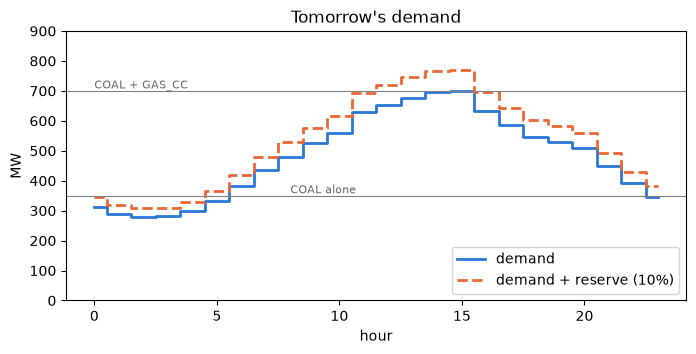

In [ ]:
print(f"{'plant':<10}{'type':<32}{'pmin':>6}{'pmax':>6}{'$/MWh':>8}{'no-load $/h':>13}"
      f"{'startup $':>11}{'min up':>8}{'min down':>10}")
for p in plants:
    print(f"{p['plant_id']:<10}{p['type']:<32}{p['pmin_mw']:>6.0f}{p['pmax_mw']:>6.0f}"
          f"{p['marginal_cost_per_mwh']:>8.2f}{p['no_load_cost_per_h']:>13,.0f}"
          f"{p['startup_cost']:>11,.0f}{p['min_up_h']:>7.0f}h{p['min_down_h']:>9.0f}h")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.step(hours, demand, where="mid", color=COLORS["milp"], lw=2, label="demand")
ax.step(hours, demand + reserve, where="mid", color=COLORS["qaoa"], lw=2, ls="--",
        label="demand + reserve (10%)")
for level, text, x in [(350, "COAL alone", 8), (700, "COAL + GAS_CC", 0)]:
    ax.axhline(level, color="gray", lw=0.8)
    ax.text(x, level + 8, text, color="dimgray", fontsize=8)
ax.set(xlabel="hour", ylabel="MW", title="Tomorrow's demand", ylim=(0, 900))
ax.legend(loc="lower right")
plt.show()

### Milestone 1: schedule 6 hours by hand

Edit `my_schedule`: one row per hour (hours 0 to 5), one column per plant, 1 = on. The checker prints the cost and any rules broken. How close you are to the best possible is yours to find out in Milestone 2. A spreadsheet works too.

In [ ]:
#               COAL  GAS_CC  PEAKER_A  PEAKER_B  OIL
my_schedule = [[1,    0,      0,        0,        0],   # hour 0
               [1,    0,      0,        0,        0],   # hour 1
               [1,    0,      0,        0,        0],   # hour 2
               [1,    0,      0,        0,        0],   # hour 3
               [1,    0,      0,        0,        0],   # hour 4
               [1,    0,      0,        0,        1]]   # hour 5: OIL adds capacity for reserve

hand_result = check_schedule(plants, demand[:6], reserve[:6], my_schedule)

Total cost: $44,555  (startups $130, no-load $3,970, energy $40,455)
Valid: every hour meets demand and reserve; no min up/down rule is broken.


## 2. Classical baseline (Milestone 2)

**MILP** (mixed-integer linear program): the standard classical tool for unit commitment. The costs and rules are written as linear equations over on/off variables and outputs, and a solver (HiGHS, inside scipy) finds the provably cheapest schedule. Ours is `solve_milp` in `check.py`, about 60 lines. Read it once.

MILP solved in 0.050 s
Total cost: $327,924  (startups $32,930, no-load $20,178, energy $274,816)
MILP optimum: $327,924   gap: +0.00%
Valid: every hour meets demand and reserve; no min up/down rule is broken.


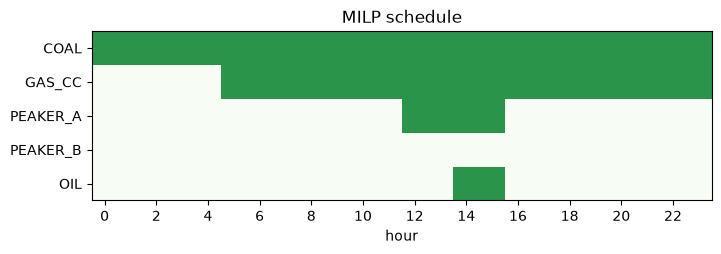

In [ ]:
milp_cost, milp_schedule, milp_dispatch, secs = solve_milp(plants, demand, reserve)
print(f"MILP solved in {secs:.3f} s")
milp_result = check_schedule(plants, demand, reserve, milp_schedule, milp_cost=milp_cost)


def plot_schedule(schedule, title, ax=None):
    # Green = on. One row per plant, one column per hour.
    if ax is None:
        ax = plt.subplots(figsize=(8, 2.2))[1]
    ax.imshow(np.asarray(schedule).T, aspect="auto", cmap="Greens", vmin=0, vmax=1.4)
    ax.set_yticks(range(N), names)
    ax.set_xticks(range(0, len(demand), 2))
    ax.set_xlabel("hour")
    ax.set_title(title)
    return ax


plot_schedule(milp_schedule, "MILP schedule")
plt.show()

### Cheapest-first rule

A rule a person might use: rank plants by cost per MWh at full output, then each hour switch plants on down the list until capacity covers demand + reserve.

- Cost per MWh at full output = `marginal_cost_per_mwh + no_load_cost_per_h / pmax_mw`.
- `np.argsort(values)` gives plant indices from cheapest to most expensive.
- For each hour `t`, add plants in that order until the sum of their `pmax_mw` is at least `demand[t] + reserve[t]`.

The rule ignores startup costs and min up/down times. Look at what that costs, and which rules it breaks.

Total cost: $330,594  (startups $37,950, no-load $20,288, energy $272,356)
MILP optimum: $327,924   gap: +0.81%
NOT valid: 1 rule(s) broken
  hour  plant      rule             detail
    16  PEAKER_B   min up broken    turned off after 2 h on (needs 3)


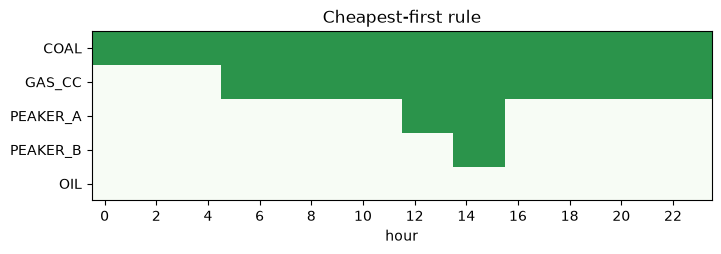

In [ ]:
def cheapest_first(plants, demand, reserve):
    schedule = np.zeros((len(demand), len(plants)), dtype=int)

    # Rank plants by cost per MWh at full output.
    costs = [
        p["marginal_cost_per_mwh"]
        + p["no_load_cost_per_h"] / p["pmax_mw"]
        for p in plants
    ]
    order = np.argsort(costs)

    # Turn plants on in that order until capacity is sufficient.
    for t in range(len(demand)):
        capacity = 0.0
        required = demand[t] + reserve[t]

        for i in order:
            if capacity >= required:
                break

            schedule[t, i] = 1
            capacity += plants[i]["pmax_mw"]

    return schedule


rule_schedule = cheapest_first(plants, demand, reserve)
rule_result = check_schedule(plants, demand, reserve, rule_schedule, milp_cost=milp_cost)
plot_schedule(rule_schedule, "Cheapest-first rule")
plt.show()

## 3. One hour as a QUBO (Milestone 3)

The completed six-node [QAOA primer](../milestones/03_max_cut_primer.ipynb) explains the cost layer, mixer and classical angle optimizer used here.

**QUBO** (quadratic unconstrained binary optimization): a cost function over 0/1 variables that has only single terms and pair terms. The QAOA code in this notebook takes the problem in this form.

One hour uses 8 qubits:

| Qubits | Meaning |
|---|---|
| 0 to 4 | $x_i = 1$ if plant $i$ is on (COAL, GAS_CC, PEAKER_A, PEAKER_B, OIL) |
| 5 to 7 | helper (slack) bits $s_0, s_1, s_2$ for the safety-margin rule |

QAOA should find the bits with the lowest energy

$$E = \sum_i c_i x_i + A \Big(\sum_i a_i x_i - (s_0 + 2 s_1 + 4 s_2) - r\Big)^2$$

- $c_i$ is the cost of having plant $i$ on this hour (hourly cost coefficients).
- The rule is "capacity of the plants that are on ≥ demand + reserve". We count capacity in 50 MW blocks: plant $i$ is $a_i = \text{pmax}_i / 50$ blocks (COAL and GAS_CC are 7, the small plants are 1), and the hour needs $r = \lceil (\text{demand} + \text{reserve}) / 50 \rceil$ blocks.
- A QUBO cannot say "≥". So the slack bits spell out the spare blocks in binary: spare $= s_0 + 2 s_1 + 4 s_2$, from 0 to 7. If the plants have enough capacity, with at most 7 spare blocks, one slack setting makes the bracket exactly 0 and the penalty vanishes. If they are short, no slack setting helps and the penalty is at least $A$.
- Three slack bits cover 0 to 7 spare blocks (up to 350 MW). That is enough for the best choice in every hour of this day. Two things this QUBO doesn't get right: a choice with more than 7 spare blocks is penalized even though it's allowed, and the rule "minimum outputs can't exceed demand" isn't in the QUBO at all. Find an hour and a choice for each. Which step in section 5 catches them?
- $A$ is the penalty weight. It must be bigger than what any plant saves by breaking the rule. We start with $A = 2 \max_i c_i$.

### Hourly plant commitment cost

$$c_i = \text{startup}_i \cdot (1 - \text{was\_on}_i) + \text{no\_load}_i + \text{pmin}_i \cdot (\text{marginal}_i - \text{marginal}_\text{cheapest})$$

Why: a plant that is on must make at least pmin MW. The rest of the demand comes from the cheapest plant with room to spare (COAL, whenever it has room), whichever plants you pick. So what plant $i$ adds is its startup (only if it was off last hour), its no-load cost, and its extra price on those pmin MW.

This is an approximation. It ignores who makes the last MW when COAL is already full. The checker uses the exact cost, so you can measure how often this picks the true best. Try a few demand levels and previous on/off states. (Improving it is a stretch goal.)

`was_on[i]` is 1 if plant `i` was on in the previous hour. `marginal_cheapest` is the smallest `marginal_cost_per_mwh` in the fleet.

In [ ]:
def plant_hour_costs(plants, was_on):
    c = np.zeros(len(plants))

    marginal_cheapest = min(
        p["marginal_cost_per_mwh"] for p in plants
    )

    for i, p in enumerate(plants):
        startup = p["startup_cost"] * (1 - was_on[i])
        no_load = p["no_load_cost_per_h"]
        extra_energy = p["pmin_mw"] * (
            p["marginal_cost_per_mwh"] - marginal_cheapest
        )

        c[i] = startup + no_load + extra_energy

    return c

### QUBO matrix

Store the QUBO as an 8 × 8 matrix `Q` and a number `offset`:

$$\text{energy}(y) = \sum_j Q[j, j]\, y_j + \sum_{j<k} Q[j, k]\, y_j y_k + \text{offset}$$

The diagonal holds single terms, the upper triangle holds pair terms, the lower triangle is unused.

Hint: put all 8 bits in one list $y = (x_0, \dots, x_4, s_0, s_1, s_2)$ with weights $b = (a_0, \dots, a_4, -1, -2, -4)$. The bracket is then $\sum_j b_j y_j - r$. Because $y_j^2 = y_j$ for 0/1 bits,

$$\Big(\sum_j b_j y_j - r\Big)^2 = \sum_j (b_j^2 - 2 r b_j)\, y_j + \sum_{j<k} 2 b_j b_k\, y_j y_k + r^2$$

1. Cost part: add `c[i]` to `Q[i, i]` for each plant.
2. Penalty part: multiply each term of the expansion by `A` and add it to the right place: single terms on the diagonal, pair terms at `Q[j, k]` with `j < k`, the constant to `offset`.

`b` and `r` are computed for you.

In [ ]:
BLOCK_MW = 50
N_SLACK = 3
N_QUBITS = N + N_SLACK


def build_qubo(plants, demand_mw, reserve_mw, was_on, penalty=None):
    c = plant_hour_costs(plants, was_on)
    A = 2 * c.max() if penalty is None else penalty

    # Plant capacity weights, followed by negative slack weights.
    b = np.array(
        [p["pmax_mw"] / BLOCK_MW for p in plants]
        + [-(2 ** k) for k in range(N_SLACK)]
    )

    # Required capacity in 50 MW blocks.
    r = np.ceil((demand_mw + reserve_mw) / BLOCK_MW)

    Q = np.zeros((N_QUBITS, N_QUBITS))
    offset = 0.0

    # Approximate operating costs.
    for i in range(len(plants)):
        Q[i, i] += c[i]

    # Capacity penalty: A * (sum(b[j] * y[j]) - r)**2.
    for j in range(N_QUBITS):
        Q[j, j] += A * (b[j] ** 2 - 2 * r * b[j])

        for k in range(j + 1, N_QUBITS):
            Q[j, k] += 2 * A * b[j] * b[k]

    offset += A * r ** 2

    return Q, offset

In [ ]:
# Bit j of an integer index = qubit j. Row k of INDEX_BITS holds the 8 bits of index k.
# (Qiskit prints bitstrings with qubit 0 as the LAST character. Using integer indices
#  everywhere means you never have to reverse a string.)
INDEX_BITS = (np.arange(2 ** N_QUBITS)[:, None] >> np.arange(N_QUBITS)) & 1
PLANT_INDEX = INDEX_BITS[:, :N] @ (2 ** np.arange(N))   # on/off choice (0..31) inside each index


def all_energies(Q, offset):
    # QUBO energy of every bitstring in the configured state table.
    U = np.triu(Q)
    return np.einsum("bj,jk,bk->b", INDEX_BITS, U, INDEX_BITS) + offset


def brute_force_qubo(Q, offset):
    E = all_energies(Q, offset)
    k = int(np.argmin(E))
    return INDEX_BITS[k], E[k]


def label(choice):
    # Plant names for an on/off choice given as a 0..31 index or a list of 0/1.
    on = [(choice >> i) & 1 for i in range(N)] if np.isscalar(choice) else choice
    return "+".join(n for n, u in zip(names, on) if u) or "none"

### Check your QUBO

The brute force tries all 256 bitstrings of your QUBO and keeps the cheapest. `check_hour` compares its plant bits with the best of all 32 on/off choices, using the exact cost. **Milestone 3 is done when it prints "Match!"** That checks one hour, given the hour before; it doesn't prove a good full day.

Compare the best choice for this hour with what the MILP picked for it. If they differ, which one is right, and why?

In [ ]:
TEST_HOUR = 12
was_on = milp_schedule[TEST_HOUR - 1]        # who was on the hour before (from the MILP)
Q, offset = build_qubo(plants, demand[TEST_HOUR], reserve[TEST_HOUR], was_on)
bits, energy = brute_force_qubo(Q, offset)
print(f"Cheapest QUBO bitstring: plants {bits[:N]}, slack {bits[N:]}, energy {energy:,.0f}")
check_hour(plants, demand[TEST_HOUR], reserve[TEST_HOUR], bits[:N], was_on=was_on)
print("(The MILP picked", label(list(milp_schedule[TEST_HOUR])), "for this hour.)")

Cheapest QUBO bitstring: plants [1 1 0 0 1], slack [0 0 0], energy 4,028
Your choice: COAL+GAS_CC+OIL  ->  valid, cost $18,810
Match!
(The MILP picked COAL+GAS_CC+PEAKER_A for this hour.)


In [ ]:
# Every hour at once, with the MILP's previous hour as "who was on".
start_state = [int(p["on_at_start"]) for p in plants]
matches = 0
for t in hours:
    was = milp_schedule[t - 1] if t > 0 else start_state
    Qt, off_t = build_qubo(plants, demand[t], reserve[t], was)
    bits_t, _ = brute_force_qubo(Qt, off_t)
    matches += check_hour(plants, demand[t], reserve[t], bits_t[:N], was_on=was, verbose=False)["matches_best"]
print(f"Your QUBO's cheapest answer matches the brute-force best in {matches} of {len(hours)} hours.")


print("Our per-hour solution uses oil rather than PEAKER_A because oil is cheaper to start but expensive to continue running, while PEAKER_A is expensive to start but cheaper to keep running. This explains why a per-hour solution will use oil rather than PEAKER_A")

Your QUBO's cheapest answer matches the brute-force best in 24 of 24 hours.
Our per-hour solution uses oil rather than PEAKER_A because oil is cheaper to start but expensive to continue running, while PEAKER_A is expensive to start but cheaper to keep running. This explains why a per-hour solution will use oil rather than PEAKER_A


## 4. QAOA for one hour

These helpers are provided:

1. `qubo_to_ising` replaces each bit $y$ with $(1 - z)/2$, which gives single-qubit $Z$ terms and $ZZ$ pair terms.
2. `qaoa_circuit` builds `p` layers: an `rz` on each qubit and an `rzz` on each pair (the cost layer), then an `rx` on each qubit (the mixer).
3. `run_qaoa` tunes the angles with COBYLA, using the exact statevector (fast for 8 qubits). It minimizes the average energy, rescaled to the range 0 to 1.
4. `choice_probs` adds up the probability over the slack qubits, giving the chance of each of the 32 on/off choices.

Be clear about this in your story: to tune the angles, `run_qaoa` scores all 256 bitstrings first, which already finds the best one, and the loop below checks all 32 choices for its report. Count that classical work in your timing.

In [ ]:
def qubo_to_ising(Q):
    # y = (1 - z) / 2 turns the QUBO into  sum_j h_j Z_j + sum_jk J_jk Z_j Z_k + constant.
    h, J = np.zeros(len(Q)), {}
    for j in range(len(Q)):
        h[j] -= Q[j, j] / 2
        for k in range(j + 1, len(Q)):
            if Q[j, k] != 0:
                J[(j, k)] = Q[j, k] / 4
                h[j] -= Q[j, k] / 4
                h[k] -= Q[j, k] / 4
    return h, J


def qaoa_circuit(Q, p=1):
    # Parameterized QAOA circuit with p layers. Returns (circuit, parameters).
    h, J = qubo_to_ising(Q)
    scale = max(np.abs(h).max(), max(abs(v) for v in J.values()))   # keeps angles in a sane range
    gammas, betas = ParameterVector("gamma", p), ParameterVector("beta", p)
    qc = QuantumCircuit(len(Q))
    qc.h(range(len(Q)))
    for layer in range(p):
        for j, hj in enumerate(h):
            if hj != 0:
                qc.rz(2 * gammas[layer] * hj / scale, j)
        for (j, k), Jjk in J.items():
            qc.rzz(2 * gammas[layer] * Jjk / scale, j, k)
        qc.rx(2 * betas[layer], range(len(Q)))
    return qc, list(gammas) + list(betas)


def run_qaoa(Q, offset, p=1, start=None, maxiter=60):
    # Tune angles on the exact statevector; return angles and basis-state probabilities.
    E = all_energies(Q, offset)
    E = (E - E.min()) / (E.max() - E.min())
    qc, params = qaoa_circuit(Q, p)

    def probs_at(angles):
        return Statevector(qc.assign_parameters(dict(zip(params, angles)))).probabilities()

    def average_energy(angles):
        return probs_at(angles) @ E

    if start is None or len(start) != 2 * p:     # coarse grid for one (gamma, beta), used in every layer
        grid = [(g, b) for g in np.linspace(0.1, 3.0, 15) for b in np.linspace(0.1, 1.5, 8)]
        g, b = min(grid, key=lambda gb: average_energy([gb[0]] * p + [gb[1]] * p))
        start = [g] * p + [b] * p
    result = minimize(average_energy, start, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.2})
    return result.x, probs_at(result.x)


def choice_probs(probs):
    # Plant on/off probabilities, marginalized over the slack qubits.
    return np.bincount(PLANT_INDEX, weights=probs, minlength=2 ** N)

QAOA for hour 12: 0.40 s, angles [ 0.638 -0.655]


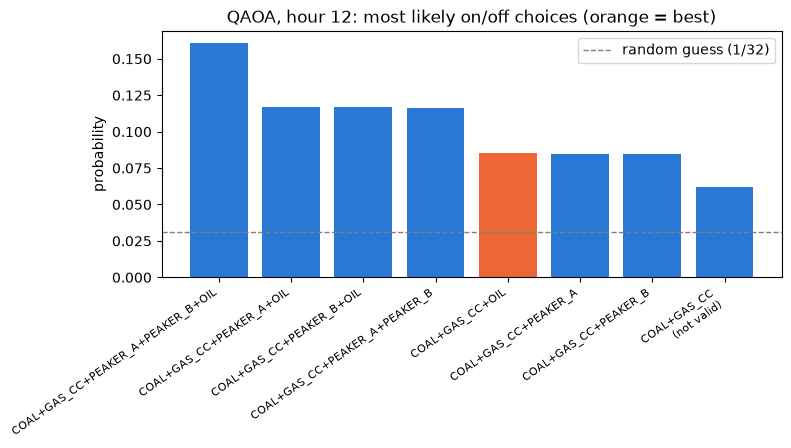

P(best choice) = 0.085   random guess = 0.031


In [ ]:
start = time.perf_counter()
angles, probs = run_qaoa(Q, offset, p=1)
print(f"QAOA for hour {TEST_HOUR}: {time.perf_counter() - start:.2f} s, angles {np.round(angles, 3)}")

pc = choice_probs(probs)
best_k = int(bits[:N] @ (2 ** np.arange(N)))          # brute-force best from above
top = np.argsort(-pc)[:8]
valid = [hour_ok(plants, demand[TEST_HOUR], reserve[TEST_HOUR], [(k >> i) & 1 for i in range(N)]) for k in top]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(range(len(top)), pc[top], color=[COLORS["qaoa"] if k == best_k else COLORS["milp"] for k in top])
ax.axhline(1 / 2 ** N, color="gray", ls="--", lw=1, label="random guess (1/32)")
ax.set_xticks(range(len(top)), [label(int(k)) + ("" if ok else "\n(not valid)") for k, ok in zip(top, valid)],
              rotation=35, ha="right", fontsize=8)
ax.set(ylabel="probability", title=f"QAOA, hour {TEST_HOUR}: most likely on/off choices (orange = best)")
ax.legend()
plt.show()
print(f"P(best choice) = {pc[best_k]:.3f}   random guess = {1 / 2 ** N:.3f}")

## 5. The whole day, hour by hour (Milestone 4)

`schedule_day` goes through the 24 hours in order. For each hour it:

1. Asks `check.locks` which plants min up / min down times force on or off (classical).
2. Builds your QUBO, plus a penalty for breaking those locks.
3. Runs QAOA, starting from the previous hour's angles (warm start).
4. Draws `shots` samples, like a quantum computer would.
5. Keeps the cheapest sampled on/off choice that passes the classical check (`hour_ok`, exact `hour_cost`).
6. Carries that choice forward as "who was on" for the next hour.

If no sample passes, it keeps a choice that breaks a lock (or, failing that, the most common sample), and the checker lists the broken rule.

In [ ]:
def add_locks(Q, offset, must_on, must_off, weight):
    # Penalty weight*(1 - x_i) for a plant that must stay on, weight*x_i for one that must stay off.
    Q = Q.copy()
    for i in must_on:
        Q[i, i] -= weight
        offset += weight
    for i in must_off:
        Q[i, i] += weight
    return Q, offset


def schedule_day(p=1, shots=200, sampler="qaoa", seed=7, penalty=None):
    rng = np.random.default_rng(seed)
    history, log, angles = [], [], None
    was_on = [int(x["on_at_start"]) for x in plants]
    for t in hours:
        must_on, must_off = locks(plants, history)
        Q, offset = build_qubo(plants, demand[t], reserve[t], was_on, penalty=penalty)
        Q, offset = add_locks(Q, offset, must_on, must_off, weight=2 * plant_hour_costs(plants, was_on).max())
        if sampler == "qaoa":
            angles, probs = run_qaoa(Q, offset, p=p, start=angles)
        else:                                   # random guessing, for comparison
            probs = np.full(2 ** N_QUBITS, 1 / 2 ** N_QUBITS)
        samples = rng.choice(2 ** N_QUBITS, size=shots, p=probs / probs.sum())
        seen = [list(INDEX_BITS[k][:N]) for k in np.unique(PLANT_INDEX[samples])]
        ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c, must_on, must_off)]
        if not ok:                              # nothing fully valid: allow breaking a lock
            ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c)]
        if ok:
            pick = min(ok, key=lambda c: hour_cost(plants, demand[t], c, was_on))
        else:                                   # still nothing: take the most common sample
            pick = list(INDEX_BITS[np.bincount(PLANT_INDEX[samples]).argmax()][:N])
        ref = check_hour(plants, demand[t], reserve[t], pick, was_on, must_on, must_off, verbose=False)
        best_k = None if ref["best_choice"] is None else int(np.dot(ref["best_choice"], 2 ** np.arange(N)))
        valid_share = np.mean([hour_ok(plants, demand[t], reserve[t], INDEX_BITS[k][:N], must_on, must_off)
                               for k in samples])
        log.append(dict(hour=t, pick=pick, matches_best=ref["matches_best"], valid_share=valid_share,
                        p_best=0.0 if best_k is None else choice_probs(probs)[best_k],
                        Q=Q, offset=offset, angles=angles))
        history.append(pick)
        was_on = pick
    return np.array(history), log

In [ ]:
start = time.perf_counter()
qaoa_schedule, qaoa_log = schedule_day(p=1, shots=200)
print(f"QAOA for 24 hours: {time.perf_counter() - start:.1f} s\n")
qaoa_result = check_schedule(plants, demand, reserve, qaoa_schedule, milp_cost=milp_cost)

print(f"\n{'hour':>4}  {'choice':<28}{'best for this hour?':>20}{'P(best)':>9}{'valid samples':>15}")
for row in qaoa_log:
    print(f"{row['hour']:>4}  {label(row['pick']):<28}{'yes' if row['matches_best'] else 'no':>20}"
          f"{row['p_best']:>9.3f}{row['valid_share']:>14.0%}")

QAOA for 24 hours: 2.6 s

Total cost: $351,082  (startups $43,360, no-load $26,163, energy $281,559)
MILP optimum: $327,924   gap: +7.06%
Valid: every hour meets demand and reserve; no min up/down rule is broken.

hour  choice                       best for this hour?  P(best)  valid samples
   0  COAL                                         yes    0.049           70%
   1  COAL                                         yes    0.049           70%
   2  COAL                                         yes    0.049           70%
   3  COAL                                         yes    0.049           66%
   4  COAL                                         yes    0.049           66%
   5  COAL+OIL                                     yes    0.042           60%
   6  COAL+PEAKER_A+OIL                            yes    0.034           46%
   7  COAL+PEAKER_A+PEAKER_B+OIL                   yes    0.048           30%
   8  COAL+GAS_CC+PEAKER_A+PEAKER_B                 yes    0.070           15%
   9

## 6. Results vs the baseline

As an honesty check, the same loop also runs with random guesses instead of QAOA. Compare them: if random guessing does as well, what is making your schedule good? Look at every step of the loop, not just the sampler, before you answer.

**Required for milestone 4:** run QAOA and random guessing at 5, 10, 20, 50 and 200 shots, with at least 5 seeds each (`schedule_day(shots=..., sampler=..., seed=...)`). Make a table: how many days come out valid, and the cost gap of the valid ones. Explain it before you tune anything.

Then try:
- More layers (`p=2`), more optimizer steps, or a smaller penalty weight (`schedule_day(penalty=...)`; the default is 2 × the biggest plant cost).
- Why does the hour-by-hour schedule cost more than the MILP?

In [ ]:
#Change this number to 5, 10, 20, 50, or 200
SHOTS = 200

#Change the seed to test different random runs 1-5
SEED = 5

random_schedule, random_log = schedule_day(
    shots=SHOTS,
    sampler="random",
    seed=SEED
)

print(f"Random sampling with {SHOTS} shots, seed={SEED}")

random_result = check_schedule(
    plants,
    demand,
    reserve,
    random_schedule,
    milp_cost=milp_cost
)



Random sampling with 200 shots, seed=5
Total cost: $353,363  (startups $43,360, no-load $26,857, energy $283,146)
MILP optimum: $327,924   gap: +7.76%
Valid: every hour meets demand and reserve; no min up/down rule is broken.


In [ ]:
'''5 10 20 50 200
1 x x  o  o   o
2 x x  x  o   o
3 x x  x  o   o
4 x x  x  o   o
5 x x  x  o   o'''

'5 10 20 50 200\n1 x x  o  o   o\n2 x x  x  o   o\n3 x x  x  o   o\n4 x x  x  o   o\n5 x x  x  o   o'

### Required experiment: QAOA versus random sampling

This runs 50 local ideal-simulator schedules: 2 samplers × 5 shot budgets × 5 sampling seeds (0–4), with p=1 and the default penalties. No cloud jobs are submitted. Each QAOA run includes fresh angle tuning. Runtime includes scheduling and validation; the full-day MILP baseline is computed separately. Seeds vary samples, not optimizer initialization.

Cost gaps include **valid schedules only**; a dash means no valid days. Valid samples is the average across all hours and seeds, each on its own evolving schedule history, so it is not a comparison of identical hourly inputs. Five seeds are an initial experiment, not strong statistical evidence. Raw runs and summary are saved as CSVs in results/.


In [ ]:
from benchmark import run_benchmark, display_summary

benchmark_runs, benchmark_summary = run_benchmark(
    schedule_day, check_schedule, plants, demand, reserve, milp_cost,
    shots_grid=(5, 10, 20, 50, 200), seeds=range(5),
)
display_summary(benchmark_summary)


Finished qaoa  ,   5 shots (5 seeds)
Finished random,   5 shots (5 seeds)
Finished qaoa  ,  10 shots (5 seeds)
Finished random,  10 shots (5 seeds)
Finished qaoa  ,  20 shots (5 seeds)
Finished random,  20 shots (5 seeds)
Finished qaoa  ,  50 shots (5 seeds)
Finished random,  50 shots (5 seeds)
Finished qaoa  , 200 shots (5 seeds)
Finished random, 200 shots (5 seeds)


| Sampler | Shots | Valid days | Mean valid gap (%) | Valid gap range (%) | Median runtime (s) | Valid samples (%) |
| --- | --- | --- | --- | --- | --- | --- |
| qaoa | 5 | 0/5 | — | — | 2.60 | 32.50 |
| random | 5 | 0/5 | — | — | 0.01 | 10.50 |
| qaoa | 10 | 2/5 | 11.82 | 8.42 to 15.22 | 2.61 | 45.75 |
| random | 10 | 0/5 | — | — | 0.02 | 12.58 |
| qaoa | 20 | 4/5 | 8.20 | 6.86 to 10.33 | 2.57 | 51.17 |
| random | 20 | 1/5 | 10.75 | 10.75 to 10.75 | 0.02 | 21.88 |
| qaoa | 50 | 5/5 | 7.74 | 7.06 to 8.98 | 2.58 | 51.02 |
| random | 50 | 5/5 | 9.44 | 7.64 to 11.20 | 0.04 | 28.28 |
| qaoa | 200 | 5/5 | 7.06 | 7.06 to 7.06 | 2.61 | 50.45 |
| random | 200 | 5/5 | 7.06 | 7.06 to 7.06 | 0.11 | 28.95 |

'| Sampler | Shots | Valid days | Mean valid gap (%) | Valid gap range (%) | Median runtime (s) | Valid samples (%) |\n| --- | --- | --- | --- | --- | --- | --- |\n| qaoa | 5 | 0/5 | — | — | 2.60 | 32.50 |\n| random | 5 | 0/5 | — | — | 0.01 | 10.50 |\n| qaoa | 10 | 2/5 | 11.82 | 8.42 to 15.22 | 2.61 | 45.75 |\n| random | 10 | 0/5 | — | — | 0.02 | 12.58 |\n| qaoa | 20 | 4/5 | 8.20 | 6.86 to 10.33 | 2.57 | 51.17 |\n| random | 20 | 1/5 | 10.75 | 10.75 to 10.75 | 0.02 | 21.88 |\n| qaoa | 50 | 5/5 | 7.74 | 7.06 to 8.98 | 2.58 | 51.02 |\n| random | 50 | 5/5 | 9.44 | 7.64 to 11.20 | 0.04 | 28.28 |\n| qaoa | 200 | 5/5 | 7.06 | 7.06 to 7.06 | 2.61 | 50.45 |\n| random | 200 | 5/5 | 7.06 | 7.06 to 7.06 | 0.11 | 28.95 |'

<a id="earlier-experiments"></a>
## E 1–E 10 — earlier comparisons and window-selection experiments

These are supporting experiments; jump to [RQ 1–RQ 5](../solution/reduced_qubit_hybrid_hourly.ipynb#reduced-hybrid-main) for the main solution.


### E 1 — Five-plant results

Original full-day comparison and plots.


method                          daily cost $       gap  rules broken
MILP (optimal)                       327,924    +0.00%             0
cheapest-first rule                  330,594    +0.81%             1
QAOA, hour by hour                   351,082    +7.06%             0
random guesses, hour by hour         351,082    +7.06%             0


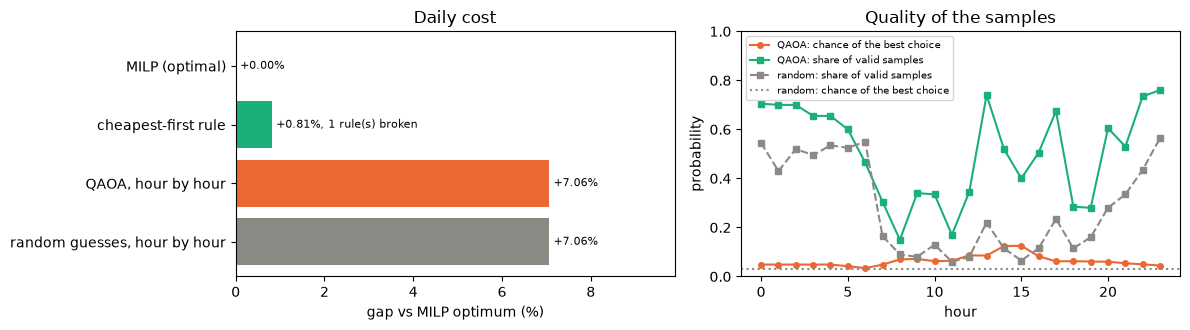

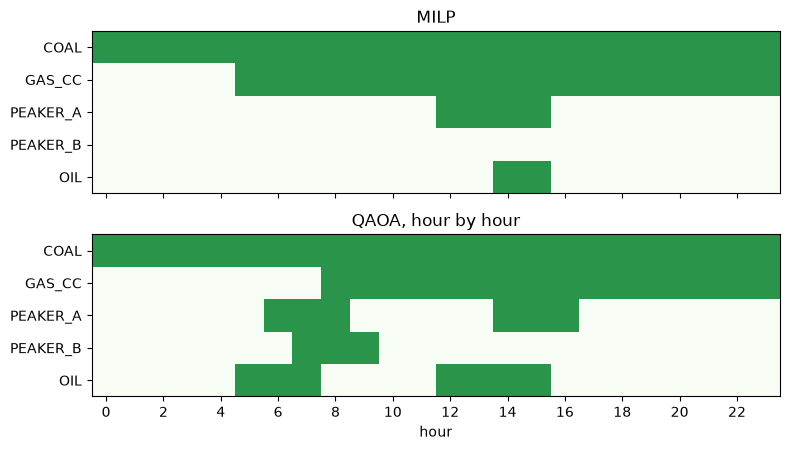

In [ ]:
# ==================== This is the 5 plant run ====================
random_schedule, random_log = schedule_day(sampler="random")
random_result = check_schedule(plants, demand, reserve, random_schedule, milp_cost=milp_cost, verbose=False)

results = {"MILP (optimal)": (milp_result, COLORS["milp"]),
           "cheapest-first rule": (rule_result, COLORS["rule"]),
           "QAOA, hour by hour": (qaoa_result, COLORS["qaoa"]),
           "random guesses, hour by hour": (random_result, COLORS["random"])}
print(f"{'method':<30}{'daily cost $':>14}{'gap':>10}{'rules broken':>14}")
for name, (r, _) in results.items():
    print(f"{name:<30}{r['total_cost']:>14,.0f}{r['gap_pct']:>+9.2f}%{len(r['violations']):>14}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].barh(list(results), [r["gap_pct"] for r, _ in results.values()],
             color=[color for _, color in results.values()])
for y, (r, _) in enumerate(results.values()):
    broken = f", {len(r['violations'])} rule(s) broken" if r["violations"] else ""
    axes[0].text(max(r["gap_pct"], 0) + 0.1, y, f"{r['gap_pct']:+.2f}%{broken}", va="center", fontsize=8)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 1.4 * max(max(r["gap_pct"] for r, _ in results.values()), 1))
axes[0].set(xlabel="gap vs MILP optimum (%)", title="Daily cost")
axes[1].plot(hours, [row["p_best"] for row in qaoa_log], "o-", color=COLORS["qaoa"], ms=4,
             label="QAOA: chance of the best choice")
axes[1].plot(hours, [row["valid_share"] for row in qaoa_log], "s-", color=COLORS["rule"], ms=4,
             label="QAOA: share of valid samples")
axes[1].plot(hours, [row["valid_share"] for row in random_log], "s--", color=COLORS["random"], ms=4,
             label="random: share of valid samples")
axes[1].axhline(1 / 2 ** N, color=COLORS["random"], ls=":", label="random: chance of the best choice")
axes[1].set(xlabel="hour", ylabel="probability", ylim=(0, 1), title="Quality of the samples")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True)
plot_schedule(milp_schedule, "MILP", ax=axes[0]).set_xlabel("")
plot_schedule(qaoa_schedule, "QAOA, hour by hour", ax=axes[1])
plt.tight_layout()
plt.show()



### E 2 — Ten-plant comparison

Runs the original algorithms with the supplied ten-plant fleet.


In [ ]:
# ==================== This is the 10 plant run ====================
# Uses the supplied stretch-fleet data and the SAME functions above.
# Run the earlier helper-definition cells first. No cells below the milestones
# checklist are needed. Results stay in memory; no CSVs or folders are created.
def run_10_plant_test(shots_grid=(200,), seeds=(7,)):
    from check import DATA

    # The original helpers read these globals. Restore every one in finally,
    # including on interruption, so the original five-plant run remains usable.
    setting_names = ("plants", "demand", "reserve", "N", "names", "hours",
                     "N_SLACK", "N_QUBITS", "INDEX_BITS", "PLANT_INDEX")
    original_settings = {key: globals()[key] for key in setting_names}
    shots_grid, seeds = tuple(shots_grid), tuple(seeds)
    if not shots_grid or not seeds:
        raise ValueError("Choose at least one shot budget and seed.")
    try:
        fleet = load_plants(DATA / "plants10.csv")
        load, margin = load_demand(DATA / "demand10.csv")
        n_plants = len(fleet)
        assert n_plants == 10
        # Keep the original 3 slack bits and penalty/optimizer settings.
        # This still limits unpenalized spare capacity to 7 * 50 = 350 MW;
        # expanding the fleet does not fix that approximation in our QUBO.
        n_slack = 3
        n_qubits = n_plants + n_slack
        index_bits = (np.arange(2 ** n_qubits)[:, None] >> np.arange(n_qubits)) & 1
        globals().update(plants=fleet, demand=load, reserve=margin, N=n_plants,
                         names=[p["plant_id"] for p in fleet], hours=np.arange(len(load)),
                         N_SLACK=n_slack, N_QUBITS=n_qubits, INDEX_BITS=index_bits,
                         PLANT_INDEX=index_bits[:, :n_plants] @ (2 ** np.arange(n_plants)))
        print(f"10 plant run: {len(load)} hours, {n_qubits} qubits, "
              f"{2 ** n_plants} plant choices; local ideal simulation only.", flush=True)
        baseline_cost, baseline_schedule, baseline_dispatch, baseline_seconds = solve_milp(
            fleet, load, margin)
        baseline_result = check_schedule(fleet, load, margin, baseline_schedule,
                                         milp_cost=baseline_cost, verbose=False)
        assert baseline_result["valid"]
        print(f"10 plant MILP: ${baseline_cost:,.2f}, {baseline_seconds:.2f} s", flush=True)
        rule = cheapest_first(fleet, load, margin)
        rule_check = check_schedule(fleet, load, margin, rule,
                                   milp_cost=baseline_cost, verbose=False)

        # Milestone 3: compare QUBO minima with exact dispatch costs, hour by hour.
        hourly_checks = []
        for t in range(len(load)):
            previous = baseline_schedule[t - 1] if t else [int(p["on_at_start"]) for p in fleet]
            matrix, constant = build_qubo(fleet, load[t], margin[t], previous)
            best_bits, _ = brute_force_qubo(matrix, constant)
            hourly_checks.append(check_hour(fleet, load[t], margin[t], best_bits[:n_plants],
                                             was_on=previous, verbose=False))
        matches = sum(r["matches_best"] for r in hourly_checks)
        print(f"10 plant QUBO matches exact hourly best: {matches}/{len(load)}", flush=True)

        # Default: one full day for each sampler, with the original p=1 and 200 shots.
        # For the complete milestone sweep, call this function with
        # shots_grid=(5, 10, 20, 50, 200), seeds=range(5). Fresh tuning can be slow.
        runs = []
        for shots in shots_grid:
            for seed in seeds:
                for sampler in ("qaoa", "random"):
                    print(f"10 plant run: {sampler}, shots={shots}, seed={seed} ...", flush=True)
                    started = time.perf_counter()
                    schedule, log = schedule_day(p=1, shots=shots, sampler=sampler, seed=seed)
                    result = check_schedule(fleet, load, margin, schedule,
                                            milp_cost=baseline_cost, verbose=False)
                    elapsed = time.perf_counter() - started
                    assert schedule.shape == (len(load), n_plants)
                    runs.append(dict(sampler=sampler, shots=shots, seed=seed,
                                     schedule=schedule, log=log, result=result, runtime_s=elapsed))
                    gap = f"{result['gap_pct']:+.2f}%" if result["valid"] else "n/a (invalid)"
                    print(f"  cost=${result['total_cost']:,.2f}, valid={result['valid']}, "
                          f"gap={gap}, violations={len(result['violations'])}, "
                          f"time={elapsed:.2f} s", flush=True)
        rule_gap = f"{rule_check['gap_pct']:+.2f}%" if rule_check["valid"] else "n/a (invalid)"
        print(f"10 plant cheapest-first: ${rule_check['total_cost']:,.2f}, "
              f"gap={rule_gap}, violations={len(rule_check['violations'])}")
        return dict(plants=fleet, demand=load, reserve=margin, n_qubits=n_qubits,
                    milp_cost=baseline_cost, milp_schedule=baseline_schedule,
                    milp_dispatch=baseline_dispatch, milp_result=baseline_result,
                    milp_seconds=baseline_seconds, rule_schedule=rule, rule_result=rule_check,
                    hourly_checks=hourly_checks, runs=runs)
    finally:
        globals().update(original_settings)


ten_plant_results = run_10_plant_test()
# ================== End of the 10 plant run ==================




10 plant run: 24 hours, 13 qubits, 1024 plant choices; local ideal simulation only.
10 plant MILP: $602,139.47, 0.06 s
10 plant QUBO matches exact hourly best: 15/24
10 plant run: qaoa, shots=200, seed=7 ...
  cost=$691,621.65, valid=True, gap=+14.86%, violations=0, time=10.01 s
10 plant run: random, shots=200, seed=7 ...
  cost=$740,091.38, valid=False, gap=n/a (invalid), violations=3, time=0.43 s
10 plant cheapest-first: $631,460.95, gap=n/a (invalid), violations=3


### E 3 — Ten-plant plots

Displays the ten-plant comparison already computed in E 2.



10 plants
method                          daily cost $       gap  rules broken
MILP (optimal)                       602,139    +0.00%             0
cheapest-first rule                  631,461    +4.87%             3
QAOA, hour by hour                   691,622   +14.86%             0
random guesses, hour by hour         740,091   +22.91%             3


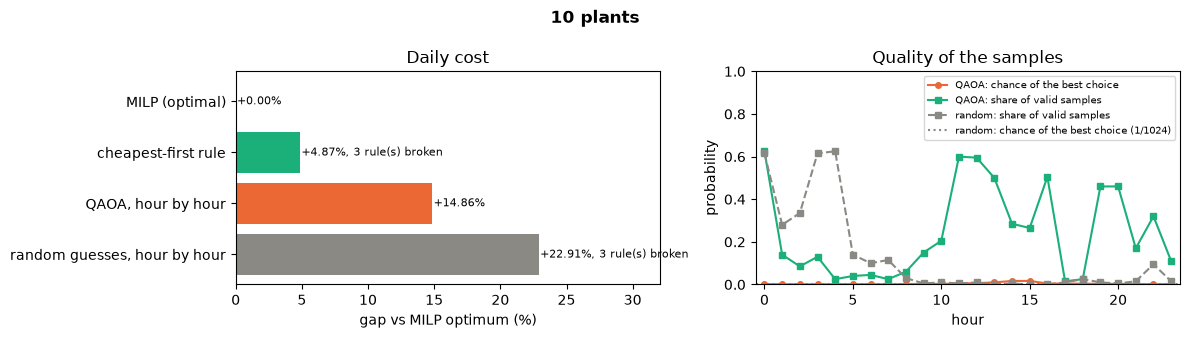

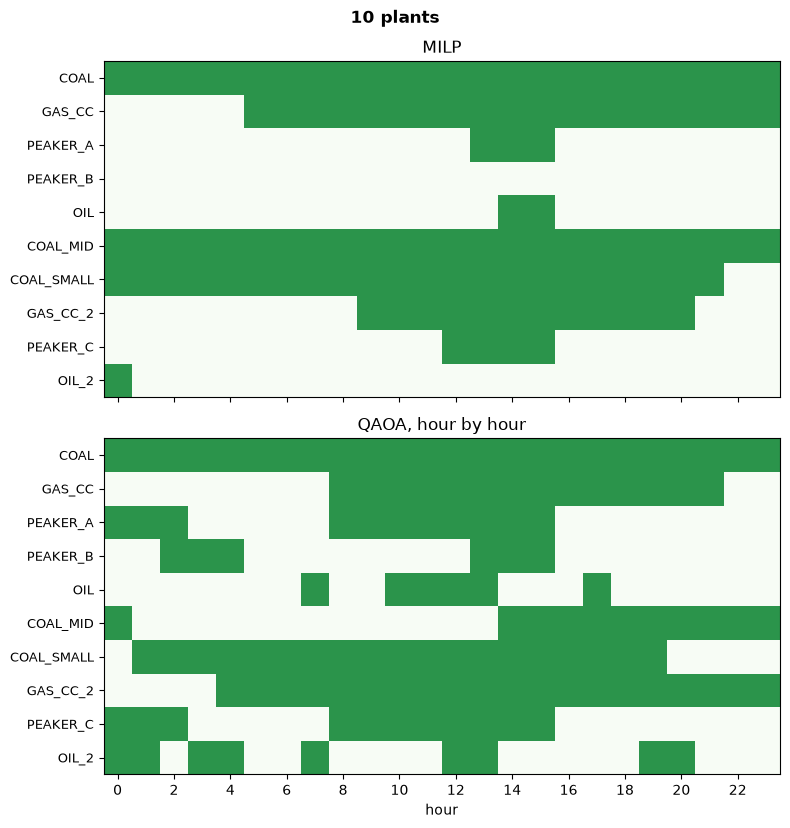

In [ ]:
# ==================== Graphs for the 10 plant run ====================
# The same three pictures the 5 plant run shows above: the cost table, the gap bars with the
# per-hour sample quality, and the MILP vs test schedules. Everything comes from
# ten_plant_results, so nothing is re-run here.
def hour_stretches(hour_list):
    # Group consecutive hours: [0,1,2,18,19] -> [(0, 2), (18, 19)].
    stretches, run = [], []
    for h in sorted(hour_list):
        if run and h != run[-1] + 1:
            stretches.append((run[0], run[-1]))
            run = []
        run.append(h)
    if run:
        stretches.append((run[0], run[-1]))
    return stretches


def plot_fleet_schedule(schedule, title, plant_names, ax, milp_hours=()):
    # plot_schedule for any fleet size. Dashed lines mark where the method switches (hybrid runs).
    schedule = np.asarray(schedule)
    ax.imshow(schedule.T, aspect="auto", cmap="Greens", vmin=0, vmax=1.4)
    ax.set_yticks(range(len(plant_names)), plant_names, fontsize=9 if len(plant_names) <= 15 else 5)
    ax.set_xticks(range(0, len(schedule), 2))
    ax.set_xlabel("hour")
    ax.set_title(title)
    for a, b in hour_stretches(milp_hours):
        for edge in (a - 0.5, b + 0.5):
            if 0 < edge < len(schedule) - 1:
                ax.axvline(edge, color="black", ls="--", lw=1)
    return ax


def report_fleet_day(title, results, test_log, random_log, milp_schedule, test_schedule,
                     test_name, plant_names, sampler_name="QAOA", milp_hours=(),
                     p_best_label="chance of the best choice"):
    """Cost table + the two figures of the 5 plant run, for any fleet and any hour-by-hour log.

    results: {method name: (check_schedule result, color)}, MILP first.
    test_log / random_log: the per-hour logs (p_best, valid_share) of the sampled run and of
    the random-guess run. Hours decided by MILP (hybrid runs) hold NaN and are shaded gray.
    """
    n_plants, n_hours = len(plant_names), len(milp_schedule)
    hrs = np.arange(n_hours)
    print(f"\n{title}")
    print(f"{'method':<30}{'daily cost $':>14}{'gap':>10}{'rules broken':>14}")
    for name, (r, _) in results.items():
        print(f"{name:<30}{r['total_cost']:>14,.0f}{r['gap_pct']:>+9.2f}%{len(r['violations']):>14}")

    def series(log, key):
        return np.array([float(row.get(key, np.nan)) for row in log])

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
    axes[0].barh(list(results), [r["gap_pct"] for r, _ in results.values()],
                 color=[color for _, color in results.values()])
    for y, (r, _) in enumerate(results.values()):
        broken = f", {len(r['violations'])} rule(s) broken" if r["violations"] else ""
        axes[0].text(max(r["gap_pct"], 0) + 0.1, y, f"{r['gap_pct']:+.2f}%{broken}", va="center", fontsize=8)
    axes[0].invert_yaxis()
    axes[0].set_xlim(0, 1.4 * max(max(r["gap_pct"] for r, _ in results.values()), 1))
    axes[0].set(xlabel="gap vs MILP optimum (%)", title="Daily cost")
    axes[1].plot(hrs, series(test_log, "p_best"), "o-", color=COLORS["qaoa"], ms=4,
                 label=f"{sampler_name}: {p_best_label}")
    axes[1].plot(hrs, series(test_log, "valid_share"), "s-", color=COLORS["rule"], ms=4,
                 label=f"{sampler_name}: share of valid samples")
    axes[1].plot(hrs, series(random_log, "valid_share"), "s--", color=COLORS["random"], ms=4,
                 label="random: share of valid samples")
    axes[1].axhline(1 / 2 ** n_plants, color=COLORS["random"], ls=":",
                    label=f"random: chance of the best choice (1/{2 ** n_plants})")
    for k, (a, b) in enumerate(hour_stretches(milp_hours)):
        axes[1].axvspan(a - 0.5, b + 0.5, color="lightgray", alpha=0.6, lw=0,
                        label="MILP hours (no samples)" if k == 0 else None)
    axes[1].set(xlabel="hour", ylabel="probability", ylim=(0, 1), xlim=(-0.5, n_hours - 0.5),
                title="Quality of the samples")
    axes[1].legend(fontsize=7)
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(2, 1, figsize=(8, min(12, 1.2 + 0.36 * 2 * n_plants)), sharex=True)
    plot_fleet_schedule(milp_schedule, "MILP", plant_names, axes[0], milp_hours).set_xlabel("")
    plot_fleet_schedule(test_schedule, test_name, plant_names, axes[1], milp_hours)
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()


ten_names = [p["plant_id"] for p in ten_plant_results["plants"]]
ten_qaoa = next(r for r in ten_plant_results["runs"] if r["sampler"] == "qaoa")
ten_random = next(r for r in ten_plant_results["runs"] if r["sampler"] == "random")
ten_results = {"MILP (optimal)": (ten_plant_results["milp_result"], COLORS["milp"]),
               "cheapest-first rule": (ten_plant_results["rule_result"], COLORS["rule"]),
               "QAOA, hour by hour": (ten_qaoa["result"], COLORS["qaoa"]),
               "random guesses, hour by hour": (ten_random["result"], COLORS["random"])}
report_fleet_day("10 plants", ten_results, ten_qaoa["log"], ten_random["log"],
                 ten_plant_results["milp_schedule"], ten_qaoa["schedule"], "QAOA, hour by hour", ten_names)
# ================== End of the graphs for the 10 plant run ==================




### E 4 — Hourly hybrid implementation

Defines the shared MILP/QAOA scheduler and carries minimum on/off obligations across method boundaries. Later studies reuse these definitions.


In [ ]:
# ==================== Hybrid runs: QAOA for some hours, MILP for the rest (10 plants) ====================
# The day is split into "day" (DAY_HOURS) and "night" (the other 12 hours). One method decides the
# day hours, the other the night hours, in one hour-by-hour pass:
#   * QAOA hours work exactly like schedule_day (locks, QUBO, QAOA, shots, cheapest valid sample).
#   * At the first hour of each MILP stretch, one MILP is solved from that hour to the end of the day
#     (milp_horizon="day"; "block" stops at the end of the stretch), starting from the hour-by-hour
#     history so far: who was on, and how many hours of min up / min down time each plant still owes.
#     Only the stretch's hours are committed; the next QAOA hours carry on from them.
# The honesty check is the same as above: the same pass with random guesses in the QAOA hours.
from contextlib import contextmanager
from scipy.optimize import Bounds, LinearConstraint, milp as scipy_milp
from scipy.sparse import lil_matrix

DAY_HOURS = range(6, 18)                                         # 06:00 to 18:00: the 12 daytime hours
NIGHT_HOURS = [t for t in range(24) if t not in DAY_HOURS]       # 18:00 to 06:00


@contextmanager
def fleet_globals(fleet, load, margin, n_slack=3, tables=True):
    # Point the notebook's helpers (build_qubo, run_qaoa, choice_probs, ...) at another fleet,
    # then restore the 5 plant settings, also on an error or interruption (as run_10_plant_test does).
    # tables=False skips the 2^qubits bitstring tables (INDEX_BITS, PLANT_INDEX) for fleets too big for them.
    setting_names = ("plants", "demand", "reserve", "N", "names", "hours",
                     "N_SLACK", "N_QUBITS", "INDEX_BITS", "PLANT_INDEX")
    saved = {key: globals()[key] for key in setting_names}
    n_plants, n_qubits = len(fleet), len(fleet) + n_slack
    index_bits = (np.arange(2 ** n_qubits)[:, None] >> np.arange(n_qubits)) & 1 if tables else None
    globals().update(plants=fleet, demand=load, reserve=margin, N=n_plants,
                     names=[p["plant_id"] for p in fleet], hours=np.arange(len(load)),
                     N_SLACK=n_slack, N_QUBITS=n_qubits, INDEX_BITS=index_bits,
                     PLANT_INDEX=None if index_bits is None else index_bits[:, :n_plants] @ (2 ** np.arange(n_plants)))
    try:
        yield
    finally:
        globals().update(saved)


def remaining_locks(plants, history):
    # Like check.locks, but with the number of hours each plant must still stay on / off.
    hold_on, hold_off = np.zeros(len(plants), dtype=int), np.zeros(len(plants), dtype=int)
    for i, p in enumerate(plants):
        states = [int(p["on_at_start"])] + [int(h[i]) for h in history]
        now, held = states[-1], 0
        for s in reversed(states):
            if s != now:
                break
            held += 1
        if held == len(states):          # never switched today: free, as in check.locks
            continue
        if now == 1:
            hold_on[i] = max(0, int(p["min_up_h"]) - held)
        else:
            hold_off[i] = max(0, int(p["min_down_h"]) - held)
    return hold_on, hold_off


def solve_milp_window(plants, demand, reserve, was_on, hold_on, hold_off):
    """check.solve_milp for a stretch of hours that starts in the middle of the day.

    was_on: who was on the hour before the stretch (decides who pays a startup).
    hold_on[i] / hold_off[i]: hours plant i must still stay on / off at the start of the stretch
    (see remaining_locks). Returns (cost, schedule [hours x plants], seconds).
    """
    n, T = len(plants), len(demand)
    U = lambda i, t: i * T + t
    V = lambda i, t: n * T + i * T + t
    P = lambda i, t: 2 * n * T + i * T + t
    cost = np.zeros(3 * n * T)
    lower = np.zeros(3 * n * T)
    upper = np.r_[np.ones(2 * n * T), [p["pmax_mw"] for p in plants for _ in range(T)]]
    rows, lo, hi = [], [], []

    def add(terms, low, high):            # low <= sum(coef * x[j]) <= high
        rows.append(terms)
        lo.append(low)
        hi.append(high)

    for t in range(T):
        add([(P(i, t), 1) for i in range(n)], demand[t], demand[t])
        add([(U(i, t), p["pmax_mw"]) for i, p in enumerate(plants)], demand[t] + reserve[t], np.inf)
    for i, p in enumerate(plants):
        up, down, u0 = int(p["min_up_h"]), int(p["min_down_h"]), int(was_on[i])
        for t in range(T):
            cost[U(i, t)] = p["no_load_cost_per_h"]
            cost[V(i, t)] = p["startup_cost"]
            cost[P(i, t)] = p["marginal_cost_per_mwh"]
            add([(P(i, t), 1), (U(i, t), -p["pmin_mw"])], 0, np.inf)
            add([(P(i, t), 1), (U(i, t), -p["pmax_mw"])], -np.inf, 0)
            before = [(U(i, t - 1), 1)] if t > 0 else []          # v_t >= u_t - u_(t-1)
            add([(V(i, t), 1), (U(i, t), -1)] + before, -u0 if t == 0 else 0, np.inf)
            add([(V(i, s), 1) for s in range(max(0, t - up + 1), t + 1)] + [(U(i, t), -1)], -np.inf, 0)
            window = [(V(i, s), 1) for s in range(max(0, t - down + 1), t + 1)]
            if t - down >= 0:
                add(window + [(U(i, t - down), 1)], -np.inf, 1)
            else:
                add(window, -np.inf, 1 - u0)
        # Min up / min down time still owed from before the stretch: pin the first hours.
        for t in range(min(T, int(hold_on[i]))):
            lower[U(i, t)] = 1
        for t in range(min(T, int(hold_off[i]))):
            upper[U(i, t)] = 0
    A = lil_matrix((len(rows), 3 * n * T))
    for k, terms in enumerate(rows):
        for j, a in terms:
            A[k, j] += a
    integrality = np.r_[np.ones(2 * n * T), np.zeros(n * T)]
    start = time.perf_counter()
    res = scipy_milp(cost, constraints=LinearConstraint(A.tocsr(), lo, hi),
                     integrality=integrality, bounds=Bounds(lower, upper))
    seconds = time.perf_counter() - start
    if res.x is None:
        raise RuntimeError(f"The MILP found no schedule for this stretch: {res.message}")
    schedule = np.array([[round(res.x[U(i, t)]) for i in range(n)] for t in range(T)])
    return res.fun, schedule, seconds


def schedule_day_hybrid(qaoa_hours, p=1, shots=200, sampler="qaoa", seed=7, penalty=None,
                        milp_horizon="day"):
    """schedule_day, except that the hours not in qaoa_hours are decided by a MILP.

    Returns (schedule, log). Each log row has method="qaoa" or "milp"; MILP rows have NaN
    for p_best and valid_share (there are no samples). The log also records the MILP seconds.
    """
    qaoa_hours = {int(t) for t in qaoa_hours}
    rng = np.random.default_rng(seed)
    history, log, angles = [], [], None
    was_on = [int(x["on_at_start"]) for x in plants]
    T, t = len(hours), 0
    while t < T:
        if t in qaoa_hours:                       # ---- the same steps as schedule_day ----
            must_on, must_off = locks(plants, history)
            Q, offset = build_qubo(plants, demand[t], reserve[t], was_on, penalty=penalty)
            Q, offset = add_locks(Q, offset, must_on, must_off,
                                  weight=2 * plant_hour_costs(plants, was_on).max())
            # The whole fleet is in the QUBO every QAOA hour: one qubit per plant plus the slack qubits.
            # Locked plants stay in it (with a penalty); nothing is dropped to make the problem smaller.
            assert N == len(plants) and Q.shape == (N + N_SLACK, N + N_SLACK), "QAOA must decide all plants"
            if sampler == "qaoa":
                angles, probs = run_qaoa(Q, offset, p=p, start=angles)
            else:                                 # random guessing, for comparison
                probs = np.full(2 ** N_QUBITS, 1 / 2 ** N_QUBITS)
            samples = rng.choice(2 ** N_QUBITS, size=shots, p=probs / probs.sum())
            seen = [list(INDEX_BITS[k][:N]) for k in np.unique(PLANT_INDEX[samples])]
            ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c, must_on, must_off)]
            if not ok:                            # nothing fully valid: allow breaking a lock
                ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c)]
            if ok:
                pick = min(ok, key=lambda c: hour_cost(plants, demand[t], c, was_on))
            else:                                 # still nothing: take the most common sample
                pick = list(INDEX_BITS[np.bincount(PLANT_INDEX[samples]).argmax()][:N])
            ref = check_hour(plants, demand[t], reserve[t], pick, was_on, must_on, must_off, verbose=False)
            best_k = None if ref["best_choice"] is None else int(np.dot(ref["best_choice"], 2 ** np.arange(N)))
            valid_share = np.mean([hour_ok(plants, demand[t], reserve[t], INDEX_BITS[k][:N], must_on, must_off)
                                   for k in samples])
            log.append(dict(hour=t, method=sampler, pick=pick, matches_best=ref["matches_best"],
                            plants_decided=N, qubits=N + N_SLACK, valid_share=valid_share,
                            p_best=0.0 if best_k is None else choice_probs(probs)[best_k],
                            Q=Q, offset=offset, angles=angles, milp_seconds=0.0))
            history.append(pick)
            was_on = pick
            t += 1
        else:                                     # ---- a MILP stretch ----
            stop = t
            while stop < T and stop not in qaoa_hours:
                stop += 1
            end = T if milp_horizon == "day" else stop
            hold_on, hold_off = remaining_locks(plants, history)
            try:
                _, window, secs = solve_milp_window(plants, demand[t:end], reserve[t:end], was_on, hold_on, hold_off)
            except RuntimeError:                  # no schedule honours the locks: allow breaking them
                _, window, secs = solve_milp_window(plants, demand[t:end], reserve[t:end], was_on,
                                                    np.zeros(N, int), np.zeros(N, int))
                print(f"  hour {t}: the MILP had to break a min up/down lock", flush=True)
            for k in range(t, stop):
                must_on, must_off = locks(plants, history)
                pick = [int(x) for x in window[k - t]]
                ref = check_hour(plants, demand[k], reserve[k], pick, was_on, must_on, must_off, verbose=False)
                log.append(dict(hour=k, method="milp", pick=pick, matches_best=ref["matches_best"],
                                valid_share=np.nan, p_best=np.nan, Q=None, offset=None, angles=None,
                                milp_seconds=secs if k == t else 0.0))
                history.append(pick)
                was_on = pick
            t = stop
    return np.array(history), log


def run_hybrid_10_plant_test(qaoa_hours, label_qaoa, label_random, shots=200, seed=7, milp_horizon="day"):
    # One hybrid pass with QAOA and one with random guesses in the QAOA hours, on the 10 plant fleet.
    # Reuses the 10 plant MILP optimum and cheapest-first rule from ten_plant_results.
    base = ten_plant_results
    fleet, load, margin = base["plants"], base["demand"], base["reserve"]
    qaoa_hours = sorted(int(t) for t in qaoa_hours)
    milp_hours = [t for t in range(len(load)) if t not in qaoa_hours]
    assert len(fleet) == 10, "the hybrid runs are for the 10 plant fleet"
    print(f"Hybrid 10 plant run: QAOA hours {hour_stretches(qaoa_hours)}, MILP hours {hour_stretches(milp_hours)}, "
          f"MILP horizon = {milp_horizon}; local ideal simulation only.", flush=True)
    runs = {}
    with fleet_globals(fleet, load, margin):
        print(f"  every QAOA hour decides all {N} plants ({N_QUBITS} qubits: {N} plant + {N_SLACK} slack)", flush=True)
        for sampler, name in (("qaoa", label_qaoa), ("random", label_random)):
            started = time.perf_counter()
            schedule, log = schedule_day_hybrid(qaoa_hours, p=1, shots=shots, sampler=sampler,
                                                seed=seed, milp_horizon=milp_horizon)
            elapsed = time.perf_counter() - started
            result = check_schedule(fleet, load, margin, schedule, milp_cost=base["milp_cost"], verbose=False)
            assert schedule.shape == (len(load), len(fleet))
            milp_secs = sum(row["milp_seconds"] for row in log)
            assert all(row["plants_decided"] == len(fleet) for row in log if row["method"] != "milp")
            runs[sampler] = dict(name=name, schedule=schedule, log=log, result=result, runtime_s=elapsed)
            gap = f"{result['gap_pct']:+.2f}%" if result["valid"] else "n/a (invalid)"
            print(f"  {name}: cost=${result['total_cost']:,.2f}, valid={result['valid']}, gap={gap}, "
                  f"violations={len(result['violations'])}, time={elapsed:.2f} s "
                  f"(MILP {milp_secs:.2f} s, {sampler} hours {elapsed - milp_secs:.2f} s)", flush=True)
    results = {"MILP (optimal)": (base["milp_result"], COLORS["milp"]),
               "cheapest-first rule": (base["rule_result"], COLORS["rule"]),
               label_qaoa: (runs["qaoa"]["result"], COLORS["qaoa"]),
               label_random: (runs["random"]["result"], COLORS["random"])}
    return dict(qaoa_hours=qaoa_hours, milp_hours=milp_hours, milp_horizon=milp_horizon,
                runs=runs, results=results)




### E 5 — Daytime QAOA, nighttime MILP

Earlier twelve-hour daytime candidate; requires E 2–E 4.


Hybrid 10 plant run: QAOA hours [(6, 17)], MILP hours [(0, 5), (18, 23)], MILP horizon = day; local ideal simulation only.
  every QAOA hour decides all 10 plants (13 qubits: 10 plant + 3 slack)
  QAOA day + MILP night: cost=$619,706.68, valid=True, gap=+2.92%, violations=0, time=6.21 s (MILP 0.08 s, qaoa hours 6.13 s)
  random day + MILP night: cost=$678,019.73, valid=False, gap=n/a (invalid), violations=2, time=0.39 s (MILP 0.10 s, random hours 0.29 s)

10 plants, QAOA by day + MILP by night
method                          daily cost $       gap  rules broken
MILP (optimal)                       602,139    +0.00%             0
cheapest-first rule                  631,461    +4.87%             3
QAOA day + MILP night                619,707    +2.92%             0
random day + MILP night              678,020   +12.60%             2


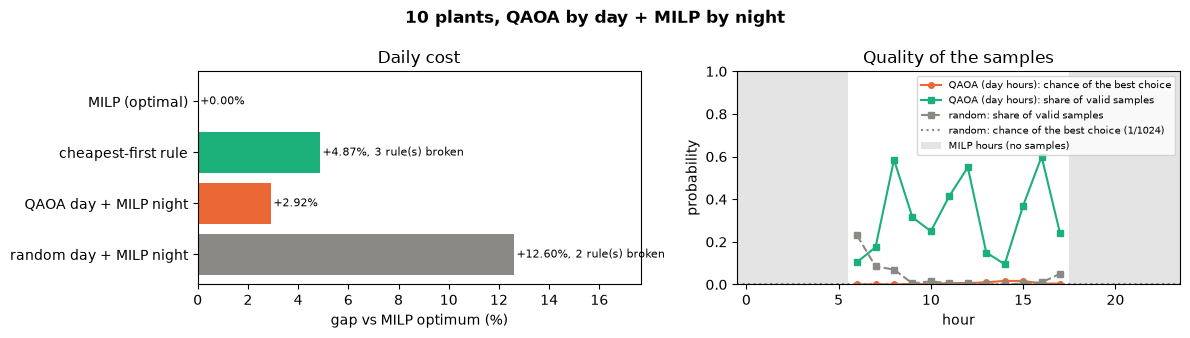

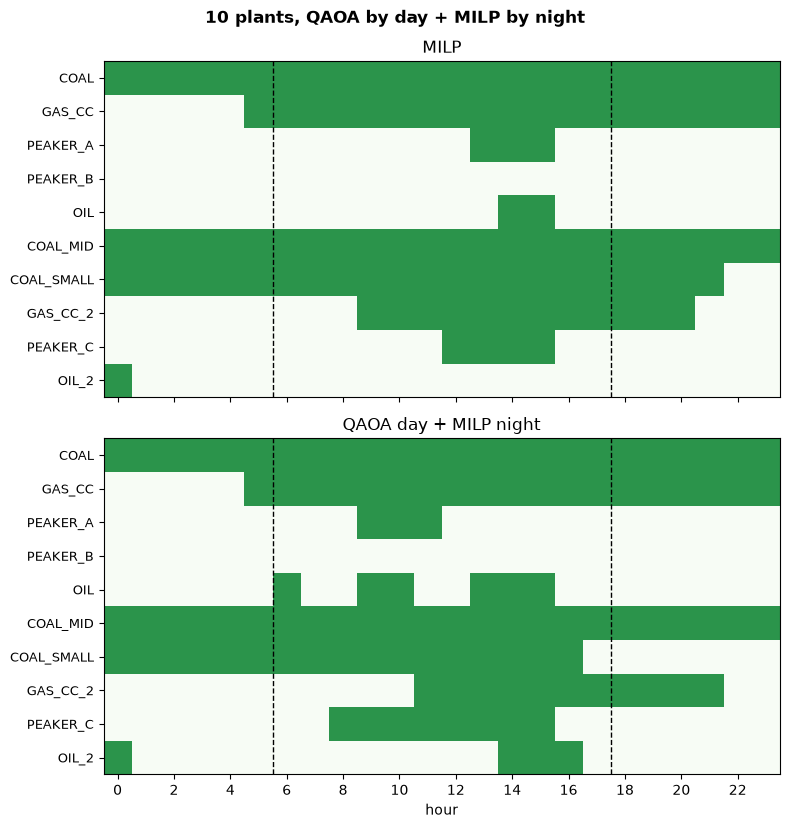

In [ ]:
# ==================== Hybrid A: QAOA by day, MILP by night (10 plants) ====================
hybrid_day_qaoa = run_hybrid_10_plant_test(DAY_HOURS, "QAOA day + MILP night", "random day + MILP night")
report_fleet_day("10 plants, QAOA by day + MILP by night", hybrid_day_qaoa["results"],
                 hybrid_day_qaoa["runs"]["qaoa"]["log"], hybrid_day_qaoa["runs"]["random"]["log"],
                 ten_plant_results["milp_schedule"], hybrid_day_qaoa["runs"]["qaoa"]["schedule"],
                 "QAOA day + MILP night", ten_names, sampler_name="QAOA (day hours)",
                 milp_hours=hybrid_day_qaoa["milp_hours"])
# ================== End of hybrid A ==================




### E 6 — Nighttime QAOA, daytime MILP

Earlier twelve-hour nighttime candidate; requires E 2–E 4.


Hybrid 10 plant run: QAOA hours [(0, 5), (18, 23)], MILP hours [(6, 17)], MILP horizon = day; local ideal simulation only.
  every QAOA hour decides all 10 plants (13 qubits: 10 plant + 3 slack)
  MILP day + QAOA night: cost=$671,557.15, valid=True, gap=+11.53%, violations=0, time=5.40 s (MILP 0.08 s, qaoa hours 5.32 s)
  MILP day + random night: cost=$669,553.07, valid=True, gap=+11.20%, violations=0, time=0.35 s (MILP 0.07 s, random hours 0.28 s)

10 plants, MILP by day + QAOA by night
method                          daily cost $       gap  rules broken
MILP (optimal)                       602,139    +0.00%             0
cheapest-first rule                  631,461    +4.87%             3
MILP day + QAOA night                671,557   +11.53%             0
MILP day + random night              669,553   +11.20%             0


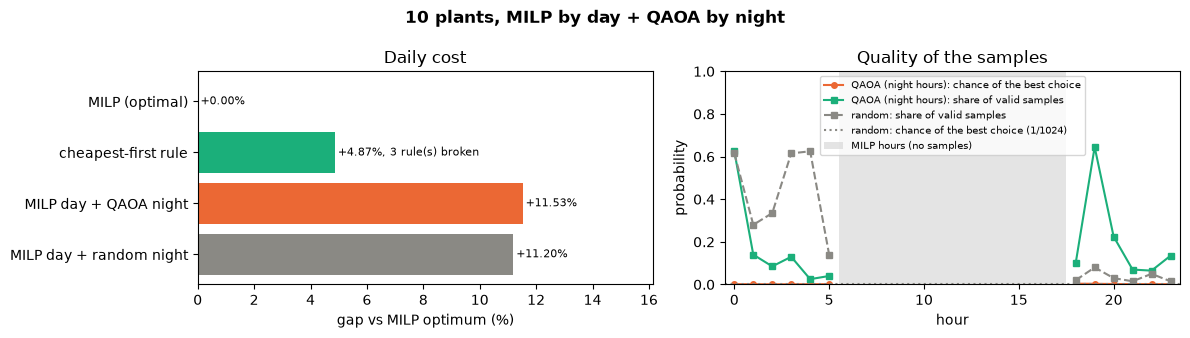

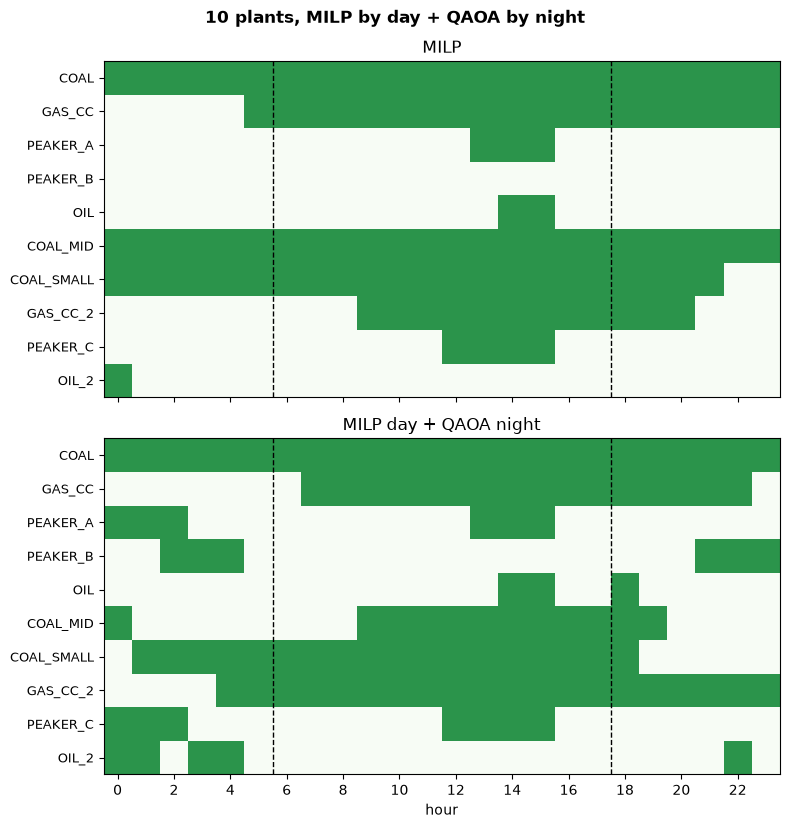

In [ ]:
# ==================== Hybrid B: MILP by day, QAOA by night (10 plants) ====================
hybrid_night_qaoa = run_hybrid_10_plant_test(NIGHT_HOURS, "MILP day + QAOA night", "MILP day + random night")
report_fleet_day("10 plants, MILP by day + QAOA by night", hybrid_night_qaoa["results"],
                 hybrid_night_qaoa["runs"]["qaoa"]["log"], hybrid_night_qaoa["runs"]["random"]["log"],
                 ten_plant_results["milp_schedule"], hybrid_night_qaoa["runs"]["qaoa"]["schedule"],
                 "MILP day + QAOA night", ten_names, sampler_name="QAOA (night hours)",
                 milp_hours=hybrid_night_qaoa["milp_hours"])
# ================== End of hybrid B ==================




### E 7 — One-hour selection sweep

Hands one hour at a time to QAOA. This helped propose candidate periods; it does not establish the best multi-hour period.


One hour at a time: QAOA decides that hour (all 10 plants), the MILP the other 23.
  hour  0: extra cost +1.75% (seeds +1.63, +2.00, +1.63) | spare 17 blocks | QUBO = exact: yes | needs lookahead: yes
  hour  1: extra cost +0.41% (seeds +0.38, +0.00, +0.85) | spare 18 blocks | QUBO = exact: yes | needs lookahead: no
  hour  2: extra cost +2.12% (seeds +0.40, +0.58, +5.38) | spare 19 blocks | QUBO = exact: yes | needs lookahead: no
  hour  3: extra cost +2.04% (seeds +0.40, +0.49, +5.24) | spare 19 blocks | QUBO = exact: yes | needs lookahead: no
  hour  4: extra cost +0.32% (seeds +0.40, +0.00, +0.56) | spare 18 blocks | QUBO = exact: yes | needs lookahead: no
  hour  5: extra cost +0.36% (seeds +0.62, +0.23, +0.23) | spare 17 blocks | QUBO = exact: yes | needs lookahead: yes
  hour  6: extra cost +4.71% (seeds +0.40, +7.06, +6.68) | spare 15 blocks | QUBO = exact: no  | needs lookahead: no
  hour 8: the MILP had to break a min up/down lock
  hour 8: the MILP had to break a min up/down

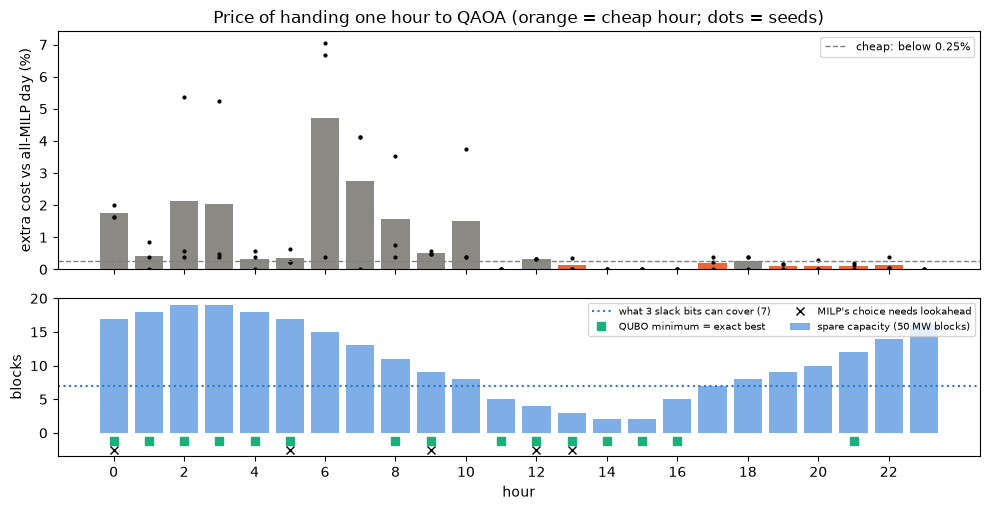

In [ ]:
# ==================== Which hours suit QAOA best? A one-hour-at-a-time sweep (10 plants) ====================
# Hand ONE hour to QAOA and let the MILP do the other 23 (re-planned after that hour, as in the hybrids).
# The extra cost over the all-MILP day is the price of giving that hour to QAOA; it is averaged over seeds.
# Next to it, three facts about each hour that explain the price:
#   * spare blocks: capacity minus demand + reserve, in 50 MW blocks. The 3 slack bits only cover 0..7, so
#     with more spare than that the QUBO punishes valid cheap choices (mostly at night).
#   * QUBO = exact: the QUBO's minimum matches the exact best choice for that hour (from the 10 plant run).
#   * needs lookahead: the MILP's own choice for that hour is NOT the cheapest choice for that hour alone,
#     so the right answer depends on later hours, which hour-by-hour QAOA cannot see.
SWEEP_SEEDS = (7, 8, 9)
QAOA_HOUR_MAX_EXTRA_PCT = 0.25        # an hour is "cheap" for QAOA if handing it over costs at most this much


def qaoa_hour_sweep(seeds=SWEEP_SEEDS, shots=200):
    base = ten_plant_results
    fleet, load, margin, milp_sched = base["plants"], base["demand"], base["reserve"], base["milp_schedule"]
    blocks = sum(p["pmax_mw"] for p in fleet) / BLOCK_MW
    rows = []
    with fleet_globals(fleet, load, margin):
        for t in hours:
            extra, valid = [], []
            for seed in seeds:
                schedule, _ = schedule_day_hybrid([t], p=1, shots=shots, sampler="qaoa", seed=seed)
                result = check_schedule(fleet, load, margin, schedule, milp_cost=base["milp_cost"], verbose=False)
                extra.append(result["gap_pct"])
                valid.append(result["valid"])
            was = milp_sched[t - 1] if t else [int(p["on_at_start"]) for p in fleet]
            must_on, must_off = locks(fleet, list(milp_sched[:t]))
            greedy = check_hour(fleet, load[t], margin[t], milp_sched[t], was, must_on, must_off, verbose=False)
            rows.append(dict(hour=int(t), extra_pct=extra, mean_extra_pct=float(np.mean(extra)),
                             all_valid=all(valid),
                             spare_blocks=int(blocks - np.ceil((load[t] + margin[t]) / BLOCK_MW)),
                             qubo_matches_exact=bool(base["hourly_checks"][t]["matches_best"]),
                             needs_lookahead=not greedy["matches_best"]))
            print(f"  hour {t:>2}: extra cost {np.mean(extra):+.2f}% (seeds {', '.join(f'{e:+.2f}' for e in extra)})"
                  f"{'' if all(valid) else ', a rule was broken'} | spare {rows[-1]['spare_blocks']:>2} blocks"
                  f" | QUBO = exact: {'yes' if rows[-1]['qubo_matches_exact'] else 'no '}"
                  f" | needs lookahead: {'yes' if rows[-1]['needs_lookahead'] else 'no'}", flush=True)
    return rows


print("One hour at a time: QAOA decides that hour (all 10 plants), the MILP the other 23.")
sweep_start = time.perf_counter()
hour_sweep = qaoa_hour_sweep()
print(f"Sweep done in {time.perf_counter() - sweep_start:.0f} s")
cheap_hours = [r["hour"] for r in hour_sweep if r["all_valid"] and r["mean_extra_pct"] <= QAOA_HOUR_MAX_EXTRA_PCT]
# A one-hour MILP island inside a QAOA stretch is not a practical plan: fill single-hour gaps. This set is
# one CANDIDATE for the window comparison below; the one-hour prices do not simply add up.
sweep_window = sorted(set(cheap_hours) | {h for h in range(1, 23) if h - 1 in cheap_hours and h + 1 in cheap_hours})
print(f"Hours where QAOA alone costs at most {QAOA_HOUR_MAX_EXTRA_PCT}% extra: {hour_stretches(cheap_hours)}")
print(f"Candidate window from the sweep (single-hour gaps filled): {hour_stretches(sweep_window)}")

fig, axes = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
sweep_hours = [r["hour"] for r in hour_sweep]
axes[0].bar(sweep_hours, [r["mean_extra_pct"] for r in hour_sweep],
            color=[COLORS["qaoa"] if h in cheap_hours else COLORS["random"] for h in sweep_hours])
for r in hour_sweep:
    axes[0].plot([r["hour"]] * len(r["extra_pct"]), r["extra_pct"], "k.", ms=4)
axes[0].axhline(QAOA_HOUR_MAX_EXTRA_PCT, color="gray", ls="--", lw=1, label=f"cheap: below {QAOA_HOUR_MAX_EXTRA_PCT}%")
axes[0].set(ylabel="extra cost vs all-MILP day (%)",
            title="Price of handing one hour to QAOA (orange = cheap hour; dots = seeds)")
axes[0].legend(fontsize=8)
axes[1].bar(sweep_hours, [r["spare_blocks"] for r in hour_sweep], color=COLORS["milp"], alpha=0.6,
            label="spare capacity (50 MW blocks)")
axes[1].axhline(2 ** N_SLACK - 1, color=COLORS["milp"], ls=":", label=f"what {N_SLACK} slack bits can cover (7)")
axes[1].plot([r["hour"] for r in hour_sweep if r["qubo_matches_exact"]],
             [-1.2] * sum(r["qubo_matches_exact"] for r in hour_sweep), "s", color=COLORS["rule"], ms=6,
             label="QUBO minimum = exact best")
axes[1].plot([r["hour"] for r in hour_sweep if r["needs_lookahead"]],
             [-2.6] * sum(r["needs_lookahead"] for r in hour_sweep), "x", color="black", ms=6,
             label="MILP's choice needs lookahead")
axes[1].set(xlabel="hour", ylabel="blocks", xticks=range(0, 24, 2), ylim=(-3.5, None))
axes[1].legend(fontsize=7, ncol=2, loc="upper right")
plt.tight_layout()
plt.show()
# ================== End of the sweep ==================




### E 8 — Initial candidate-window comparison

Compares six candidates of differing lengths. The later NIGHT/DAY study supplies the broader equal-length comparison.


QAOA window         hours                        QAOA hours  mean gap     min     max  valid days
night 18-6h (B)     [(0, 5), (18, 23)]                   12    +8.69%  +6.85% +11.53%        3/3
day 6-18h (A)       [(6, 17)]                            12    +7.68%  +2.92% +10.38%        2/3
peak 11-18h         [(11, 17)]                            7    +0.84%  +0.68%  +1.11%        3/3
13-18h              [(13, 17)]                            5    +0.19%  +0.01%  +0.42%        3/3
11-20h (C)          [(11, 19)]                            9    +1.11%  +0.74%  +1.43%        3/3
sweep 11-24h        [(11, 23)]                           13    +2.36%  +1.05%  +4.43%        3/3


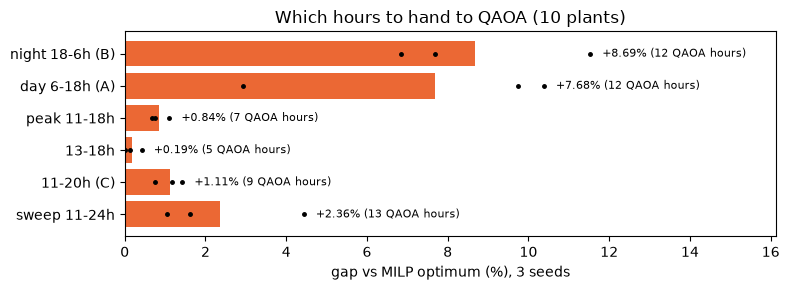

Best window: 13-18h -> QAOA hours [(13, 17)], mean gap +0.19% over 3 seeds


In [ ]:
# ==================== Window comparison: which QAOA hours give the cheapest valid day? ====================
# The one-hour prices above are not additive (each hour changes the history the next one sees), so the
# candidate windows are run whole, each with 3 seeds. All 10 plants are decided in every QAOA hour.
# The window with the lowest mean gap that is valid in every seed becomes QAOA_BEST_HOURS (hybrid D).
WINDOWS = {"night 18-6h (B)": NIGHT_HOURS, "day 6-18h (A)": list(DAY_HOURS), "peak 11-18h": list(range(11, 18)),
           "13-18h": list(range(13, 18)), "11-20h (C)": list(range(11, 20)),
           f"sweep {sweep_window[0]}-{sweep_window[-1] + 1}h": sweep_window}
window_rows = []
with fleet_globals(ten_plant_results["plants"], ten_plant_results["demand"], ten_plant_results["reserve"]):
    for name, window in WINDOWS.items():
        gaps, valid = [], []
        for seed in SWEEP_SEEDS:
            schedule, _ = schedule_day_hybrid(window, p=1, shots=200, sampler="qaoa", seed=seed)
            r = check_schedule(plants, demand, reserve, schedule, milp_cost=ten_plant_results["milp_cost"], verbose=False)
            gaps.append(r["gap_pct"])
            valid.append(r["valid"])
        window_rows.append(dict(name=name, hours=hour_stretches(window), n_qaoa_hours=len(window), gaps=gaps,
                                mean_gap=float(np.mean(gaps)), valid_days=sum(valid)))
print(f"{'QAOA window':<20}{'hours':<28}{'QAOA hours':>11}{'mean gap':>10}{'min':>8}{'max':>8}{'valid days':>12}")
for r in window_rows:
    print(f"{r['name']:<20}{str(r['hours']):<28}{r['n_qaoa_hours']:>11}{r['mean_gap']:>+9.2f}%"
          f"{min(r['gaps']):>+7.2f}%{max(r['gaps']):>+7.2f}%{r['valid_days']:>9}/{len(SWEEP_SEEDS)}")
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh([r["name"] for r in window_rows], [r["mean_gap"] for r in window_rows], color=COLORS["qaoa"])
for y, r in enumerate(window_rows):
    ax.plot(r["gaps"], [y] * len(r["gaps"]), "k.", ms=5)
    ax.text(max(r["gaps"]) + 0.3, y, f"{r['mean_gap']:+.2f}% ({r['n_qaoa_hours']} QAOA hours)", va="center", fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, 1.4 * max(max(r["gaps"]) for r in window_rows))
ax.set(xlabel="gap vs MILP optimum (%), 3 seeds", title="Which hours to hand to QAOA (10 plants)")
plt.tight_layout()
plt.show()
best_window = min((r for r in window_rows if r["valid_days"] == len(SWEEP_SEEDS)), key=lambda r: r["mean_gap"])
QAOA_BEST_HOURS = WINDOWS[best_window["name"]]
print(f"Best window: {best_window['name']} -> QAOA hours {hour_stretches(QAOA_BEST_HOURS)}, "
      f"mean gap {best_window['mean_gap']:+.2f}% over {len(SWEEP_SEEDS)} seeds")
# ================== End of the window comparison ==================




### E 9 — 11:00–20:00 hybrid

Earlier nine-hour candidate and plots.


Hybrid 10 plant run: QAOA hours [(11, 19)], MILP hours [(0, 10), (20, 23)], MILP horizon = day; local ideal simulation only.
  every QAOA hour decides all 10 plants (13 qubits: 10 plant + 3 slack)
  QAOA 11-20h + MILP rest: cost=$609,167.82, valid=True, gap=+1.17%, violations=0, time=4.65 s (MILP 0.09 s, qaoa hours 4.57 s)
  random 11-20h + MILP rest: cost=$632,660.78, valid=True, gap=+5.07%, violations=0, time=0.32 s (MILP 0.07 s, random hours 0.25 s)

10 plants, QAOA 11:00-20:00 + MILP the rest
method                          daily cost $       gap  rules broken
MILP (optimal)                       602,139    +0.00%             0
cheapest-first rule                  631,461    +4.87%             3
QAOA 11-20h + MILP rest              609,168    +1.17%             0
random 11-20h + MILP rest            632,661    +5.07%             0


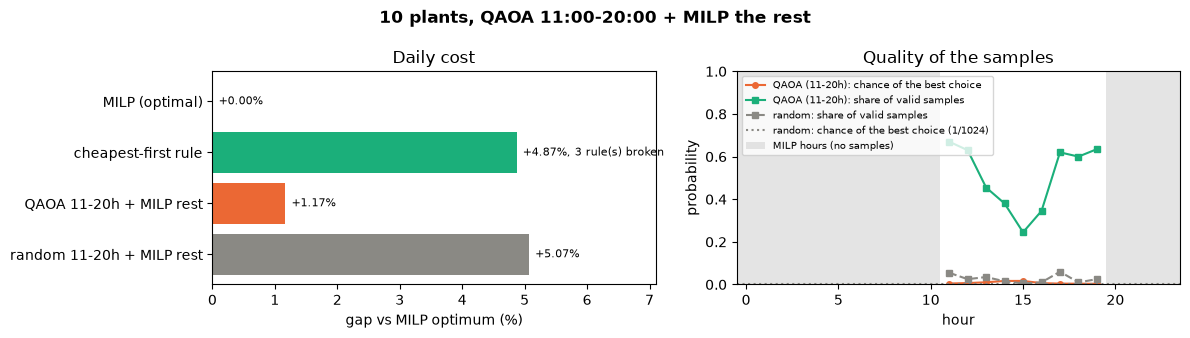

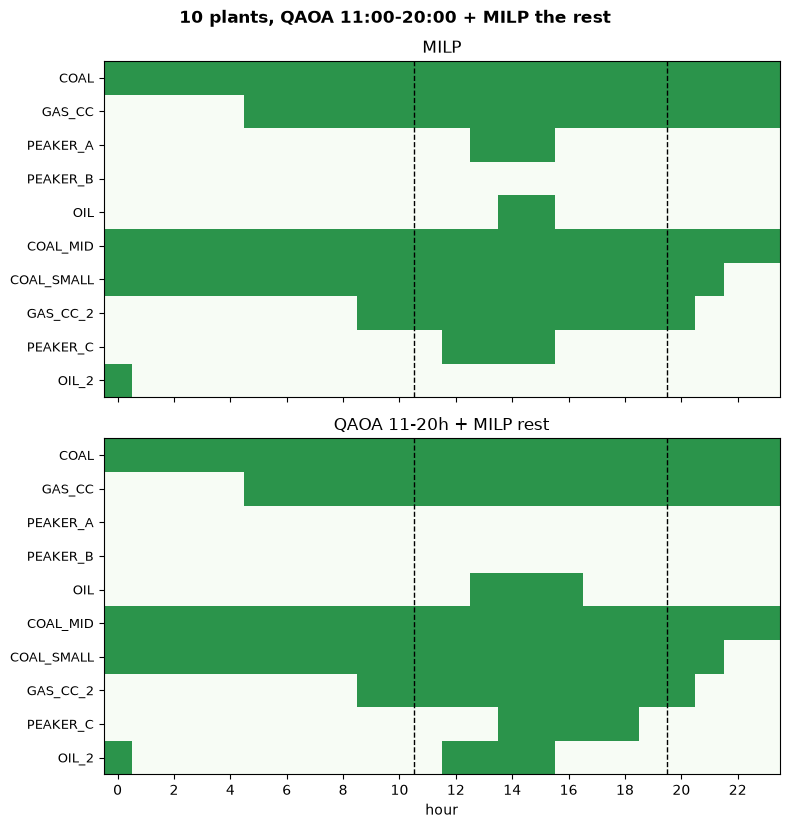

In [ ]:
# ==================== Hybrid C: QAOA 11:00 to 20:00 (hours 11-19), MILP the rest (10 plants) ====================
hybrid_11_to_20 = run_hybrid_10_plant_test(range(11, 20), "QAOA 11-20h + MILP rest", "random 11-20h + MILP rest")
report_fleet_day("10 plants, QAOA 11:00-20:00 + MILP the rest", hybrid_11_to_20["results"],
                 hybrid_11_to_20["runs"]["qaoa"]["log"], hybrid_11_to_20["runs"]["random"]["log"],
                 ten_plant_results["milp_schedule"], hybrid_11_to_20["runs"]["qaoa"]["schedule"],
                 "QAOA 11-20h + MILP rest", ten_names, sampler_name="QAOA (11-20h)",
                 milp_hours=hybrid_11_to_20["milp_hours"])
# ================== End of hybrid C ==================




### E 10 — Selected candidate hybrid

Uses the winner of E 8. This is an exploratory selection, not the final reduced-qubit implementation.


Hybrid 10 plant run: QAOA hours [(13, 17)], MILP hours [(0, 12), (18, 23)], MILP horizon = day; local ideal simulation only.
  every QAOA hour decides all 10 plants (13 qubits: 10 plant + 3 slack)
  QAOA best window + MILP rest: cost=$604,672.62, valid=True, gap=+0.42%, violations=0, time=3.18 s (MILP 0.09 s, qaoa hours 3.09 s)
  random best window + MILP rest: cost=$612,464.27, valid=True, gap=+1.71%, violations=0, time=0.29 s (MILP 0.09 s, random hours 0.20 s)

10 plants, QAOA in [(13, 17)] + MILP the rest
method                          daily cost $       gap  rules broken
MILP (optimal)                       602,139    +0.00%             0
cheapest-first rule                  631,461    +4.87%             3
QAOA best window + MILP rest         604,673    +0.42%             0
random best window + MILP rest       612,464    +1.71%             0


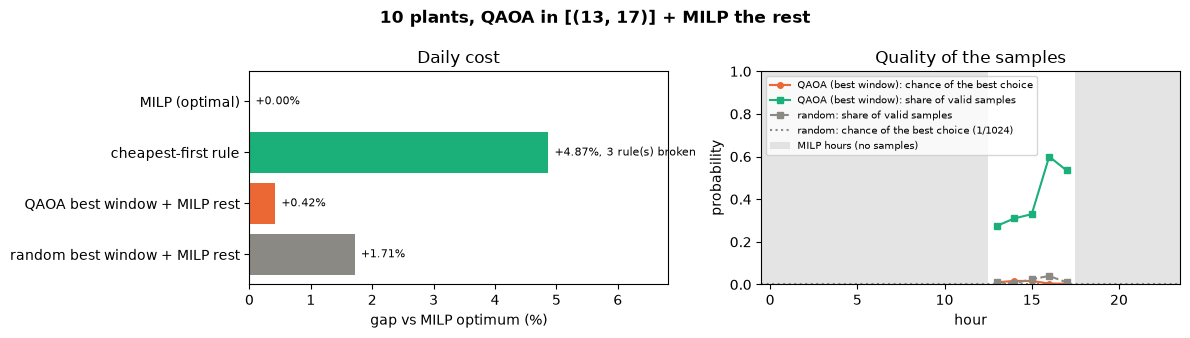

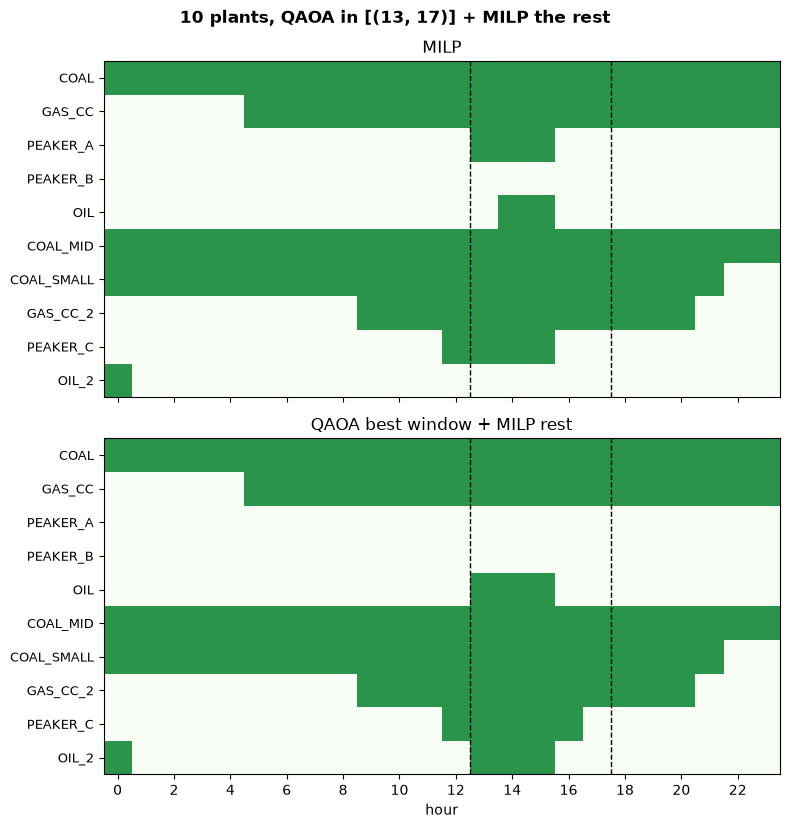

In [ ]:
# ==================== Hybrid D: QAOA in the best window from the comparison, MILP the rest (10 plants) ====================
hybrid_best_hours = run_hybrid_10_plant_test(QAOA_BEST_HOURS, "QAOA best window + MILP rest", "random best window + MILP rest")
report_fleet_day(f"10 plants, QAOA in {hour_stretches(QAOA_BEST_HOURS)} + MILP the rest", hybrid_best_hours["results"],
                 hybrid_best_hours["runs"]["qaoa"]["log"], hybrid_best_hours["runs"]["random"]["log"],
                 ten_plant_results["milp_schedule"], hybrid_best_hours["runs"]["qaoa"]["schedule"],
                 "QAOA best window + MILP rest", ten_names, sampler_name="QAOA (best window)",
                 milp_hours=hybrid_best_hours["milp_hours"])
# ================== End of hybrid D ==================


<a id="stretch-studies"></a>
## Supporting studies — stretch goals and scaling

These are separate experiments, not prerequisites for RQ 1–RQ 5.


In [ ]:
# ==================== Stretch goals from background/README.md: definitions and test plans ====================
# TVA's original problem (background/README.md, "What TVA asked"): 10 to 20 units over 24 hours, thermal
# units AND storage, startup costs, min up/down times AND ramp limits, load + reserve every hour, a hybrid
# solver compared with a classical MIP. The track kept 5 thermal plants and made the rest stretch goals:
#   1. 10 plants (TVA asked for 10 to 20)      3. a battery (TVA's "storage")
#   2. ramp limits (TVA's "ramping")           4. wind and solar, i.e. scheduling against net load
# This cell defines each goal, how we test it, the metrics, and when it counts as done. Every section ends
# with a cheap "probe" that establishes the starting facts, then a marked slot for the real experiment.
# The probes run in a few seconds: local MILPs and arithmetic only, no QAOA and no cloud jobs.
import copy
import math
from check import DATA

FLEETS = {5: (load_plants(DATA / "plants.csv"), *load_demand(DATA / "demand.csv")),
          10: (load_plants(DATA / "plants10.csv"), *load_demand(DATA / "demand10.csv"))}
BASELINE = {n: solve_milp(f, d, r) for n, (f, d, r) in FLEETS.items()}   # (cost, schedule, dispatch, secs)


def slack_bits_needed(fleet, load, margin, block_mw=BLOCK_MW):
    # Spare capacity, in 50 MW blocks, that the slack qubits must be able to spell out each hour.
    total_blocks = sum(p["pmax_mw"] for p in fleet) / block_mw
    spare = [int(total_blocks - math.ceil((d + r) / block_mw)) for d, r in zip(load, margin)]
    return spare, math.ceil(math.log2(max(spare) + 1))


# ==================== Stretch goal 1: 10 plants (TVA asked for 10 to 20 units) ====================
# DEFINITION  Same rules, same day, the 10 plant fleet in data/plants10.csv and data/demand10.csv
#             (1,500 MW of capacity, peak 1,235 MW). One hour is 10 plant qubits + slack qubits, so
#             2^10 = 1,024 on/off choices instead of 32. The README's question: how many slack qubits does
#             the safety-margin rule need now? With 3 bits the QUBO can only "forgive" 7 spare blocks
#             (350 MW); at night the fleet has far more spare than that, so the penalty punishes valid,
#             cheap choices and the QUBO's minimum stops matching the exact best (15/24 hours above).
# WHAT WE TEST  (a) slack width: 3 bits (as above) vs the width the probe computes, QUBO-vs-exact match
#             rate over the 24 hours; (b) the full hour-by-hour day and the hybrids above with that width;
#             (c) scaling evidence for TVA's "10 to 20 units": qubits, number of RZZ gates, statevector
#             size and seconds per hour at 5, 10 (and 15, 20 if we extend the fleet from RTS-GMLC).
#             15+ plant qubits plus slack is too big for a local statevector: that is where qBraid's GPU
#             simulator (qbraid:qbraid:sim:gpu-sv, up to 35 qubits) or the penalty-only QUBO comes in.
# METRICS     QUBO match rate /24, share of valid samples, P(best), daily cost gap vs the 10 plant MILP,
#             rules broken, seconds per hour (classical tuning included), two-qubit gate count.
# DONE WHEN   the 10 plant day is valid, its gap is reported for both slack widths, and we can show a
#             table of qubits / gates / time against fleet size and say where local simulation stops.
print("Stretch goal 1: 10 plants")
for n, (fleet, load, margin) in FLEETS.items():
    spare, bits = slack_bits_needed(fleet, load, margin)
    cost, _, _, secs = BASELINE[n]
    print(f"  {n:>2} plants: MILP ${cost:,.0f} in {secs:.2f} s | spare blocks per hour "
          f"{min(spare)}..{max(spare)} -> {bits} slack bits needed (notebook uses {N_SLACK}; "
          f"hours the 3 bits cannot cover: {sum(s > 2 ** N_SLACK - 1 for s in spare)}/24)")
# Optional extension (not implemented here): rerun run_10_plant_test with n_slack = the width above and compare match rate,
# valid share and gap with the 3 bit run; add the qubits / gates / seconds table against fleet size.
# ================== End of stretch goal 1 ==================


# ==================== Stretch goal 2: ramp limits (TVA's "ramping") ====================
# DEFINITION  A plant that is on in two consecutive hours may change its output by at most
#             ramp_mw_per_h (data column, from RTS-GMLC's MW/min x 60, scaled with the plant). This
#             couples the hours: the on/off choice is still per hour, but the dispatch of hour t now
#             depends on hour t-1. The checker and the MILP already know the rule:
#             solve_milp(..., ramps=True) and check_schedule(..., ramps=True).
# CAVEAT      check_schedule dispatches each hour on its own (cheapest first), so once ramps bind it can
#             flag the MILP's own schedule as "ramp broken" and show a negative gap. Use the dispatch and
#             cost that solve_milp returns, or (the tool worth building) a ramp-aware dispatch for the checker.
# WHAT WE TEST  (a) do ramps matter at all at RTS rates? The probe solves the MILP with and without
#             ramps on both fleets and counts ramp violations in the no-ramp schedule. (b) tighten the
#             rates (x0.5, x0.25, x0.1) and find where the cost starts to rise and where the day becomes
#             infeasible. (c) hour-by-hour loop with ramps: keep the previous hour's dispatch, and only
#             accept a sampled on/off choice if a dispatch exists that meets demand within the ramp
#             limits (a small LP, or cheapest-first with per-plant bounds). (d) compare the loop's cost
#             and violations with the ramp MILP at each tightening factor.
# METRICS     MILP cost with vs without ramps, ramp violations found by the checker, loop gap vs the
#             ramp MILP, hours where the loop found no ramp-feasible choice, MILP seconds.
# DONE WHEN   a ramp-aware dispatch exists so the checker agrees with the MILP cost at every factor, and
#             the loop's schedule is valid under check_schedule(..., ramps=True) with its gap reported.
def with_ramps_scaled(fleet, factor):
    scaled = copy.deepcopy(fleet)
    for p in scaled:
        p["ramp_mw_per_h"] = p["ramp_mw_per_h"] * factor
    return scaled


print("\nStretch goal 2: ramp limits (MILP with ramps=True; 'flagged' = ramp violations the checker finds)")
RAMP_FACTORS = (1.0, 0.5, 0.25, 0.1)
ramp_probe = {}
for n, (fleet, load, margin) in FLEETS.items():
    base_cost, base_schedule = BASELINE[n][0], BASELINE[n][1]
    for factor in RAMP_FACTORS:
        scaled = with_ramps_scaled(fleet, factor)
        flagged_base = len([v for v in check_schedule(scaled, load, margin, base_schedule, ramps=True,
                                                      verbose=False)["violations"] if v[2] == "ramp broken"])
        try:
            cost, schedule, dispatch, secs = solve_milp(scaled, load, margin, ramps=True)
            flagged = len([v for v in check_schedule(scaled, load, margin, schedule, ramps=True,
                                                     verbose=False)["violations"] if v[2] == "ramp broken"])
            ramp_probe[(n, factor)] = dict(cost=cost, schedule=schedule, dispatch=dispatch, secs=secs)
            print(f"  {n:>2} plants, ramps x{factor:<5}: ramp MILP ${cost:,.0f} ({100 * (cost / base_cost - 1):+.2f}% "
                  f"vs no ramps, {secs:.2f} s), checker flags {flagged} in it; "
                  f"no-ramp schedule breaks ramps {flagged_base} time(s)")
        except RuntimeError:
            print(f"  {n:>2} plants, ramps x{factor:<5}: no feasible day (ramps too tight); "
                  f"no-ramp schedule breaks ramps {flagged_base} time(s)")
# Optional extension (not implemented here): write dispatch_with_ramps(plants, demand, on, previous_output) and a ramp-aware
# hour_ok for schedule_day; run the loop at each factor; table of cost gap and violations vs the ramp MILP.
# ================== End of stretch goal 2 ==================


# ==================== Stretch goal 3: a battery (TVA's "storage") ====================
# DEFINITION  One storage unit with a power limit (MW in or out), an energy limit (MWh), a round-trip
#             efficiency and a state of charge (SOC) that carries from hour to hour:
#                 soc[t+1] = soc[t] + eff_in * charge[t] - discharge[t] / eff_out,  0 <= soc <= energy_mwh
#             Charging adds to the demand the plants must meet, discharging subtracts from it. A rule to
#             stop it cheating: end the day with at least the SOC it started with. Whether its discharge
#             power also counts toward the reserve is a modelling choice; state it either way.
# WHY IT IS HARD HOUR BY HOUR  The battery is intertemporal (TVA: "charging now is evaluated against the
#             expected value of discharging later"), while our loop decides one hour at a time.
# WHAT WE TEST  (a) MILP with the battery (new variables charge, discharge, soc per hour) vs the MILP
#             without: the cost difference is the value of the battery; plot the SOC and the net demand.
#             (b) how it enters the hour-by-hour loop. Plan A (classical pre-plan): decide the battery
#             first, with a peak-shaving rule or the MILP's own battery plan, turn it into a net demand
#             with battery_net_demand below, then run QAOA on that demand exactly as now. Plan B (quantum):
#             add 1 or 2 qubits per hour for "discharge 0 / 50 / 100 MW" and let the sampler decide, with
#             the SOC checked classically like the min up/down locks. (c) sizes: 50 MW / 200 MWh for the
#             5 plant fleet (one block, 4 hours), 100 MW / 400 MWh for 10 plants; then a sweep.
# METRICS     daily cost vs the battery MILP, value of the battery in $/day, peak net demand reduction,
#             SOC bound violations, number of plant startups avoided, rules broken.
# DONE WHEN   the battery MILP solves and its SOC chart makes sense, the loop (plan A at least) gives a
#             valid day on the net demand, and its gap vs the battery MILP is reported.
BATTERY = dict(power_mw=50, energy_mwh=200, eff_in=0.95, eff_out=0.95, soc_start_mwh=0)


def battery_net_demand(demand, charge_mw, discharge_mw, battery=BATTERY):
    # Net demand the plants must meet, plus the SOC path and the rules the plan breaks.
    charge, discharge = np.asarray(charge_mw, float), np.asarray(discharge_mw, float)
    soc, problems = [battery["soc_start_mwh"]], []
    for t in range(len(demand)):
        if charge[t] > battery["power_mw"] + 1e-9 or discharge[t] > battery["power_mw"] + 1e-9:
            problems.append((t, "power limit broken"))
        if charge[t] > 0 and discharge[t] > 0:
            problems.append((t, "charging and discharging at once"))
        soc.append(soc[-1] + battery["eff_in"] * charge[t] - discharge[t] / battery["eff_out"])
        if not -1e-9 <= soc[-1] <= battery["energy_mwh"] + 1e-9:
            problems.append((t, f"SOC out of range ({soc[-1]:.0f} MWh)"))
    if soc[-1] < battery["soc_start_mwh"] - 1e-9:
        problems.append((len(demand) - 1, "ends below the starting SOC"))
    return np.asarray(demand, float) + charge - discharge, np.array(soc), problems


# Probe: the simplest plan A rule. Starting empty, 4 hours of charging fill the 200 MWh (4 x 50 x 0.95) and
# 4 hours of discharging at the peaks empty it again, so the day ends where it started.
print("\nStretch goal 3: a battery (plan A probe: charge at the 4 lowest-demand hours, discharge at the 4 peaks)")
fleet5, load5, margin5 = FLEETS[5]
charge = np.zeros(24)
discharge = np.zeros(24)
charge[np.argsort(load5)[:4]] = BATTERY["power_mw"]
discharge[np.argsort(-load5)[:4]] = BATTERY["power_mw"] * BATTERY["eff_in"] * BATTERY["eff_out"]
net5, soc5, problems5 = battery_net_demand(load5, charge, discharge)
print(f"  peak demand {load5.max():.0f} MW -> {net5.max():.0f} MW with the battery; "
      f"SOC {soc5.min():.0f}..{soc5.max():.0f} MWh; plan problems: {problems5 or 'none'}")
battery_rule_cost = solve_milp(fleet5, net5, margin5)[0]
print(f"  5 plant MILP on that net demand: ${battery_rule_cost:,.0f} vs ${BASELINE[5][0]:,.0f} without "
      f"({100 * (battery_rule_cost / BASELINE[5][0] - 1):+.2f}%); a real battery MILP should do at least this well")
# Optional extension (not implemented here): extend solve_milp with charge / discharge / soc variables (the battery MILP),
# then run schedule_day on battery_net_demand(...) (plan A) and, if time allows, plan B with battery qubits.
# ================== End of stretch goal 3 ==================


# ==================== Stretch goal 4: wind and solar (schedule against net load) ====================
# DEFINITION  Net load = demand - wind - solar. Renewables cost nothing to run, so the thermal plants only
#             have to cover what is left. The reserve should grow with the renewable forecast error (TVA:
#             reserves cover "renewable forecast error"); a simple rule is 10% of demand + a share of the
#             renewable output. TVA's overview flags the EVENING RAMP, when solar fades while demand is
#             still high, as the growing challenge: the thermal fleet must climb fast, so startups and
#             min up/down times bite.
# DATA        RTS-GMLC time series for the same day as our demand (region 3, July 14 2020):
#               RTS_Data/timeseries_data_files/WIND/DAY_AHEAD_wind.csv
#               RTS_Data/timeseries_data_files/PV/DAY_AHEAD_pv.csv    (and RTP for rooftop PV)
#             Their region-3 totals are in data/renewables.csv (built by data/make_renewables.py), scaled
#             here to a chosen share of our peak. synthetic=True keeps the earlier stand-in profile (a
#             solar bell curve and a flat-ish wind) for comparison; the probe below uses the real curves.
# WHAT WE TEST  (a) renewable share 0%, 15%, 30%, 45% of peak demand: net load shape, lowest net load,
#             biggest hour-to-hour climb (the evening ramp). (b) MILP and the hour-by-hour loop on each
#             net load: cost, startups, rules broken. (c) the QUBO's slack limit: low net load means more
#             spare capacity than 3 slack bits can express, so the match rate should fall; the probe
#             counts the slack bits each share needs. (d) the hybrids above on net load: does MILP by
#             night / QAOA by day still win when the day hours carry the solar swing?
# METRICS     daily cost vs its own MILP, startups per day, max evening climb in MW/h, rules broken,
#             QUBO match rate, slack bits needed.
# DONE WHEN   a table of cost / violations / evening ramp by renewable share, from real RTS-GMLC curves,
#             with the hour-by-hour loop's gap next to the MILP for each share.
def renewable_profile(load, share_of_peak, solar_fraction=0.7, synthetic=False):
    # Hourly wind + solar in MW, scaled so that their combined peak is share_of_peak x the peak load.
    # synthetic=False: RTS-GMLC's region 3 day-ahead forecast for July 14 2020 (data/renewables.csv; its
    # own solar/wind mix, so solar_fraction is ignored). synthetic=True: the earlier stand-in shapes.
    if not synthetic:
        import csv
        with open(DATA / "renewables.csv", newline="") as f:
            real = np.array([float(r["solar_mw"]) + float(r["wind_mw"]) for r in csv.DictReader(f)])
        return real / real.max() * share_of_peak * load.max()
    t = np.arange(len(load))
    solar = np.clip(np.cos((t - 13) / 7 * np.pi / 2), 0, None) ** 1.5 * ((t >= 6) & (t <= 19))
    wind = 0.6 + 0.4 * np.cos((t - 3) / 24 * 2 * np.pi)
    total = share_of_peak * load.max()
    return solar / solar.max() * total * solar_fraction + wind / wind.max() * total * (1 - solar_fraction)


print("\nStretch goal 4: wind and solar (RTS-GMLC region 3 curves for July 14 2020, scaled to a share of our peak)")
print(f"  {'share':>6}{'min net MW':>12}{'peak net MW':>13}{'evening climb MW/h':>20}{'MILP $':>12}"
      f"{'slack bits':>12}{'hours > 3 bits':>16}")
net_load_probe = {}
for share in (0.0, 0.15, 0.30, 0.45):
    renew = renewable_profile(load5, share)
    net = np.maximum(load5 - renew, 0)
    reserve_net = np.round(0.10 * load5 + 0.20 * renew)        # 10% of demand + 20% of the renewable output
    climb = np.diff(net)[12:].max()                            # biggest afternoon/evening hour-to-hour rise
    spare, bits = slack_bits_needed(fleet5, net, reserve_net)
    try:
        cost = solve_milp(fleet5, net, reserve_net)[0]
        cost_text = f"{cost:,.0f}"
    except RuntimeError:
        cost, cost_text = None, "infeasible"
    net_load_probe[share] = dict(net=net, reserve=reserve_net, renewables=renew, milp_cost=cost)
    print(f"  {share:>6.0%}{net.min():>12.0f}{net.max():>13.0f}{climb:>20.0f}{cost_text:>12}"
          f"{bits:>12}{sum(s > 2 ** N_SLACK - 1 for s in spare):>16}")
# The real experiment (MILP re-solved on the net load, hybrid runs A/B/C with 3 seeds, curtailment check) is
# the "Wind and solar" cell after the hourly-window study. Still open: the hybrids on each share's net load.
# ================== End of stretch goal 4 ==================


# ==================== Also in the track README (not from the background folder) ====================
# Two hours at once: one QUBO for hours t and t+1 (16 qubits with 5 plants) so QAOA sees startup costs.
#   Test: match rate and gap vs the single-hour loop; qBraid's GPU simulator for the 10 plant version.
# Drop the helper qubits: penalty-only ("unbalanced penalization") QUBO with no slack bits.
#   Test: qubits, two-qubit gates and valid share vs the slack version, same shots and seeds.
# Check how often the approximate hourly cost picks the exact best across demand
#   levels, previous states and both fleets; explain a failure; improve it and re-measure the match rate.
# ================== End of the stretch goal plans ==================


### Supporting study — hypothetical 15/25/50-plant scaling

Separate from the measured ten-plant reduced-qubit results.


plants  capacity MW  peak MW  coal  gas CC  gas CT   oil  on at 0h
    10        1,500    1,235     3       2       3     2         2
    15        2,350    1,935     4       3       4     4         3
    25        3,650    3,006     6       5       6     8         5
    50        6,900    5,682    12      10      11    17         9

plants  spare 13-18h  bits 13-18h  spare all day  bits all day  hours 3 bits miss  qubits 13-18h
    10          2..7            3          2..19             5              17/24             13
    15         4..11            4          4..29             5              20/24             19
    25         6..17            5          6..46             6              22/24             30
    50        13..33            6         13..88             7              24/24             56

plants  qubits  RZZ / layer    bitstrings  statevector  where a QAOA hour can run
    10      13           78      8.19e+03         0 MB  this machine, exact
    15      19      

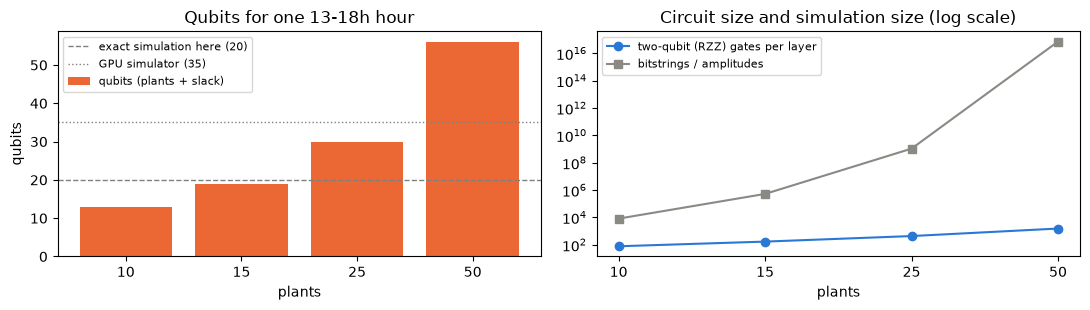


Fast QAOA simulator vs Qiskit Statevector (13 qubits): max |difference| = 4.0e-17; Qiskit 0.010 s, numpy 0.004 s per evaluation

10 plants: 13 qubits in the 13-18h window (10 plant + 3 slack), 78 RZZ per layer -> this machine, exact
  MILP $602,139 in 0.06 s; cheapest-first gap +4.87% with 3 rule(s) broken
  QAOA 13-18h + MILP rest: gap +0.42%, valid=True, 0 rule(s) broken, hour-best picks 3/5, 0.5 s (0.3 s sampling)
  annealing 13-18h + MILP rest (stand-in): gap +0.01%, valid=True, 0 rule(s) broken, hour-best picks 5/5, 0.4 s (0.2 s sampling)
  random 13-18h + MILP rest: gap +2.98%, valid=True, 0 rule(s) broken, hour-best picks 1/5, 0.2 s (0.0 s sampling)

10 plants, QAOA 13-18h + MILP the rest
method                          daily cost $       gap  rules broken
MILP (optimal)                       602,139    +0.00%             0
cheapest-first rule                  631,461    +4.87%             3
QAOA 13-18h + MILP rest              604,673    +0.42%             0
annealing 13-18h +

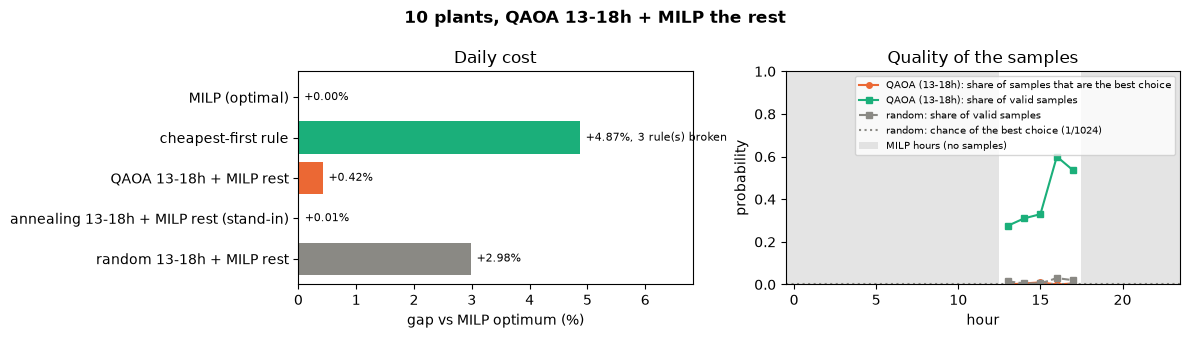

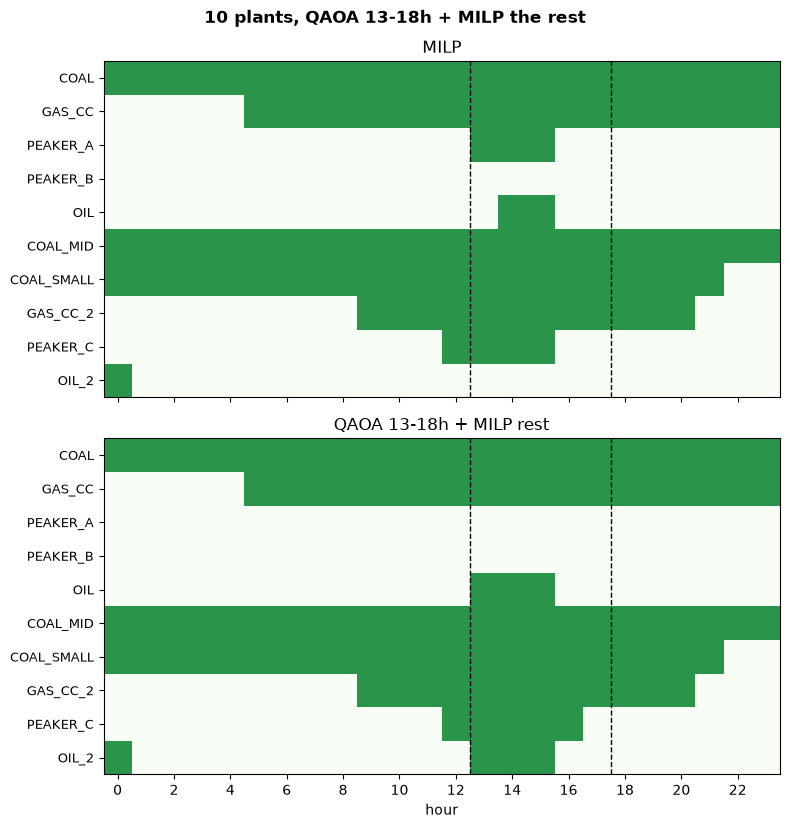


15 plants: 19 qubits in the 13-18h window (15 plant + 4 slack), 171 RZZ per layer -> this machine, exact
  MILP $915,570 in 0.16 s; cheapest-first gap +3.18% with 3 rule(s) broken
  QAOA 13-18h + MILP rest: gap +1.26%, valid=True, 0 rule(s) broken, hour-best picks 2/5, 35.5 s (35.2 s sampling)
  annealing 13-18h + MILP rest (stand-in): gap +0.49%, valid=True, 0 rule(s) broken, hour-best picks 4/5, 0.7 s (0.4 s sampling)
  random 13-18h + MILP rest: gap +21.35%, valid=False, 24 rule(s) broken, hour-best picks 0/5, 0.3 s (0.0 s sampling)

15 plants, QAOA 13-18h + MILP the rest
method                          daily cost $       gap  rules broken
MILP (optimal)                       915,570    +0.00%             0
cheapest-first rule                  944,700    +3.18%             3
QAOA 13-18h + MILP rest              927,072    +1.26%             0
annealing 13-18h + MILP rest (stand-in)       920,023    +0.49%             0
random 13-18h + MILP rest          1,111,006   +21.35%         

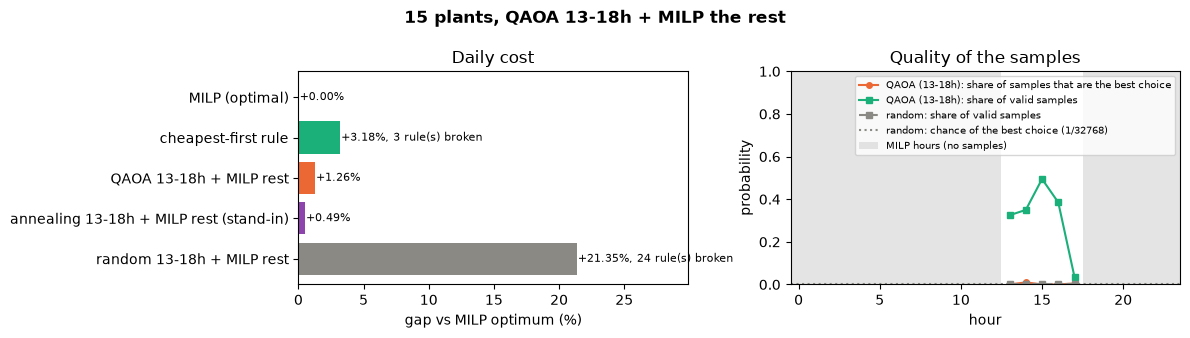

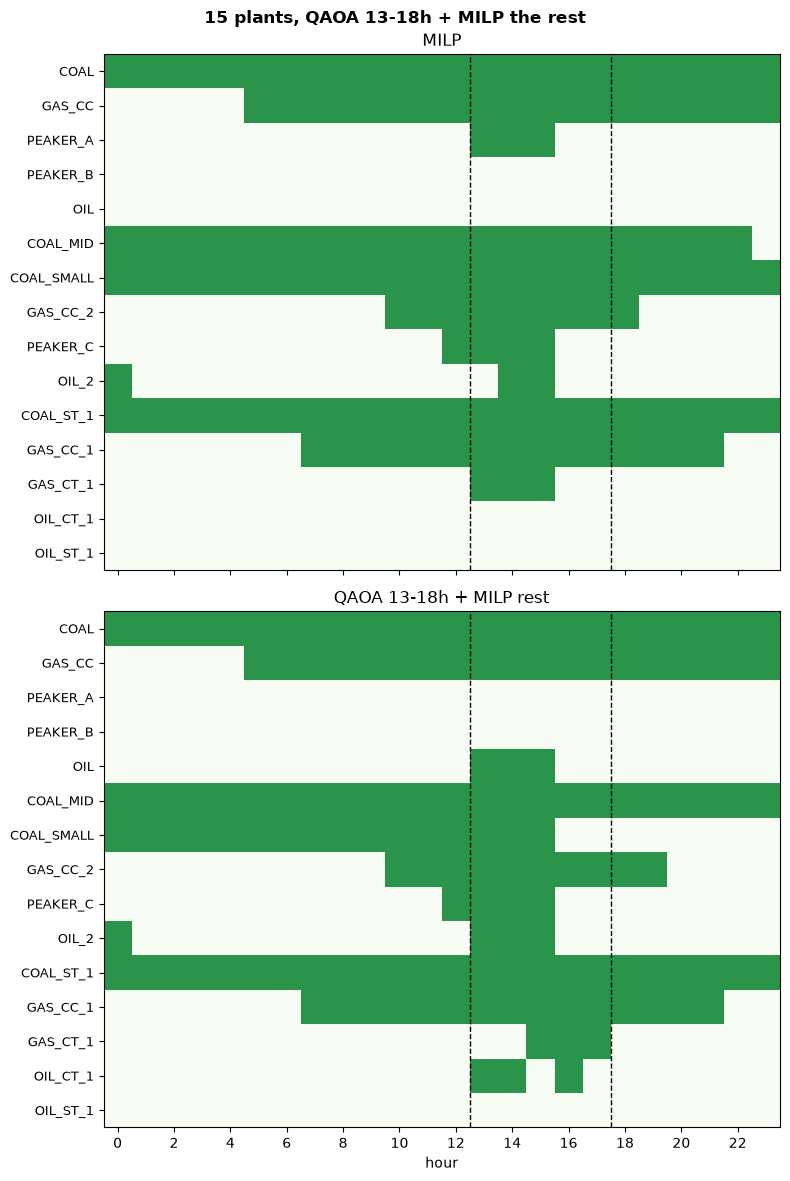


25 plants: 30 qubits in the 13-18h window (25 plant + 5 slack), 435 RZZ per layer -> qBraid GPU simulator
  MILP $1,462,400 in 0.20 s; cheapest-first gap +0.32% with 1 rule(s) broken
  QAOA: not simulated (30 qubits > 20); needs qBraid GPU simulator
  annealing 13-18h + MILP rest (stand-in): gap +0.81%, valid=True, 0 rule(s) broken, hour-best picks 3/5, 1.0 s (0.6 s sampling)
  random 13-18h + MILP rest: gap +14.71%, valid=False, 26 rule(s) broken, hour-best picks 0/5, 0.4 s (0.0 s sampling)

25 plants, annealing 13-18h + MILP the rest
method                          daily cost $       gap  rules broken
MILP (optimal)                     1,462,400    +0.00%             0
cheapest-first rule                1,467,030    +0.32%             1
annealing 13-18h + MILP rest (stand-in)     1,474,276    +0.81%             0
random 13-18h + MILP rest          1,677,529   +14.71%            26


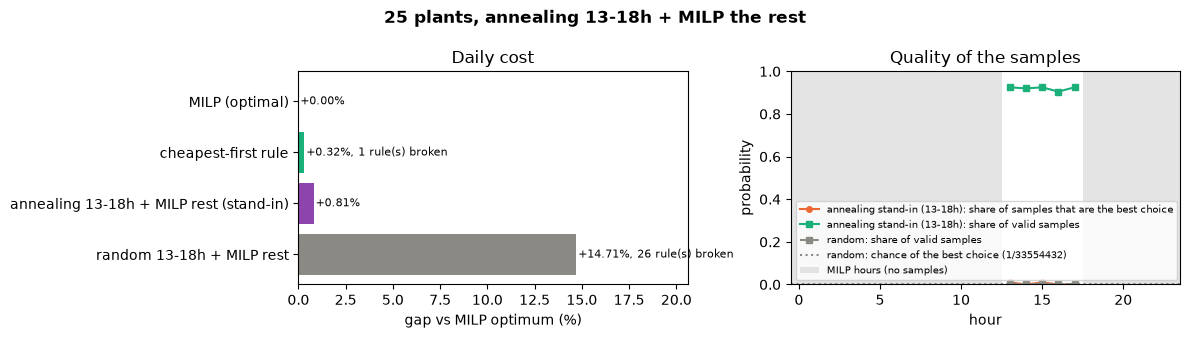

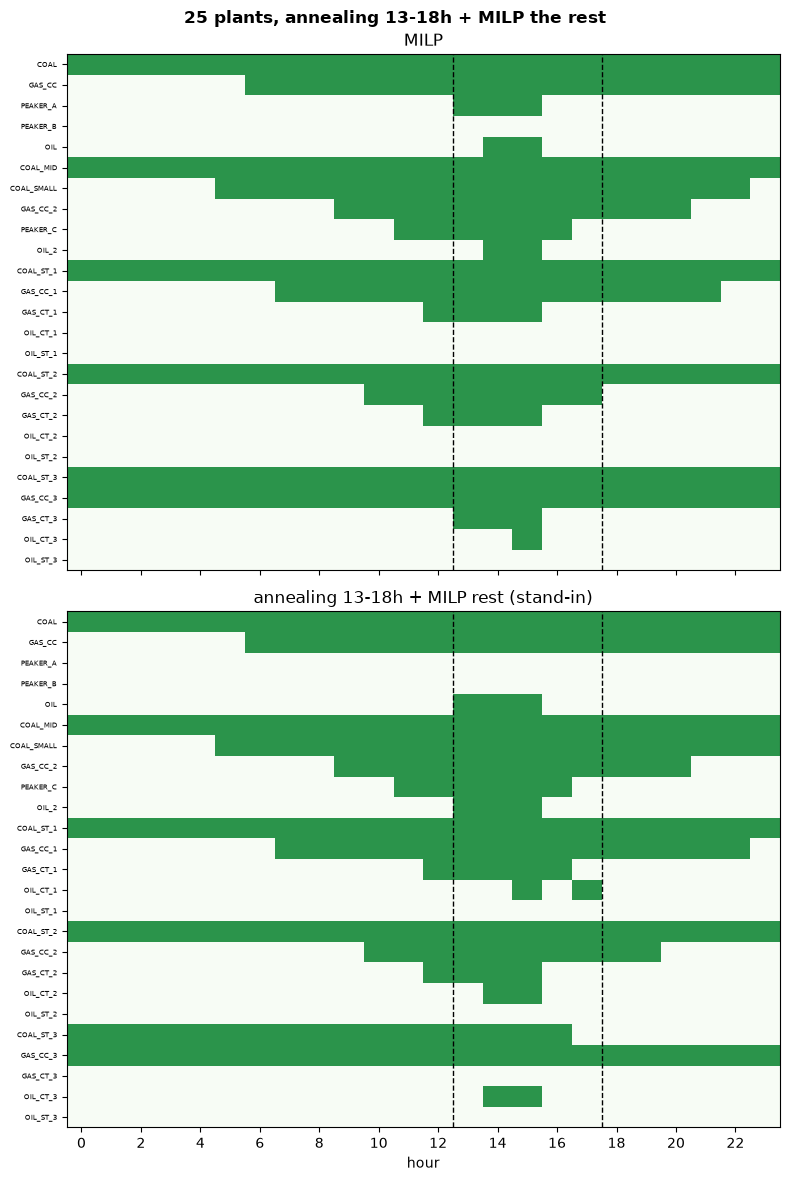


50 plants: 56 qubits in the 13-18h window (50 plant + 6 slack), 1,540 RZZ per layer -> hardware only
  MILP $2,801,196 in 0.41 s; cheapest-first gap +0.93% with 3 rule(s) broken
  QAOA: not simulated (56 qubits > 20); needs hardware only
  annealing 13-18h + MILP rest (stand-in): gap +6.74%, valid=True, 0 rule(s) broken, hour-best picks 0/5, 1.9 s (1.1 s sampling)
  random 13-18h + MILP rest: gap +19.41%, valid=False, 64 rule(s) broken, hour-best picks 0/5, 0.7 s (0.0 s sampling)

50 plants, annealing 13-18h + MILP the rest
method                          daily cost $       gap  rules broken
MILP (optimal)                     2,801,196    +0.00%             0
cheapest-first rule                2,827,229    +0.93%             3
annealing 13-18h + MILP rest (stand-in)     2,990,052    +6.74%             0
random 13-18h + MILP rest          3,344,966   +19.41%            64


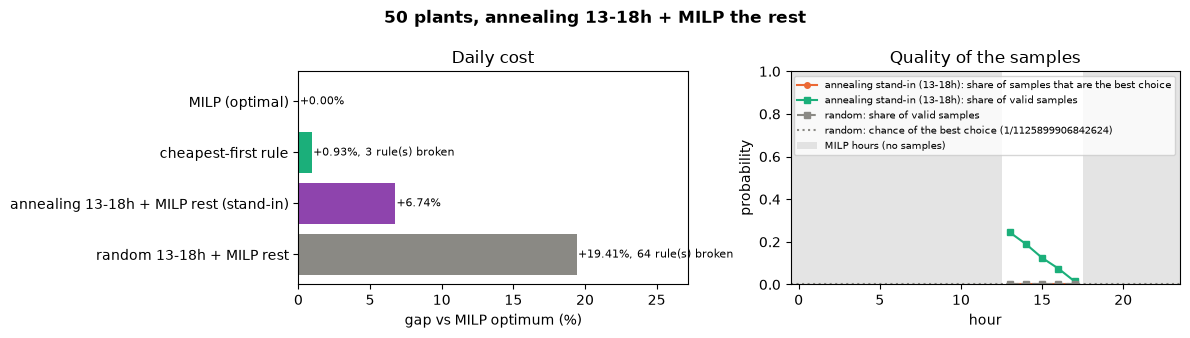

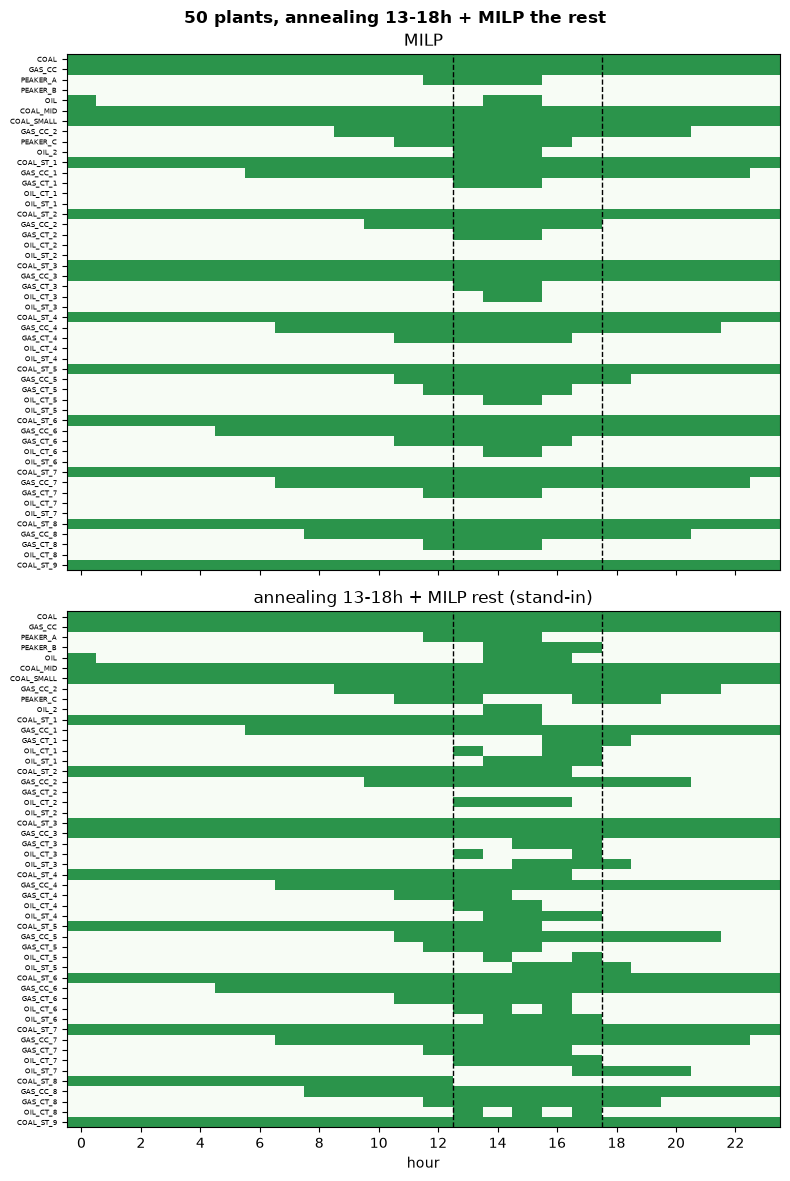


plants  qubits  RZZ/layer  MILP s       QAOA gap  anneal gap  random gap  QAOA s/hour  where QAOA runs
    10      13         78    0.06         +0.42%      +0.01%      +2.98%          0.1  this machine, exact
    15      19        171    0.16         +1.26%      +0.49%    +21.35%*          7.0  this machine, exact
    25      30        435    0.20  not simulable      +0.81%    +14.71%*            -  qBraid GPU simulator
    50      56      1,540    0.41  not simulable      +6.74%    +19.41%*            -  hardware only
* = a rule was broken (gap of an invalid day). Stand-in rows test the pipeline, not quantum speed.


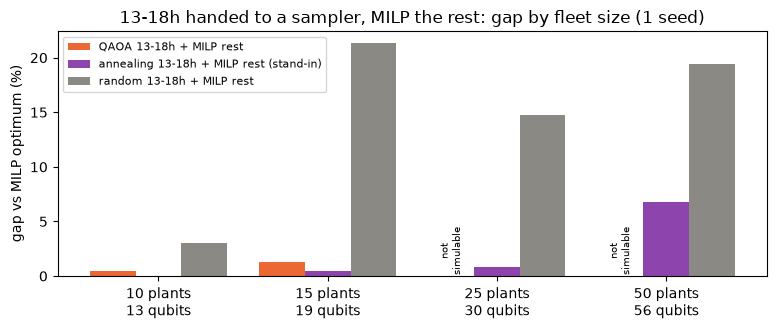

In [ ]:
# ==================== Hypothetical scaling run: 15, 25 and 50 plants, QAOA 13:00 to 18:00 ====================
# WHY "HYPOTHETICAL". The QAOA in this notebook is an exact statevector simulation, and it scores every
# bitstring to tune its angles. Both grow as 2^qubits. With QAOA only in the 13-18h window the slack stays
# small (4, 5, 6 bits), but 15 plants is still 19 qubits, 25 plants is 30 and 50 plants is 56. Only the
# first fits on this machine. So this cell:
#   1. builds real fleets of 15, 25 and 50 RTS-GMLC units with the data folder's own recipe (make_fleets.py),
#   2. works out the slack bits each fleet needs for the window, and the qubits / gates / memory that follow,
#   3. runs the SAME hybrid pipeline (13-18h handed to a sampler, MILP for the rest, all plants in the QUBO)
#      with: real QAOA where it fits (15 plants, with a fast exact simulator checked against Qiskit), and two
#      stand-ins everywhere: simulated annealing on the very same QUBO (what a QAOA sampler has to beat) and
#      random guesses (the honesty check).
# The stand-ins test the pipeline (QUBO, slack, locks, classical filter, MILP) at scale; they say nothing
# about quantum speed. A real QAOA number at 25 or 50 plants needs a GPU simulator (up to 35 qubits) or
# hardware, so those rows are labelled as what they are.
import math
import sys
from check import DATA

FLEET_SIZES = (10, 15, 25, 50)
SCALE_QAOA_HOURS = list(range(13, 18))     # the window the sweep above picked: 13:00 to 18:00
QAOA_MAX_QUBITS = 20                       # exact statevector + bitstring table, on this machine
GPU_SIM_MAX_QUBITS = 35                    # qBraid's GPU statevector simulator (qbraid:qbraid:sim:gpu-sv)
SCALE_SHOTS, SCALE_SEED = 200, 7
SCALE_QAOA_MAXITER = 60                    # COBYLA steps per QAOA hour, as in run_qaoa

# ==================== Fleets: real RTS-GMLC units, the data folder's recipe ====================
if not all((DATA / f"plants{n}.csv").exists() and (DATA / f"demand{n}.csv").exists() for n in FLEET_SIZES):
    sys.path.insert(0, str(DATA))
    import make_fleets
    make_fleets.main()
BIG_FLEETS = {n: (load_plants(DATA / f"plants{n}.csv"), *load_demand(DATA / f"demand{n}.csv")) for n in FLEET_SIZES}
print(f"{'plants':>6}{'capacity MW':>13}{'peak MW':>9}{'coal':>6}{'gas CC':>8}{'gas CT':>8}{'oil':>6}{'on at 0h':>10}")
for n, (fleet, load, margin) in BIG_FLEETS.items():
    kinds = [p["type"] for p in fleet]
    print(f"{n:>6}{sum(p['pmax_mw'] for p in fleet):>13,.0f}{load.max():>9,.0f}"
          f"{sum('coal' in k for k in kinds):>6}{sum('combined' in k for k in kinds):>8}"
          f"{sum('gas combustion' in k for k in kinds):>8}{sum('oil' in k for k in kinds):>6}"
          f"{sum(int(p['on_at_start']) for p in fleet):>10}")

# ==================== Slack bits: how many, and why the window keeps them small ====================
# The slack qubits spell out the spare capacity (capacity minus demand + reserve) in 50 MW blocks, so they
# must reach the LARGEST spare in any hour QAOA handles: bits = ceil(log2(max spare + 1)). Three choices:
#   (a) fixed 3 bits (the notebook): covers 0..7 blocks; wrong for every hour with more spare.
#   (b) per-window bits (used here): size the slack for the hours QAOA actually gets. Handing over only the
#       peak (13-18h) is what keeps it at 4-6 bits; a whole day would need 5-7 bits.
#   (c) per-hour bits: rebuild the QUBO with that hour's own spare, so quiet hours cost no more qubits
#       than busy ones. Same count at the peak, fewer at night. Easy to add: n_slack per hour.
# Beyond that: count in bigger blocks (100 MW halves the bits but needs pmax rounded to 100 MW), or the
# penalty-only QUBO from the stretch goals, which drops the slack qubits altogether.
def slack_bits_for(fleet, load, margin, hour_list):
    cap_blocks = sum(p["pmax_mw"] for p in fleet) / BLOCK_MW
    spare = {int(t): int(cap_blocks - math.ceil((load[t] + margin[t]) / BLOCK_MW)) for t in hour_list}
    return math.ceil(math.log2(max(spare.values()) + 1)), spare


print(f"\n{'plants':>6}{'spare 13-18h':>14}{'bits 13-18h':>13}{'spare all day':>15}{'bits all day':>14}"
      f"{'hours 3 bits miss':>19}{'qubits 13-18h':>15}")
SCALE_PLAN = {}
for n, (fleet, load, margin) in BIG_FLEETS.items():
    bits_win, spare_win = slack_bits_for(fleet, load, margin, SCALE_QAOA_HOURS)
    bits_day, spare_day = slack_bits_for(fleet, load, margin, range(len(load)))
    n_qubits = n + bits_win
    SCALE_PLAN[n] = dict(slack_bits=bits_win, qubits=n_qubits, rzz_per_layer=n_qubits * (n_qubits - 1) // 2,
                         amplitudes=2 ** n_qubits, statevector_gb=2 ** n_qubits * 16 / 1e9,
                         where=("this machine, exact" if n_qubits <= QAOA_MAX_QUBITS else
                                "qBraid GPU simulator" if n_qubits <= GPU_SIM_MAX_QUBITS else "hardware only"))
    print(f"{n:>6}{f'{min(spare_win.values())}..{max(spare_win.values())}':>14}{bits_win:>13}"
          f"{f'{min(spare_day.values())}..{max(spare_day.values())}':>15}{bits_day:>14}"
          f"{sum(s > 2 ** 3 - 1 for s in spare_day.values()):>16}/24{n_qubits:>15}")

# ==================== Resource estimate: what a QAOA hour costs at each size ====================
# Every pair of qubits is coupled by the capacity penalty, so one QAOA layer has n(n-1)/2 RZZ gates.
# The statevector holds 2^n complex amplitudes (16 bytes each); the angle tuning also scores all 2^n bitstrings.
print(f"\n{'plants':>6}{'qubits':>8}{'RZZ / layer':>13}{'bitstrings':>14}{'statevector':>13}  where a QAOA hour can run")
for n, plan in SCALE_PLAN.items():
    gb = plan["statevector_gb"]
    mem = f"{gb * 1e3:.0f} MB" if gb < 1 else (f"{gb:.0f} GB" if gb < 1e3 else f"{gb / 1e3:,.0f} TB" if gb < 1e6 else f"{gb / 1e6:,.0f} PB")
    print(f"{n:>6}{plan['qubits']:>8}{plan['rzz_per_layer']:>13,}{plan['amplitudes']:>14,.3g}{mem:>13}  {plan['where']}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
sizes = list(SCALE_PLAN)
axes[0].bar([str(n) for n in sizes], [SCALE_PLAN[n]["qubits"] for n in sizes], color=COLORS["qaoa"], label="qubits (plants + slack)")
axes[0].axhline(QAOA_MAX_QUBITS, color="gray", ls="--", lw=1, label=f"exact simulation here ({QAOA_MAX_QUBITS})")
axes[0].axhline(GPU_SIM_MAX_QUBITS, color="gray", ls=":", lw=1, label=f"GPU simulator ({GPU_SIM_MAX_QUBITS})")
axes[0].set(xlabel="plants", ylabel="qubits", title="Qubits for one 13-18h hour")
axes[0].legend(fontsize=8)
axes[1].semilogy([str(n) for n in sizes], [SCALE_PLAN[n]["rzz_per_layer"] for n in sizes], "o-", color=COLORS["milp"], label="two-qubit (RZZ) gates per layer")
axes[1].semilogy([str(n) for n in sizes], [SCALE_PLAN[n]["amplitudes"] for n in sizes], "s-", color=COLORS["random"], label="bitstrings / amplitudes")
axes[1].set(xlabel="plants", title="Circuit size and simulation size (log scale)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# ==================== A fast exact QAOA simulator (same answer as Qiskit, ~100x faster) ====================
# Qiskit's Statevector applies the 171 RZZ gates of a 19 qubit circuit one by one (about 8 minutes per QAOA
# hour). But QAOA's cost layer is DIAGONAL (a phase exp(-i*gamma*E/scale) on each bitstring, and we already
# have every bitstring's energy E) and the mixer is RX(2*beta) on every qubit (a product of 2x2 rotations).
# So the state can be built with p * (n + 1) numpy passes over the 2^n amplitudes. Checked against Qiskit below.
def qaoa_probs_diagonal(energies, scale, angles, p=1):
    n_q = int(round(np.log2(len(energies))))
    psi = np.full(len(energies), 1 / np.sqrt(len(energies)), dtype=complex)        # H on every qubit
    for gamma, beta in zip(angles[:p], angles[p:]):
        psi = psi * np.exp(-1j * gamma * energies / scale)                           # cost layer (rz + rzz)
        psi = psi.reshape([2] * n_q)
        c, s = np.cos(beta), -1j * np.sin(beta)                                      # RX(2 beta) on each qubit
        for axis in range(n_q):
            a0, a1 = np.take(psi, 0, axis=axis), np.take(psi, 1, axis=axis)
            psi = np.stack([c * a0 + s * a1, s * a0 + c * a1], axis=axis)
        psi = psi.ravel()
    return np.abs(psi) ** 2


QAOA_BETA_MAX = 1.5        # top of the beta grid; 1.5 is the notebook's run_qaoa. Later cells widen it to 3.0.


def run_qaoa_fast(Q, offset, p=1, start=None, maxiter=60):
    # run_qaoa with the diagonal simulator in place of Qiskit's Statevector. Same grid, same COBYLA.
    energies = all_energies(Q, offset)
    h, J = qubo_to_ising(Q)
    scale = max(np.abs(h).max(), max(abs(v) for v in J.values()))
    E = (energies - energies.min()) / (energies.max() - energies.min())

    def probs_at(angles):
        return qaoa_probs_diagonal(energies, scale, np.asarray(angles, float), p)

    def average_energy(angles):
        return probs_at(angles) @ E

    if start is None or len(start) != 2 * p:
        grid = [(g, b) for g in np.linspace(0.1, 3.0, 15) for b in np.linspace(0.1, QAOA_BETA_MAX, 8 if QAOA_BETA_MAX <= 1.5 else 16)]
        g, b = min(grid, key=lambda gb: average_energy([gb[0]] * p + [gb[1]] * p))
        start = [g] * p + [b] * p
    result = minimize(average_energy, start, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.2})
    return result.x, probs_at(result.x)


# Check: the same angles give the same probabilities as Qiskit's Statevector (10 plants, hour 13 QUBO).
with fleet_globals(*BIG_FLEETS[10], n_slack=3):
    _milp_sched = solve_milp(plants, demand, reserve)[1]
    _Q, _off = build_qubo(plants, demand[13], reserve[13], _milp_sched[12])
    _angles = [0.8, 0.4]
    _qc, _params = qaoa_circuit(_Q, p=1)
    _t0 = time.perf_counter()
    _p_qiskit = Statevector(_qc.assign_parameters(dict(zip(_params, _angles)))).probabilities()
    _t1 = time.perf_counter()
    _h, _J = qubo_to_ising(_Q)
    _p_fast = qaoa_probs_diagonal(all_energies(_Q, _off), max(np.abs(_h).max(), max(abs(v) for v in _J.values())), _angles)
    _t2 = time.perf_counter()
    print(f"\nFast QAOA simulator vs Qiskit Statevector ({N_QUBITS} qubits): max |difference| = "
          f"{np.abs(_p_qiskit - _p_fast).max():.1e}; Qiskit {_t1 - _t0:.3f} s, numpy {_t2 - _t1:.3f} s per evaluation")
    assert np.allclose(_p_qiskit, _p_fast, atol=1e-9), "the fast simulator disagrees with Qiskit"

# ==================== Pieces that do not enumerate 2^qubits ====================
def best_hour_choice(plants, demand_mw, reserve_mw, was_on, must_on=(), must_off=()):
    # Exact cheapest on/off choice for ONE hour, by a tiny MILP instead of trying all 2^N choices
    # (check_hour does that, which is fine for 10 plants and impossible for 50). Returns (choice, cost).
    n = len(plants)
    c = np.r_[[p["no_load_cost_per_h"] + p["startup_cost"] * (1 - int(was_on[i])) for i, p in enumerate(plants)],
              [p["marginal_cost_per_mwh"] for p in plants]]
    rows, lo, hi = [], [], []
    rows.append([(n + i, 1) for i in range(n)]); lo.append(demand_mw); hi.append(demand_mw)
    rows.append([(i, p["pmax_mw"]) for i, p in enumerate(plants)]); lo.append(demand_mw + reserve_mw); hi.append(np.inf)
    for i, p in enumerate(plants):
        rows.append([(n + i, 1), (i, -p["pmin_mw"])]); lo.append(0); hi.append(np.inf)
        rows.append([(n + i, 1), (i, -p["pmax_mw"])]); lo.append(-np.inf); hi.append(0)
    A = lil_matrix((len(rows), 2 * n))
    for k, terms in enumerate(rows):
        for j, a in terms:
            A[k, j] += a
    lower, upper = np.zeros(2 * n), np.r_[np.ones(n), [p["pmax_mw"] for p in plants]]
    lower[list(must_on)] = 1
    upper[list(must_off)] = 0
    res = scipy_milp(c, constraints=LinearConstraint(A.tocsr(), lo, hi), integrality=np.r_[np.ones(n), np.zeros(n)],
                     bounds=Bounds(lower, upper))
    if res.x is None:
        return None, np.inf
    return [int(round(x)) for x in res.x[:n]], float(res.fun)


def anneal_samples(Q, shots, rng, sweeps=150):
    # Simulated annealing on the QUBO, `shots` chains in parallel: a classical stand-in for the sampler.
    # Returns shots x qubits bits. It sees exactly what QAOA sees (Q), nothing else.
    nq = len(Q)
    Qs = np.triu(Q, 1)
    Qs = Qs + Qs.T
    diag = np.diag(Q).copy()
    y = rng.integers(0, 2, (shots, nq)).astype(float)
    scale = float(np.abs(Q).max())
    for T in np.geomspace(scale, scale * 1e-4, sweeps):
        for j in rng.permutation(nq):
            dE = (1 - 2 * y[:, j]) * (diag[j] + y @ Qs[:, j])
            accept = (dE < 0) | (rng.random(shots) < np.exp(-np.clip(dE, 0, None) / T))
            y[accept, j] = 1 - y[accept, j]
    return y.astype(int)


def schedule_day_hybrid_big(sampler_hours, sampler, shots=200, seed=7, start_angles=None, milp_horizon="day"):
    """schedule_day_hybrid for any fleet size. Samples are bit arrays, never indices into a 2^qubits table.

    sampler: "qaoa" (needs the bitstring tables: fleet_globals(..., tables=True), qubits <= QAOA_MAX_QUBITS),
             "anneal" (simulated annealing on the same QUBO), "random", or a function
             f(Q, offset, shots, rng, hour) -> shots x qubits bit array (an external simulator, say).
    """
    sampler_hours = {int(t) for t in sampler_hours}
    sampler_name = sampler if isinstance(sampler, str) else getattr(sampler, "__name__", "custom")
    rng = np.random.default_rng(seed)
    history, log, angles = [], [], start_angles
    was_on = [int(x["on_at_start"]) for x in plants]
    T, t = len(hours), 0
    while t < T:
        if t in sampler_hours:
            must_on, must_off = locks(plants, history)
            Q, offset = build_qubo(plants, demand[t], reserve[t], was_on)
            Q, offset = add_locks(Q, offset, must_on, must_off, weight=2 * plant_hour_costs(plants, was_on).max())
            assert N == len(plants) and Q.shape == (N + N_SLACK, N + N_SLACK), "the sampler must decide all plants"
            started = time.perf_counter()
            if sampler == "qaoa":
                if N_QUBITS > QAOA_MAX_QUBITS or INDEX_BITS is None:
                    raise ValueError(f"{N_QUBITS} qubits: exact QAOA simulation is not possible here")
                angles, probs = run_qaoa_fast(Q, offset, p=1, start=angles, maxiter=SCALE_QAOA_MAXITER)
                bits = INDEX_BITS[rng.choice(2 ** N_QUBITS, size=shots, p=probs / probs.sum())]
            elif sampler == "anneal":
                bits = anneal_samples(Q, shots, rng)
            elif callable(sampler):
                bits = np.asarray(sampler(Q, offset, shots, rng, t), dtype=int)
                assert bits.shape == (shots, N_QUBITS)
            else:
                bits = rng.integers(0, 2, (shots, N_QUBITS))
            sample_seconds = time.perf_counter() - started
            seen = [list(map(int, c)) for c in np.unique(bits[:, :N], axis=0)]
            ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c, must_on, must_off)]
            if not ok:
                ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c)]
            if ok:
                pick = min(ok, key=lambda c: hour_cost(plants, demand[t], c, was_on))
            else:
                values, counts = np.unique(bits[:, :N], axis=0, return_counts=True)
                pick = list(map(int, values[counts.argmax()]))
            best, best_cost = best_hour_choice(plants, demand[t], reserve[t], was_on, must_on, must_off)
            matches = (best is not None and hour_ok(plants, demand[t], reserve[t], pick, must_on, must_off)
                       and np.isclose(hour_cost(plants, demand[t], pick, was_on), best_cost))
            valid_share = float(np.mean([hour_ok(plants, demand[t], reserve[t], row, must_on, must_off) for row in bits[:, :N]]))
            p_best = 0.0 if best is None else float(np.mean(np.all(bits[:, :N] == np.array(best), axis=1)))
            log.append(dict(hour=t, method=sampler_name, pick=pick, matches_best=bool(matches), plants_decided=N,
                            qubits=N + N_SLACK, valid_share=valid_share, p_best=p_best, angles=angles,
                            sample_seconds=sample_seconds, milp_seconds=0.0))
            history.append(pick)
            was_on = pick
            t += 1
        else:
            stop = t
            while stop < T and stop not in sampler_hours:
                stop += 1
            end = T if milp_horizon == "day" else stop
            hold_on, hold_off = remaining_locks(plants, history)
            try:
                _, window, secs = solve_milp_window(plants, demand[t:end], reserve[t:end], was_on, hold_on, hold_off)
            except RuntimeError:
                _, window, secs = solve_milp_window(plants, demand[t:end], reserve[t:end], was_on,
                                                    np.zeros(N, int), np.zeros(N, int))
                print(f"  hour {t}: the MILP had to break a min up/down lock", flush=True)
            for k in range(t, stop):
                pick = [int(x) for x in window[k - t]]
                log.append(dict(hour=k, method="milp", pick=pick, matches_best=None, valid_share=np.nan,
                                p_best=np.nan, angles=None, sample_seconds=0.0, milp_seconds=secs if k == t else 0.0))
                history.append(pick)
                was_on = pick
            t = stop
    return np.array(history), log


def transfer_angles():
    # Warm start for the 15 plant QAOA: angles tuned on the 10 plant fleet in the hour 13 QUBO (angle transfer).
    run = globals().get("hybrid_best_hours")
    if run:
        row = next((r for r in run["runs"]["qaoa"]["log"] if r["method"] == "qaoa"), None)
        if row is not None:
            return row["angles"]
    run = globals().get("ten_qaoa")
    return None if run is None else run["log"][SCALE_QAOA_HOURS[0]]["angles"]


# ==================== The hypothetical run, fleet by fleet ====================
SAMPLER_NAMES = {"qaoa": "QAOA 13-18h + MILP rest", "anneal": "annealing 13-18h + MILP rest (stand-in)",
                 "random": "random 13-18h + MILP rest"}
SAMPLER_COLORS = {"qaoa": COLORS["qaoa"], "anneal": "#8e44ad", "random": COLORS["random"]}


def run_scaling_fleet(n, seed=SCALE_SEED, shots=SCALE_SHOTS):
    fleet, load, margin = BIG_FLEETS[n]
    plan = SCALE_PLAN[n]
    print(f"\n{n} plants: {plan['qubits']} qubits in the 13-18h window ({n} plant + {plan['slack_bits']} slack), "
          f"{plan['rzz_per_layer']:,} RZZ per layer -> {plan['where']}", flush=True)
    milp_cost, milp_schedule, _, milp_secs = solve_milp(fleet, load, margin)
    milp_result = check_schedule(fleet, load, margin, milp_schedule, milp_cost=milp_cost, verbose=False)
    rule_result = check_schedule(fleet, load, margin, cheapest_first(fleet, load, margin), milp_cost=milp_cost, verbose=False)
    print(f"  MILP ${milp_cost:,.0f} in {milp_secs:.2f} s; cheapest-first gap {rule_result['gap_pct']:+.2f}% "
          f"with {len(rule_result['violations'])} rule(s) broken", flush=True)
    runs = {}
    with fleet_globals(fleet, load, margin, n_slack=plan["slack_bits"], tables=plan["qubits"] <= QAOA_MAX_QUBITS):
        for sampler in ("qaoa", "anneal", "random"):
            if sampler == "qaoa" and plan["qubits"] > QAOA_MAX_QUBITS:
                print(f"  QAOA: not simulated ({plan['qubits']} qubits > {QAOA_MAX_QUBITS}); needs {plan['where']}", flush=True)
                continue
            started = time.perf_counter()
            schedule, log = schedule_day_hybrid_big(SCALE_QAOA_HOURS, sampler, shots=shots, seed=seed,
                                                    start_angles=transfer_angles() if sampler == "qaoa" else None)
            elapsed = time.perf_counter() - started
            result = check_schedule(fleet, load, margin, schedule, milp_cost=milp_cost, verbose=False)
            assert schedule.shape == (len(load), n) and all(r.get("plants_decided", n) == n for r in log)
            sample_secs = sum(r["sample_seconds"] for r in log)
            hits = sum(bool(r["matches_best"]) for r in log if r["method"] == sampler)
            runs[sampler] = dict(schedule=schedule, log=log, result=result, runtime_s=elapsed, sample_s=sample_secs)
            print(f"  {SAMPLER_NAMES[sampler]}: gap {result['gap_pct']:+.2f}%, valid={result['valid']}, "
                  f"{len(result['violations'])} rule(s) broken, hour-best picks {hits}/{len(SCALE_QAOA_HOURS)}, "
                  f"{elapsed:.1f} s ({sample_secs:.1f} s sampling)", flush=True)
    results = {"MILP (optimal)": (milp_result, COLORS["milp"]), "cheapest-first rule": (rule_result, COLORS["rule"])}
    for sampler, run in runs.items():
        results[SAMPLER_NAMES[sampler]] = (run["result"], SAMPLER_COLORS[sampler])
    shown = "qaoa" if "qaoa" in runs else "anneal"
    report_fleet_day(f"{n} plants, {shown if shown == 'QAOA' else SAMPLER_NAMES[shown].split(' + ')[0]} + MILP the rest"
                     if shown != "qaoa" else f"{n} plants, QAOA 13-18h + MILP the rest",
                     results, runs[shown]["log"], runs["random"]["log"], milp_schedule, runs[shown]["schedule"],
                     SAMPLER_NAMES[shown], [p["plant_id"] for p in fleet],
                     sampler_name="QAOA (13-18h)" if shown == "qaoa" else "annealing stand-in (13-18h)",
                     p_best_label="share of samples that are the best choice",
                     milp_hours=[t for t in range(len(load)) if t not in SCALE_QAOA_HOURS])
    return dict(plants=n, plan=plan, milp_cost=milp_cost, milp_seconds=milp_secs, milp_schedule=milp_schedule,
                milp_result=milp_result, rule_result=rule_result, runs=runs)


scaling_results = {n: run_scaling_fleet(n) for n in FLEET_SIZES}

# ==================== Scaling summary ====================
print(f"\n{'plants':>6}{'qubits':>8}{'RZZ/layer':>11}{'MILP s':>8}{'QAOA gap':>15}{'anneal gap':>12}{'random gap':>12}{'QAOA s/hour':>13}  where QAOA runs")
for n, res in scaling_results.items():
    gaps = {s: (f"{r['result']['gap_pct']:+.2f}%" + ("" if r["result"]["valid"] else "*")) for s, r in res["runs"].items()}
    qs = f"{res['runs']['qaoa']['sample_s'] / len(SCALE_QAOA_HOURS):.1f}" if "qaoa" in res["runs"] else "-"
    print(f"{n:>6}{res['plan']['qubits']:>8}{res['plan']['rzz_per_layer']:>11,}{res['milp_seconds']:>8.2f}"
          f"{gaps.get('qaoa', 'not simulable'):>15}{gaps['anneal']:>12}{gaps['random']:>12}{qs:>13}  {res['plan']['where']}")
print("* = a rule was broken (gap of an invalid day). Stand-in rows test the pipeline, not quantum speed.")

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(FLEET_SIZES))
for k, sampler in enumerate(("qaoa", "anneal", "random")):
    gaps = [scaling_results[n]["runs"][sampler]["result"]["gap_pct"] if sampler in scaling_results[n]["runs"] else np.nan
            for n in FLEET_SIZES]
    ax.bar(x + (k - 1) * 0.27, gaps, 0.27, color=SAMPLER_COLORS[sampler], label=SAMPLER_NAMES[sampler])
    for xi, g in zip(x, gaps):
        if np.isnan(g):
            ax.text(xi + (k - 1) * 0.27, 0.1, "not\nsimulable", ha="center", va="bottom", fontsize=7, rotation=90)
ax.set_xticks(x, [f"{n} plants\n{SCALE_PLAN[n]['qubits']} qubits" for n in FLEET_SIZES])
ax.set(ylabel="gap vs MILP optimum (%)", title="13-18h handed to a sampler, MILP the rest: gap by fleet size (1 seed)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
# ================== End of the hypothetical scaling run ==================


### Supporting study — hourly windows and larger-fleet simulation

Separate simulator/scaling exploration; not the reduced-qubit hybrid implementation.


Aer MPS vs the exact state (15 plants, 18-19 qubits), and convergence in bond dimension where no exact state exists
  hour 14, 18 qubits: bond 8: overlap 0.9999, bond 32: overlap 1.0000, bond 128: overlap 1.0000   (overlap of the two probability distributions; 1 = identical)
  hour 17, 19 qubits: bond 8: overlap 0.9993, bond 32: overlap 1.0000, bond 128: overlap 1.0000   (overlap of the two probability distributions; 1 = identical)
  50 plants, hour 14, 54 qubits, 400 shots: bond 8: <E> 3,804,866, valid 1%, 1 s | bond 32: <E> 3,797,055, valid 1%, 1 s | bond 128: <E> 3,797,055, valid 1%, 1 s
  100 plants, hour 14, 105 qubits, 400 shots: bond 8: <E> 17,823,615, valid 0%, 2 s | bond 32: <E> 17,823,615, valid 0%, 3 s | bond 128: <E> 17,823,615, valid 0%, 3 s

10 plants: MILP $602,139 in 0.07 s. One sampled hour per run, hours 13-17, 3 seeds.
  hour 13 ( 12 qubits, 2 slack) qaoa   : gap  +0.01% (seeds +0.01, +0.01, +0.01), hour-best 3/3, valid samples  29%, valid days 3/3,   0.3 s/run
  hou

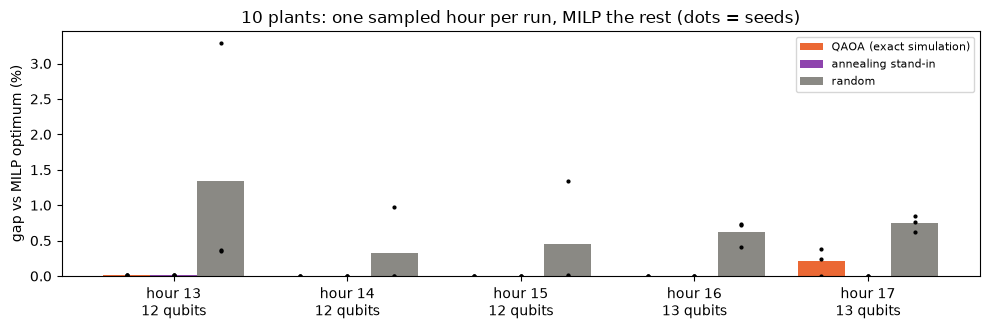


10 plants, hour 14 sampled, MILP the rest (seed 7)
method                          daily cost $       gap  rules broken
MILP (optimal)                       602,139    +0.00%             0
cheapest-first rule                  631,461    +4.87%             3
QAOA (exact simulation) hour 14 + MILP rest       602,139    +0.00%             0
annealing hour 14 + MILP rest        602,139    +0.00%             0
random hour 14 + MILP rest           608,049    +0.98%             0


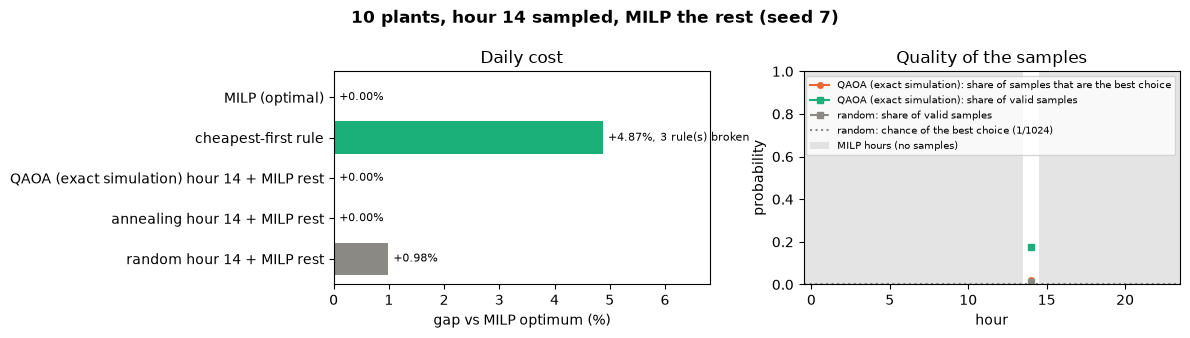

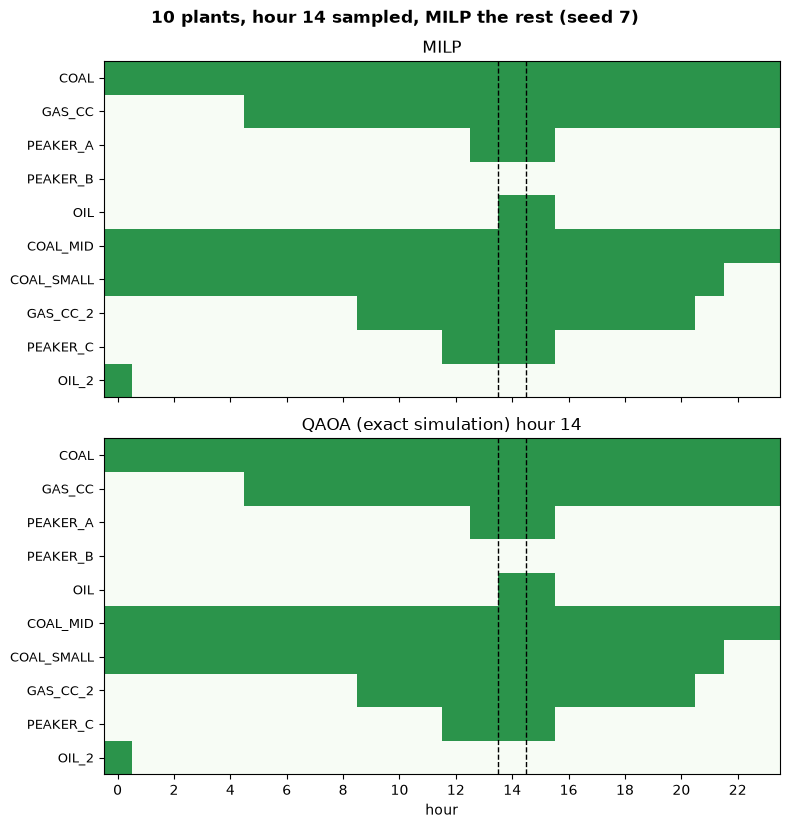


15 plants: MILP $915,570 in 0.16 s. One sampled hour per run, hours 13-17, 3 seeds.
  hour 13 ( 18 qubits, 3 slack) qaoa   : gap  +0.20% (seeds +0.08, +0.35, +0.18), hour-best 1/3, valid samples  34%, valid days 3/3,  55.2 s/run
  hour 13 ( 18 qubits, 3 slack) anneal : gap  +0.08% (seeds +0.08, +0.08, +0.08), hour-best 3/3, valid samples 100%, valid days 3/3,   0.5 s/run
  hour 13 ( 18 qubits, 3 slack) random : gap  +1.67% (seeds +2.31, +2.26, +0.46), hour-best 0/3, valid samples   0%, valid days 2/3,   0.4 s/run
  hour 14 ( 18 qubits, 3 slack) qaoa   : gap  +0.09% (seeds +0.00, +0.00, +0.28), hour-best 2/3, valid samples  14%, valid days 3/3,  58.3 s/run
  hour 14 ( 18 qubits, 3 slack) anneal : gap  +0.00% (seeds +0.00, +0.00, +0.00), hour-best 3/3, valid samples 100%, valid days 3/3,   1.1 s/run
  hour 14 ( 18 qubits, 3 slack) random : gap  +2.50% (seeds +2.10, +2.29, +3.12), hour-best 0/3, valid samples   0%, valid days 1/3,   0.7 s/run
  hour 15 ( 18 qubits, 3 slack) qaoa   : gap 

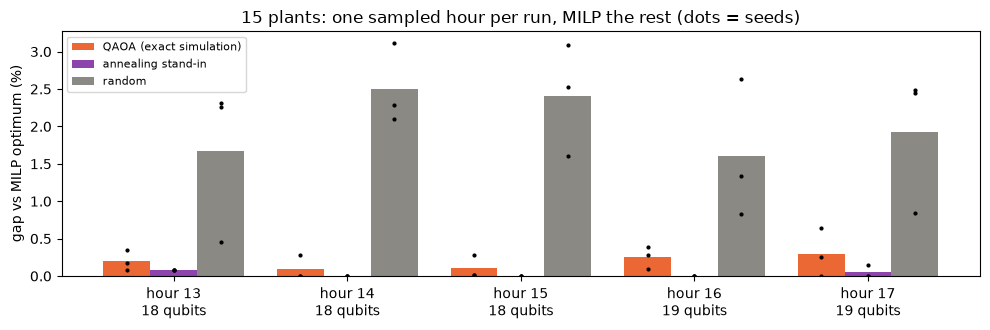


15 plants, hour 14 sampled, MILP the rest (seed 7)
method                          daily cost $       gap  rules broken
MILP (optimal)                       915,570    +0.00%             0
cheapest-first rule                  944,700    +3.18%             3
QAOA (exact simulation) hour 14 + MILP rest       915,570    +0.00%             0
annealing hour 14 + MILP rest        915,570    +0.00%             0
random hour 14 + MILP rest           934,775    +2.10%             1


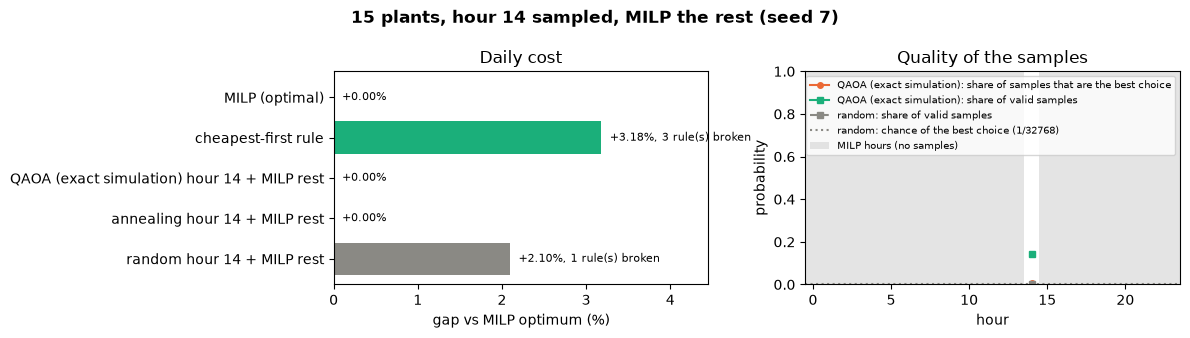

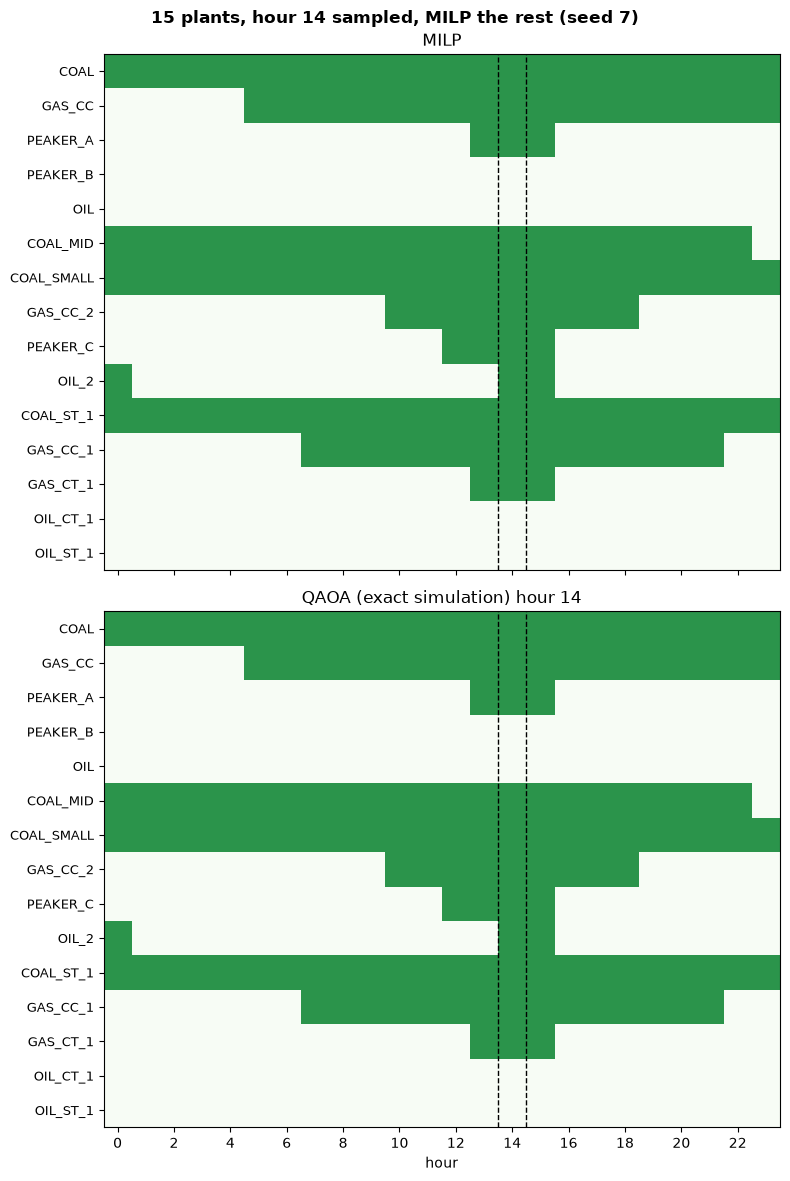


25 plants: MILP $1,462,400 in 0.22 s. One sampled hour per run, hours 13-17, 3 seeds.
  hour 13 ( 29 qubits, 4 slack) mps    : gap  +1.73% (seeds +0.98, +1.23, +2.97), hour-best 0/3, valid samples  15%, valid days 3/3,   2.2 s/run
  hour 13 ( 29 qubits, 4 slack) anneal : gap  +0.09% (seeds +0.10, +0.09, +0.09), hour-best 2/3, valid samples  96%, valid days 3/3,   0.5 s/run
  hour 14: the MILP had to break a min up/down lock
  hour 14: the MILP had to break a min up/down lock
  hour 13 ( 29 qubits, 4 slack) random : gap  +6.67% (seeds +10.88, +3.52, +5.61), hour-best 0/3, valid samples   0%, valid days 0/3,   0.4 s/run
  hour 14 ( 28 qubits, 3 slack) mps    : gap  +0.64% (seeds +1.04, +0.56, +0.34), hour-best 0/3, valid samples  11%, valid days 3/3,   2.2 s/run
  hour 14 ( 28 qubits, 3 slack) anneal : gap  +0.00% (seeds +0.00, +0.01, +0.00), hour-best 2/3, valid samples  99%, valid days 3/3,   0.4 s/run
  hour 15: the MILP had to break a min up/down lock
  hour 15: the MILP had to brea

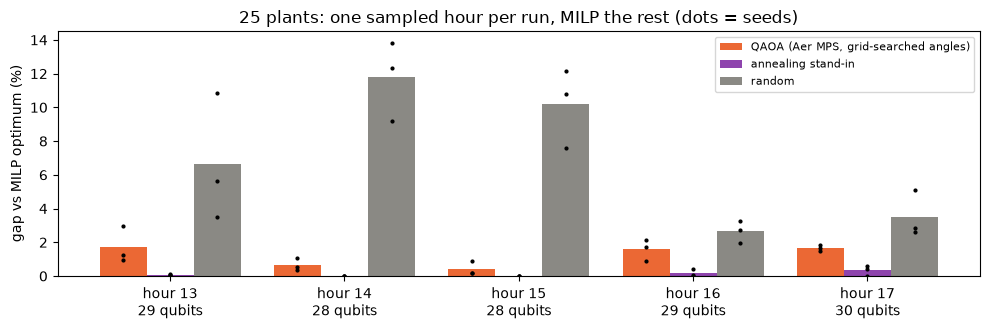


25 plants, hour 14 sampled, MILP the rest (seed 7)
method                          daily cost $       gap  rules broken
MILP (optimal)                     1,462,400    +0.00%             0
cheapest-first rule                1,467,030    +0.32%             1
QAOA (Aer MPS, grid-searched angles) hour 14 + MILP rest     1,477,618    +1.04%             0
annealing hour 14 + MILP rest      1,462,400    +0.00%             0
random hour 14 + MILP rest         1,642,496   +12.32%            17


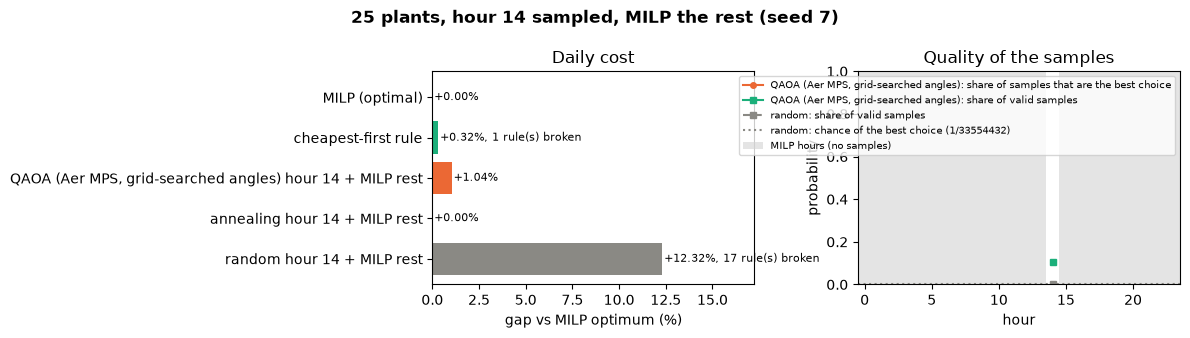

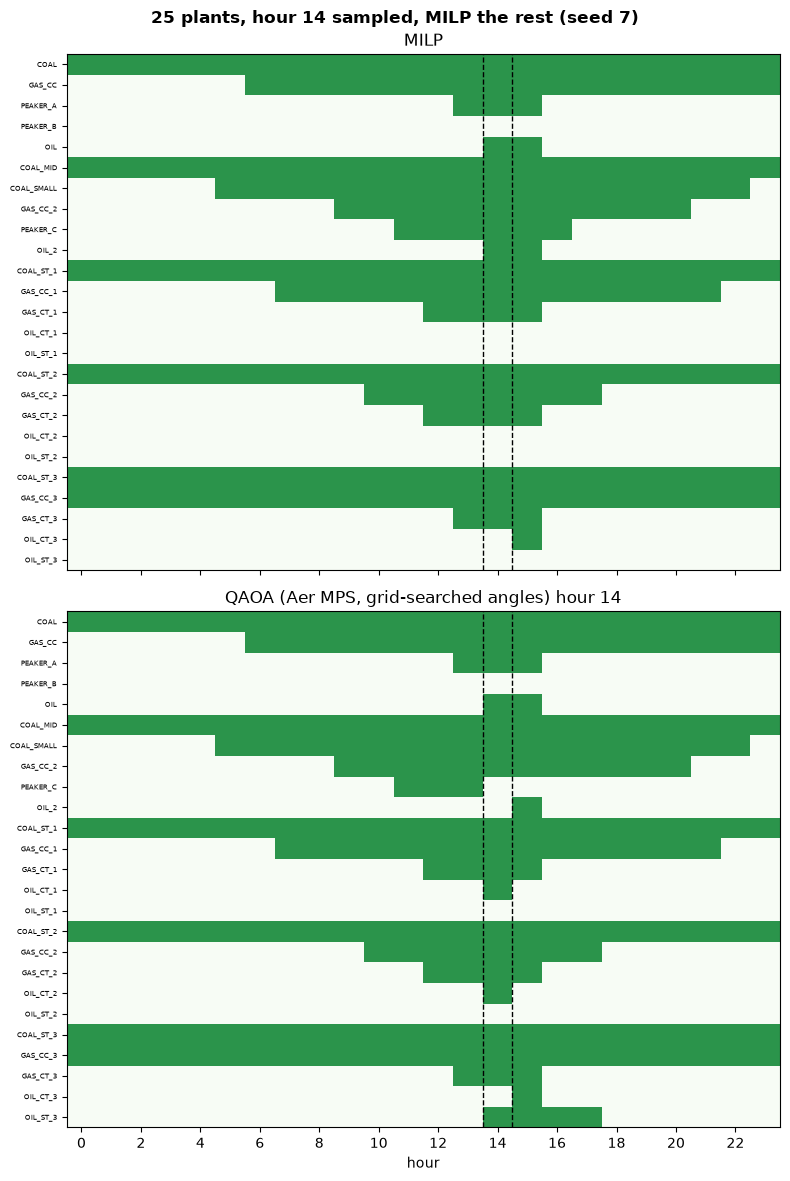


50 plants: MILP $2,801,196 in 0.43 s. One sampled hour per run, hours 13-17, 3 seeds.
  hour 13 ( 55 qubits, 5 slack) mps    : gap  +2.20% (seeds +2.81, +1.06, +2.73), hour-best 0/3, valid samples   4%, valid days 3/3,   4.3 s/run
  hour 13 ( 55 qubits, 5 slack) anneal : gap  +0.78% (seeds +1.22, +0.19, +0.93), hour-best 0/3, valid samples  60%, valid days 3/3,   0.9 s/run
  hour 14: the MILP had to break a min up/down lock
  hour 14: the MILP had to break a min up/down lock
  hour 14: the MILP had to break a min up/down lock
  hour 13 ( 55 qubits, 5 slack) random : gap +13.40% (seeds +12.49, +13.27, +14.44), hour-best 0/3, valid samples   0%, valid days 0/3,   0.8 s/run
  hour 14 ( 54 qubits, 4 slack) mps    : gap  +2.76% (seeds +2.99, +2.70, +2.60), hour-best 0/3, valid samples   1%, valid days 3/3,   5.1 s/run
  hour 14 ( 54 qubits, 4 slack) anneal : gap  +0.28% (seeds +0.33, +0.18, +0.32), hour-best 0/3, valid samples  94%, valid days 3/3,   0.9 s/run
  hour 15: the MILP had to br

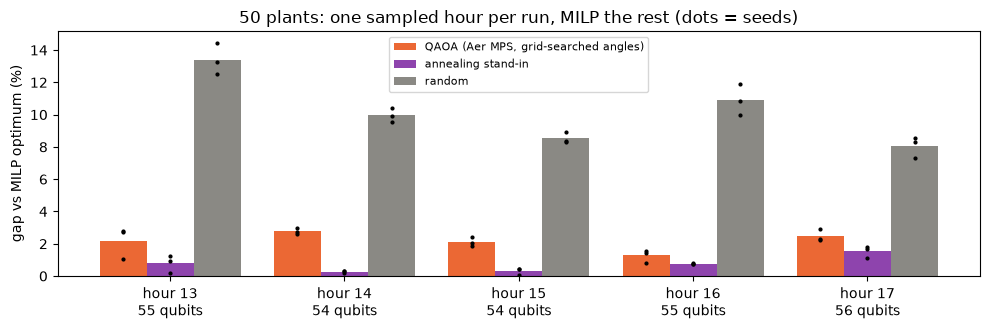


50 plants, hour 14 sampled, MILP the rest (seed 7)
method                          daily cost $       gap  rules broken
MILP (optimal)                     2,801,196    +0.00%             0
cheapest-first rule                2,827,229    +0.93%             3
QAOA (Aer MPS, grid-searched angles) hour 14 + MILP rest     2,885,021    +2.99%             0
annealing hour 14 + MILP rest      2,810,432    +0.33%             0
random hour 14 + MILP rest         3,068,172    +9.53%            27


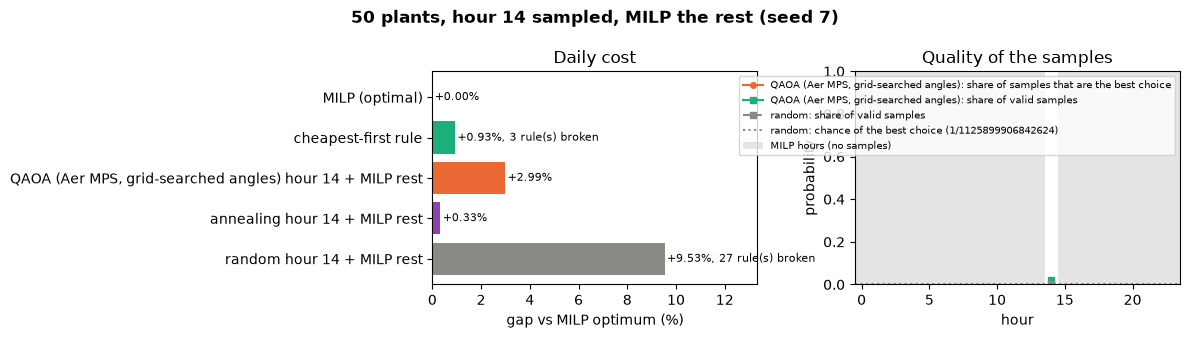

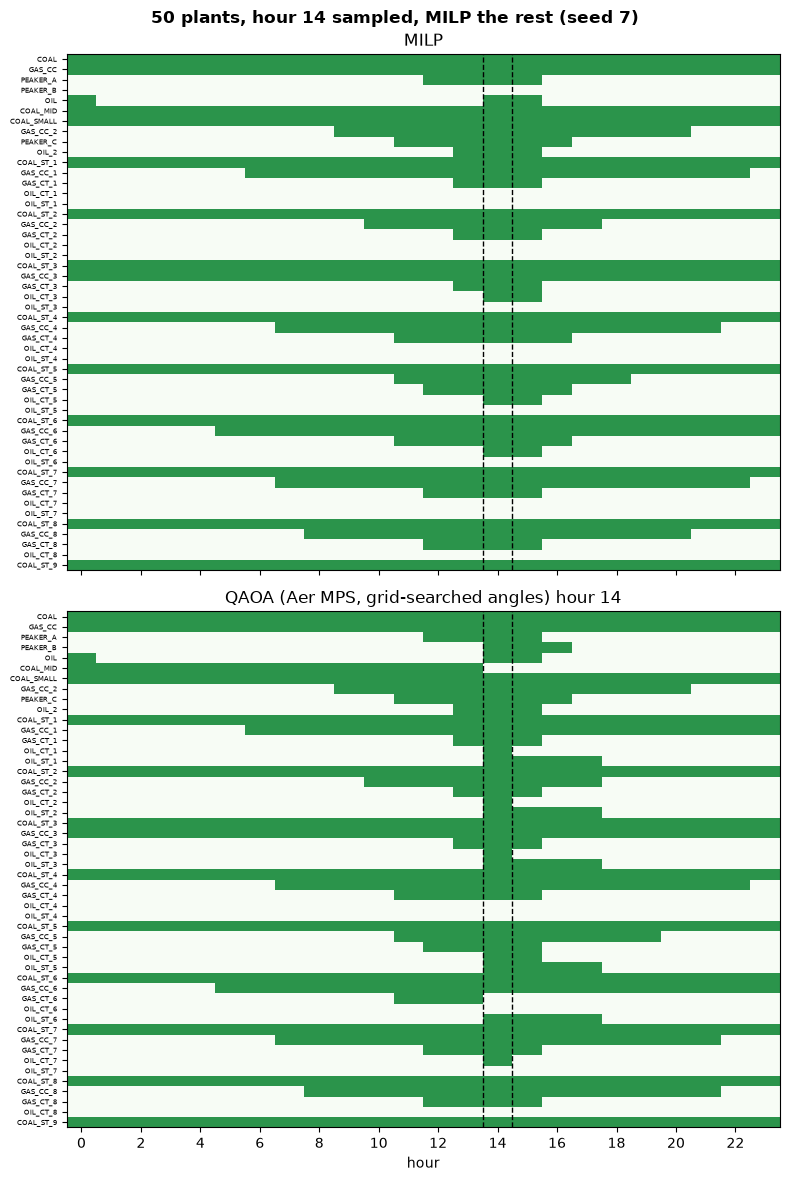


100 plants: MILP $5,037,376 in 0.73 s. One sampled hour per run, hours 13-17, 3 seeds.
  hour 13 (105 qubits, 5 slack) mps    : gap  +2.67% (seeds +2.12, +3.04, +2.84), hour-best 0/3, valid samples   0%, valid days 0/3,   8.4 s/run
  hour 13 (105 qubits, 5 slack) anneal : gap  +2.05% (seeds +1.99, +2.39, +1.77), hour-best 0/3, valid samples   5%, valid days 3/3,   1.8 s/run
  hour 14: the MILP had to break a min up/down lock
  hour 14: the MILP had to break a min up/down lock
  hour 14: the MILP had to break a min up/down lock
  hour 13 (105 qubits, 5 slack) random : gap +10.73% (seeds +10.31, +10.68, +11.19), hour-best 0/3, valid samples   0%, valid days 0/3,   1.3 s/run
  hour 15: the MILP had to break a min up/down lock
  hour 15: the MILP had to break a min up/down lock
  hour 15: the MILP had to break a min up/down lock
  hour 14 (105 qubits, 5 slack) mps    : gap  +7.44% (seeds +7.09, +8.28, +6.95), hour-best 0/3, valid samples   0%, valid days 0/3,   5.8 s/run
  hour 14 (105 qu

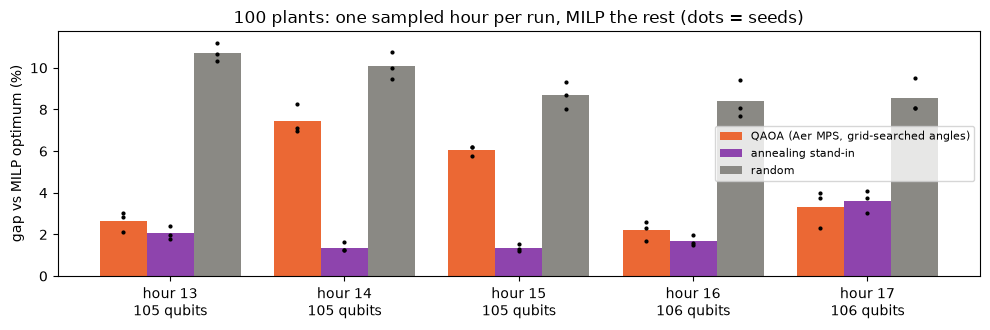


100 plants, hour 14 sampled, MILP the rest (seed 7)
method                          daily cost $       gap  rules broken
MILP (optimal)                     5,037,376    +0.00%             0
cheapest-first rule                5,069,983    +0.65%             4
QAOA (Aer MPS, grid-searched angles) hour 14 + MILP rest     5,394,598    +7.09%            34
annealing hour 14 + MILP rest      5,100,405    +1.25%             0
random hour 14 + MILP rest         5,514,263    +9.47%            38


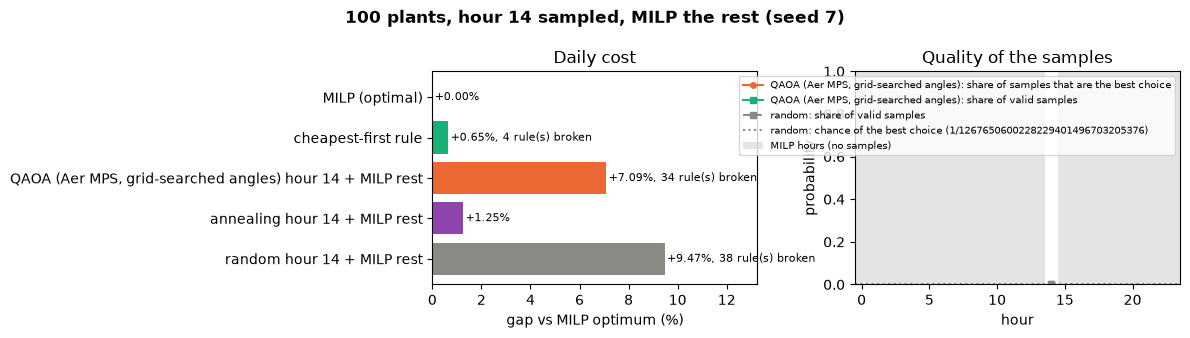

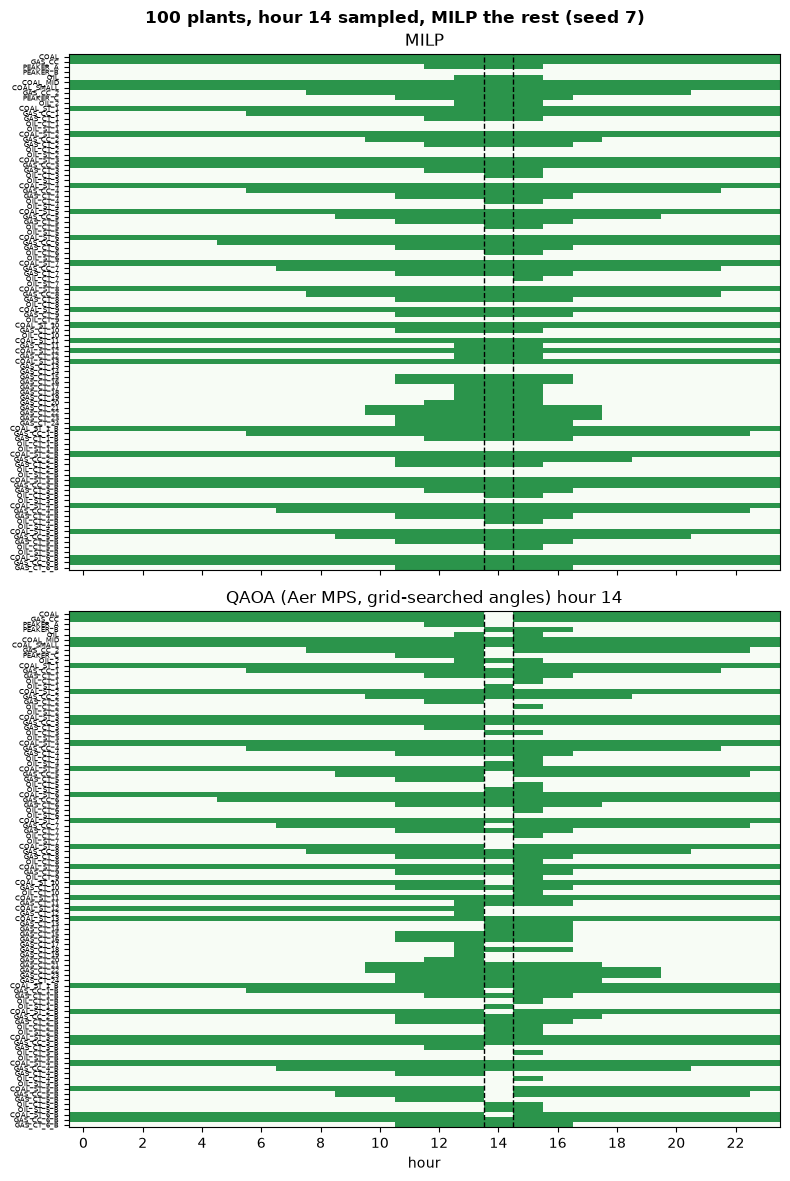


MIMIQ MPS pricing: per task 0, per shot 0, per minute 0 credits
  25 plants, 28 qubits: MIMIQ job qperfect:qperfect:sim:mimiq-mps-69e6-qjob-6af8f7efc8f5265fb3f21804 submitted, waiting ...
    Aer MPS   <E> 751,813, valid 11%
    MIMIQ MPS <E> 844,071, valid 12%, MIMIQ-reported fidelity 0.9999999999997602, cost 0, 42 s wall
  50 plants, 54 qubits: MIMIQ job qperfect:qperfect:sim:mimiq-mps-69e6-qjob-6af8f81cc8f5265fb3f21817 submitted, waiting ...
    Aer MPS   <E> 2,149,363, valid 0%
    MIMIQ MPS <E> 2,349,864, valid 1%, MIMIQ-reported fidelity 0.9999999999985334, cost 0, 19 s wall
  100 plants, 105 qubits: MIMIQ job qperfect:qperfect:sim:mimiq-mps-69e6-qjob-6af8f836c8f5265fb3f21824 submitted, waiting ...
    Aer MPS   <E> 17,521,055, valid 0%
    MIMIQ MPS <E> 17,697,645, valid 0%, MIMIQ-reported fidelity 0.9999999999958056, cost 0, 56 s wall

plants  qubits 13-17h       quantum sampler  mean gap  hour-best  valid days  anneal gap  random gap  s/run
    10          12-13            ex

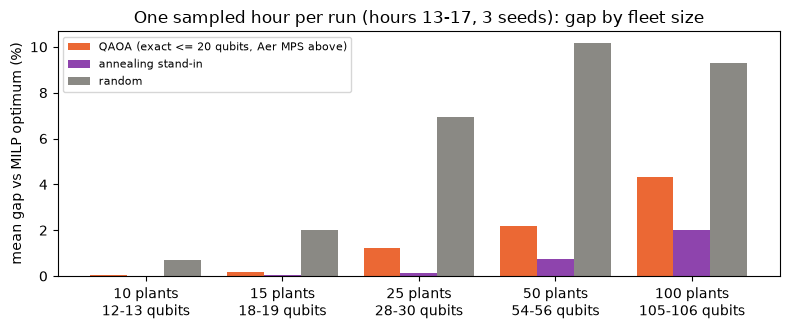

In [ ]:
# ==================== Hourly windows: one QAOA hour per run (hours 13-17), slack sized per hour, 10 to 100 plants ====================
# WHAT CHANGES. Each run hands ONE hour to the sampler and lets the MILP plan the other 23 (re-planned after
# that hour). Hours 13 to 17, three seeds each: 15 independent valid days per fleet instead of one.
# WHAT IT DOES AND DOES NOT SAVE. Every hour was already its own circuit, so splitting the window does not
# shrink any circuit: qubits per hour = plants + that hour's slack bits. Sizing the slack per hour saves 1 to
# 2 qubits (hour 14 needs fewer bits than hour 17). The real gain is statistics: many short, cheap runs.
# HOW THE BIG FLEETS RUN. Up to 20 qubits (10 and 15 plants) the QAOA is exact. Above that (25, 50, 100
# plants: 28 to 106 qubits) the circuit is simulated as a matrix product state (MPS):
#   * Aer's local MPS simulator (free, seconds per circuit). Below we show it reproduces the exact state at
#     18-19 qubits (fidelity 1.000 at bond dimension 32), and that its answers stop changing with bond
#     dimension at 54 and 106 qubits, which is the best check available where no exact state exists.
#   * QPerfect MIMIQ MPS through qBraid (qperfect:qperfect:sim:mimiq-mps, 0 credits on this account) as an
#     independent second opinion on one hour per big fleet. MIMIQ reports its own fidelity estimate.
#   Tuning angles by COBYLA would need hundreds of circuits per hour, so the MPS runs pick angles on a small
#   grid (lowest mean sampled energy), once per fleet and hour; the 100 plant fleet reuses the 50 plant
#   angles for the same hour and checks three gammas around them (a 105 qubit circuit takes about 27 s).
#   WHY THE GRID LOOKS DIFFERENT. At 28+ qubits the capacity penalty gives every plant a field that says
#   "on" (demand is 90% of capacity). With beta below pi/2 a one-layer mixer moves such qubits toward OFF,
#   so on-fractions fall to 0.3 and no sample is valid, whatever gamma. Beta between pi/2 and pi reverses
#   that. The notebook's grid stops at beta = 1.5 and the small fleets' optimizer got around it with large
#   gamma; from 18 qubits up that fails (0% valid samples), so here the exact runs also search beta up to 3.0.
# Every plant is in the QUBO in every sampled hour, as before. Stand-ins (annealing, random) run alongside.
from qiskit_aer import AerSimulator as _AerSimulator

QAOA_BETA_MAX = 3.0        # exact runs here search beta over the whole half-turn (see "WHY THE GRID LOOKS DIFFERENT")
HOURLY_HOURS = list(range(13, 18))
HOURLY_SEEDS = (7, 8, 9)
HOURLY_FLEETS = (10, 15, 25, 50, 100)
MPS_BOND = 64                                   # bond dimension for the Aer MPS runs
MPS_GRID = [(g, b) for g in (0.4, 0.8, 1.2, 1.8, 2.6) for b in (2.1, 2.3, 2.5)]   # angle grid for fleets <= 60 qubits
MPS_GRID_SMALL = (-0.4, 0.0, 0.4)                # gamma offsets checked around the inherited angles above 60 qubits
MPS_BIG_QUBITS = 60
USE_MIMIQ = RUN_REMOTE_MIMIQ                                # one free MIMIQ MPS job per big fleet (hour 14); set False to skip cloud jobs
MIMIQ_DEVICE = "qperfect:qperfect:sim:mimiq-mps"

for n in HOURLY_FLEETS:                         # the 100 plant fleet is new; build it if needed
    if n not in BIG_FLEETS:
        if not (DATA / f"plants{n}.csv").exists():
            sys.path.insert(0, str(DATA))
            import make_fleets
            make_fleets.main()
        BIG_FLEETS[n] = (load_plants(DATA / f"plants{n}.csv"), *load_demand(DATA / f"demand{n}.csv"))


def qaoa_measured_circuit(Q, angles):
    # The notebook's p=1 QAOA circuit (qaoa_circuit) with the angles filled in and every qubit measured.
    circ, params = qaoa_circuit(Q, p=1)
    qc = QuantumCircuit(len(Q), len(Q))
    qc.compose(circ.assign_parameters(dict(zip(params, angles))), inplace=True)
    qc.measure(range(len(Q)), range(len(Q)))
    return qc


def counts_to_bits(counts, n_qubits):
    # Qiskit/qBraid bitstrings list qubit 0 LAST; return one row of bits per shot, bit j = qubit j.
    rows = []
    for key, c in counts.items():
        key = key.replace(" ", "")
        rows += [[int(key[-1 - j]) for j in range(n_qubits)]] * int(c)
    return np.array(rows, dtype=int)


def sample_energies(Q, offset, bits):
    U = np.triu(Q)
    return np.einsum("bj,jk,bk->b", bits, U, bits) + offset


def aer_mps_counts(qc, shots, seed, bond=MPS_BOND):
    # No transpile: Qiskit's transpiler caps circuits at 63 qubits, Aer's MPS itself does not (n_qubits=130).
    sim = _AerSimulator(method="matrix_product_state", matrix_product_state_max_bond_dimension=bond,
                        matrix_product_state_truncation_threshold=1e-10, n_qubits=130)
    return sim.run(qc, shots=shots, seed_simulator=seed).result().get_counts()


MPS_ANGLES = {}            # (plants, hour) -> chosen angles, so the seeds of one hour reuse the search


def make_mps_sampler(n_plants, inherit_from=None, bond=MPS_BOND):
    # A sampler for schedule_day_hybrid_big: p=1 QAOA circuit on Aer MPS, angles from a grid search
    # (lowest mean sampled energy). Above MPS_BIG_QUBITS, inherit the angles of fleet `inherit_from` for the
    # same hour and only check a few gammas around them.
    def mps_sampler(Q, offset, shots, rng, hour):
        key = (n_plants, int(hour))
        if key not in MPS_ANGLES:
            base = MPS_ANGLES.get((inherit_from, int(hour)))
            if len(Q) > MPS_BIG_QUBITS and base is not None:
                grid = [(base[0] + dg, base[1]) for dg in MPS_GRID_SMALL if base[0] + dg > 0]
            else:
                grid = MPS_GRID
            scored = []
            for angles in grid:
                counts = aer_mps_counts(qaoa_measured_circuit(Q, angles), shots, seed=int(rng.integers(1 << 30)), bond=bond)
                scored.append((sample_energies(Q, offset, counts_to_bits(counts, len(Q))).mean(), tuple(angles)))
            MPS_ANGLES[key] = min(scored)[1]
        counts = aer_mps_counts(qaoa_measured_circuit(Q, MPS_ANGLES[key]), shots, seed=int(rng.integers(1 << 30)), bond=bond)
        return counts_to_bits(counts, len(Q))
    mps_sampler.__name__ = "mps"
    return mps_sampler


# ==================== Is the MPS truncation trustworthy? ====================
print("Aer MPS vs the exact state (15 plants, 18-19 qubits), and convergence in bond dimension where no exact state exists")
fleet15, load15, margin15 = BIG_FLEETS[15]
sched15 = solve_milp(fleet15, load15, margin15)[1]
for t in (14, 17):
    bits_t, _ = slack_bits_for(fleet15, load15, margin15, [t])
    with fleet_globals(fleet15, load15, margin15, n_slack=bits_t):
        Q, off = build_qubo(plants, demand[t], reserve[t], sched15[t - 1])
        h, J = qubo_to_ising(Q)
        scale = max(np.abs(h).max(), max(abs(v) for v in J.values()))
        exact = qaoa_probs_diagonal(all_energies(Q, off), scale, np.array([2.0, 0.9]))
        line = []
        for bond in (8, 32, 128):
            circ, params = qaoa_circuit(Q, p=1)
            qc = circ.assign_parameters(dict(zip(params, [2.0, 0.9])))
            qc.save_statevector()
            sim = _AerSimulator(method="matrix_product_state", matrix_product_state_max_bond_dimension=bond,
                                matrix_product_state_truncation_threshold=1e-10)
            sv = np.asarray(sim.run(qc).result().get_statevector())
            fid = float(np.sum(np.sqrt(exact * np.abs(sv) ** 2)) ** 2)      # Bhattacharyya overlap of the two distributions
            line.append(f"bond {bond}: overlap {fid:.4f}")
        print(f"  hour {t}, {N_QUBITS} qubits: " + ", ".join(line) + "   (overlap of the two probability distributions; 1 = identical)")
mps_convergence = {}
for n in (50, 100):
    fleet, load, margin = BIG_FLEETS[n]
    t = 14
    bits_t, _ = slack_bits_for(fleet, load, margin, [t])
    sched = solve_milp(fleet, load, margin)[1]
    with fleet_globals(fleet, load, margin, n_slack=bits_t, tables=False):
        Q, off = build_qubo(plants, demand[t], reserve[t], sched[t - 1])
        must_on, must_off = locks(plants, list(sched[:t]))
        line = []
        for bond in (8, 32, 128):
            started = time.perf_counter()
            counts = aer_mps_counts(qaoa_measured_circuit(Q, [1.2, 2.3]), 400, seed=3, bond=bond)
            bits = counts_to_bits(counts, N_QUBITS)
            e = sample_energies(Q, off, bits).mean()
            valid = np.mean([hour_ok(plants, demand[t], reserve[t], row[:N], must_on, must_off) for row in bits])
            mps_convergence[(n, bond)] = dict(mean_energy=e, valid_share=valid, seconds=time.perf_counter() - started)
            line.append(f"bond {bond}: <E> {e:,.0f}, valid {valid:.0%}, {time.perf_counter() - started:.0f} s")
        print(f"  {n} plants, hour {t}, {N_QUBITS} qubits, 400 shots: " + " | ".join(line))

# ==================== The hourly runs ====================
def run_hourly_windows(n, hours=HOURLY_HOURS, seeds=HOURLY_SEEDS, shots=SCALE_SHOTS, inherit_from=None):
    fleet, load, margin = BIG_FLEETS[n]
    milp_cost, milp_schedule, _, milp_secs = solve_milp(fleet, load, margin)
    milp_result = check_schedule(fleet, load, margin, milp_schedule, milp_cost=milp_cost, verbose=False)
    rule_result = check_schedule(fleet, load, margin, cheapest_first(fleet, load, margin), milp_cost=milp_cost, verbose=False)
    rows, runs = [], {}
    print(f"\n{n} plants: MILP ${milp_cost:,.0f} in {milp_secs:.2f} s. One sampled hour per run, hours {hours[0]}-{hours[-1]}, "
          f"{len(seeds)} seeds.", flush=True)
    for t in hours:
        bits_t, spare_t = slack_bits_for(fleet, load, margin, [t])
        n_qubits = n + bits_t
        exact_ok = n_qubits <= QAOA_MAX_QUBITS
        quantum = "qaoa" if exact_ok else make_mps_sampler(n, inherit_from)
        with fleet_globals(fleet, load, margin, n_slack=bits_t, tables=exact_ok):
            for sampler in (quantum, "anneal", "random"):
                name = sampler if isinstance(sampler, str) else sampler.__name__
                gaps, hits, valid_shares, secs, valid_days, logs = [], 0, [], [], 0, []
                for seed in seeds:
                    started = time.perf_counter()
                    schedule, log = schedule_day_hybrid_big([t], sampler, shots=shots, seed=seed)
                    secs.append(time.perf_counter() - started)
                    result = check_schedule(fleet, load, margin, schedule, milp_cost=milp_cost, verbose=False)
                    row = next(r for r in log if r["hour"] == t)
                    assert row["plants_decided"] == n
                    gaps.append(result["gap_pct"])
                    hits += bool(row["matches_best"])
                    valid_shares.append(row["valid_share"])
                    valid_days += result["valid"]
                    runs[(t, name, seed)] = dict(schedule=schedule, log=log, result=result)
                rows.append(dict(hour=t, sampler=name, qubits=n_qubits, slack_bits=bits_t, spare_blocks=spare_t[t],
                                 gaps=gaps, mean_gap=float(np.mean(gaps)), hits=hits, valid_share=float(np.mean(valid_shares)),
                                 valid_days=valid_days, seconds=float(np.mean(secs)),
                                 angles=(MPS_ANGLES.get((n, t)) if name == "mps" else
                                         next(r for r in runs[(t, name, seeds[0])]["log"] if r["hour"] == t)["angles"])))
                print(f"  hour {t} ({n_qubits:>3} qubits, {bits_t} slack) {name:<7}: gap {np.mean(gaps):+6.2f}% "
                      f"(seeds {', '.join(f'{g:+.2f}' for g in gaps)}), hour-best {hits}/{len(seeds)}, "
                      f"valid samples {np.mean(valid_shares):4.0%}, valid days {valid_days}/{len(seeds)}, {np.mean(secs):5.1f} s/run", flush=True)
    return dict(plants=n, milp_cost=milp_cost, milp_seconds=milp_secs, milp_schedule=milp_schedule, milp_result=milp_result,
                rule_result=rule_result, rows=rows, runs=runs)


def plot_hourly(res):
    n, rows = res["plants"], res["rows"]
    samplers = []
    for r in rows:
        if r["sampler"] not in samplers:
            samplers.append(r["sampler"])
    colors = {"qaoa": COLORS["qaoa"], "mps": COLORS["qaoa"], "anneal": SAMPLER_COLORS["anneal"], "random": COLORS["random"]}
    labels = {"qaoa": "QAOA (exact simulation)", "mps": "QAOA (Aer MPS, grid-searched angles)",
              "anneal": "annealing stand-in", "random": "random"}
    fig, ax = plt.subplots(figsize=(10, 3.4))
    x = np.arange(len(HOURLY_HOURS))
    for k, s in enumerate(samplers):
        sub = [r for r in rows if r["sampler"] == s]
        ax.bar(x + (k - 1) * 0.27, [r["mean_gap"] for r in sub], 0.27, color=colors[s], label=labels[s])
        for xi, r in zip(x, sub):
            ax.plot([xi + (k - 1) * 0.27] * len(r["gaps"]), r["gaps"], "k.", ms=4)
    ax.set_xticks(x, [f"hour {r['hour']}\n{r['qubits']} qubits" for r in rows if r["sampler"] == samplers[0]])
    ax.set(ylabel="gap vs MILP optimum (%)", title=f"{n} plants: one sampled hour per run, MILP the rest (dots = seeds)")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    # The same three pictures as every other test, for one representative run: hour 14, first seed.
    t, s = 14, samplers[0]
    run, rnd = res["runs"][(t, s, HOURLY_SEEDS[0])], res["runs"][(t, "random", HOURLY_SEEDS[0])]
    results = {"MILP (optimal)": (res["milp_result"], COLORS["milp"]), "cheapest-first rule": (res["rule_result"], COLORS["rule"]),
               f"{labels[s]} hour {t} + MILP rest": (run["result"], colors[s]),
               f"annealing hour {t} + MILP rest": (res["runs"][(t, "anneal", HOURLY_SEEDS[0])]["result"], colors["anneal"]),
               f"random hour {t} + MILP rest": (rnd["result"], colors["random"])}
    report_fleet_day(f"{n} plants, hour {t} sampled, MILP the rest (seed {HOURLY_SEEDS[0]})", results, run["log"], rnd["log"],
                     res["milp_schedule"], run["schedule"], f"{labels[s]} hour {t}", [p["plant_id"] for p in BIG_FLEETS[n][0]],
                     sampler_name=labels[s], p_best_label="share of samples that are the best choice",
                     milp_hours=[h for h in range(24) if h != t])


hourly_results = {}
previous_mps_fleet = None
for n in HOURLY_FLEETS:
    hourly_results[n] = run_hourly_windows(n, inherit_from=previous_mps_fleet)
    if n + 3 > QAOA_MAX_QUBITS:                  # an MPS fleet: the next, bigger one may inherit its angles
        previous_mps_fleet = n
    plot_hourly(hourly_results[n])

# ==================== MIMIQ MPS: an independent second opinion on hour 14 (free on this account) ====================
mimiq_checks = {}
if USE_MIMIQ:
    from qbraid.runtime import QbraidProvider
    mimiq = QbraidProvider().get_device(MIMIQ_DEVICE)
    price = mimiq.profile.pricing
    print(f"\nMIMIQ MPS pricing: per task {price.perTask}, per shot {price.perShot}, per minute {price.perMinute} credits")
    for n in (25, 50, 100):
        fleet, load, margin = BIG_FLEETS[n]
        t = 14
        bits_t, _ = slack_bits_for(fleet, load, margin, [t])
        sched = hourly_results[n]["milp_schedule"]
        with fleet_globals(fleet, load, margin, n_slack=bits_t, tables=False):
            Q, off = build_qubo(plants, demand[t], reserve[t], sched[t - 1])
            must_on, must_off = locks(plants, list(sched[:t]))
            angles = MPS_ANGLES.get((n, t), (1.2, 2.3))
            qc = qaoa_measured_circuit(Q, angles)
            started = time.perf_counter()
            job = mimiq.run(qc, shots=SCALE_SHOTS)
            print(f"  {n} plants, {N_QUBITS} qubits: MIMIQ job {job.id} submitted, waiting ...", flush=True)
            result = job.result()
            wall = time.perf_counter() - started
            bits_mimiq = counts_to_bits(result.data.get_counts(), N_QUBITS)
            bits_aer = counts_to_bits(aer_mps_counts(qc, SCALE_SHOTS, seed=5), N_QUBITS)
            details = getattr(result, "details", {}) or {}
            summary = {}
            for name, bits in (("Aer MPS", bits_aer), ("MIMIQ MPS", bits_mimiq)):
                summary[name] = dict(mean_energy=float(sample_energies(Q, off, bits).mean()),
                                     valid_share=float(np.mean([hour_ok(plants, demand[t], reserve[t], r[:N], must_on, must_off) for r in bits])))
            mimiq_checks[n] = dict(job_id=job.id, wall_s=wall, mimiq_fidelity=details.get("fidelity"), cost=details.get("cost"), summary=summary)
            print(f"    Aer MPS   <E> {summary['Aer MPS']['mean_energy']:,.0f}, valid {summary['Aer MPS']['valid_share']:.0%}")
            print(f"    MIMIQ MPS <E> {summary['MIMIQ MPS']['mean_energy']:,.0f}, valid {summary['MIMIQ MPS']['valid_share']:.0%}, "
                  f"MIMIQ-reported fidelity {details.get('fidelity')}, cost {details.get('cost')}, {wall:.0f} s wall", flush=True)

# ==================== Summary across fleets ====================
print(f"\n{'plants':>6}{'qubits 13-17h':>15}{'quantum sampler':>22}{'mean gap':>10}{'hour-best':>11}{'valid days':>12}{'anneal gap':>12}{'random gap':>12}{'s/run':>7}")
for n, res in hourly_results.items():
    q = [r for r in res["rows"] if r["sampler"] in ("qaoa", "mps")]
    a = [r for r in res["rows"] if r["sampler"] == "anneal"]
    rr = [r for r in res["rows"] if r["sampler"] == "random"]
    print(f"{n:>6}{f'{min(r['qubits'] for r in q)}-{max(r['qubits'] for r in q)}':>15}"
          f"{('exact QAOA' if q[0]['sampler'] == 'qaoa' else 'QAOA on Aer MPS'):>22}"
          f"{np.mean([r['mean_gap'] for r in q]):>+9.2f}%{f'{sum(r['hits'] for r in q)}/{len(q) * len(HOURLY_SEEDS)}':>11}"
          f"{f'{sum(r['valid_days'] for r in q)}/{len(q) * len(HOURLY_SEEDS)}':>12}"
          f"{np.mean([r['mean_gap'] for r in a]):>+11.2f}%{np.mean([r['mean_gap'] for r in rr]):>+11.2f}%"
          f"{np.mean([r['seconds'] for r in q]):>7.1f}")
print("Gaps are whole-day gaps with one sampled hour; averages over 5 hours x 3 seeds. MPS rows use grid-searched angles.")

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(hourly_results))
for k, (s, label, color) in enumerate((("quantum", "QAOA (exact <= 20 qubits, Aer MPS above)", COLORS["qaoa"]),
                                       ("anneal", "annealing stand-in", SAMPLER_COLORS["anneal"]), ("random", "random", COLORS["random"]))):
    vals = []
    for n, res in hourly_results.items():
        sel = [r for r in res["rows"] if (r["sampler"] in ("qaoa", "mps")) if s == "quantum"] if s == "quantum" else [r for r in res["rows"] if r["sampler"] == s]
        vals.append(np.mean([r["mean_gap"] for r in sel]))
    ax.bar(x + (k - 1) * 0.27, vals, 0.27, color=color, label=label)
ax.set_xticks(x, [f"{n} plants\n{min(r['qubits'] for r in res['rows'])}-{max(r['qubits'] for r in res['rows'])} qubits"
                  for n, res in hourly_results.items()])
ax.set(ylabel="mean gap vs MILP optimum (%)", title="One sampled hour per run (hours 13-17, 3 seeds): gap by fleet size")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
# ================== End of the hourly windows ==================


### Supporting study — wind and solar: scheduling against net load

RTS-GMLC's day-ahead solar and wind forecast for the demand day, scaled to the ten-plant fleet. The MILP is re-solved on the same net load, and runs A/B/C move the five QAOA hours from the gross-demand peak to the net-load peak, with random guesses as the honesty check. Separate from the reduced-qubit results; needs E 2–E 4 to have run (and E 8 for the chosen window).


In [ ]:
# ==================== Wind and solar: scheduling against net load (10 plants) ====================
# Stretch goal 4 of the stretch-goals cell, with real data. Wind and solar cost nothing to run, so the
# thermal fleet only has to cover the NET LOAD = demand - solar - wind. The recipe:
#   * forecasts, not qubits: solar and wind enter as the day-ahead forecast and reduce the thermal demand.
#     The QUBO, the circuit, the locks and the hybrid scheduler are unchanged; they see thermal_demand =
#     net load instead of demand. No renewable qubits are added.
#   * both methods see the same numbers: the MILP baseline is re-solved on the same net load, so every gap
#     is against the optimum of the SAME scenario. Run B's dollars are never compared with run A's
#     baseline: renewables change the energy supply, not the algorithm.
#   * the reserve stays the original 10% of GROSS demand (demand10.csv). It is not recomputed from the net
#     load (that would shrink it), and renewables are not counted as firm capacity. RENEWABLE_RESERVE_SHARE
#     adds a share of the renewable output to the reserve (TVA: reserves cover forecast error); 0 here.
#   * curtailment check: a thermal plant cannot run below pmin, so when the net load falls below the
#     minimum output of the units that must be on, some renewable output has to be curtailed (spilled).
#     The starter's MILP and checker use an equality (thermal output = demand), so curtailment is
#     measured with the MILP variant below (solve_milp_renewables); the hour-by-hour pipeline is only
#     run at a share where the optimum curtails 0 MW, which is checked, not assumed.
# DATA  data/renewables.csv: RTS-GMLC's DAY_AHEAD_pv.csv and DAY_AHEAD_wind.csv, region 3 totals for the
#       demand day (July 14 2020), built by data/make_renewables.py (see data/README.md). Scaled to the
#       fleet by RENEWABLE_SCALE = our peak demand / RTS-GMLC's system peak load that day, which gives the
#       10 plant fleet RTS-GMLC's own renewable share (16.5% of the day's energy from utility solar and
#       wind). Region 3 alone has a 55% share (it exports wind at night in RTS-GMLC); that case and others
#       appear in the sensitivity table with their curtailment, but are not run hour by hour.
# RUNS  3 seeds each; QAOA, and random guesses as the honesty check, in the sampled hours; MILP for the
#       other hours; all 10 plants in every sampled hour (13 qubits), exactly as in hybrid D above:
#   A  no renewables   QAOA 13:00-18:00 (hours 13-17, the window picked above)  <- the earlier +0.19% result
#   B  solar + wind    QAOA 13:00-18:00 (the GROSS-demand peak)
#   C  solar + wind    QAOA in the 5 highest NET-load hours
#   If C beats B (same renewables, same 5-hour budget), renewable-aware selection of the quantum hours
#   helps; B against A says how the same window copes when solar flattens the afternoon peak.
# Needs the starter cells, the 10 plant run (E 2), its graph helpers (E 3) and the hybrid helpers (E 4);
# it reuses QAOA_BEST_HOURS and SWEEP_SEEDS from E 8 when they exist. About 3 minutes, local, no cloud jobs.
import csv
from check import DATA

RENEWABLE_SERIES = ("solar_mw", "wind_mw")     # add "rooftop_solar_mw" for rooftop PV too (22% share)
RENEWABLE_RESERVE_SHARE = 0.0                  # extra reserve as a share of the renewable output (0 = teammate's rule)
RENEWABLE_SEEDS = tuple(SWEEP_SEEDS) if "SWEEP_SEEDS" in globals() else (7, 8, 9)
GROSS_PEAK_HOURS = sorted(int(t) for t in QAOA_BEST_HOURS) if "QAOA_BEST_HOURS" in globals() else list(range(13, 18))
N_SAMPLED_HOURS = len(GROSS_PEAK_HOURS)
RENEW_COLORS = {"solar": "#f2b134", "wind": "#3aa7a3", "net": "#7a3fb0"}

fleet10, gross_demand, gross_reserve = (ten_plant_results["plants"], np.asarray(ten_plant_results["demand"], float),
                                        np.asarray(ten_plant_results["reserve"], float))
assert len(fleet10) == 10 and len(gross_demand) == 24

with open(DATA / "renewables.csv", newline="") as f:
    renewable_rows = list(csv.DictReader(f))
assert len(renewable_rows) == 24 and [int(r["hour"]) for r in renewable_rows] == list(range(24))
rts_series = {k: np.array([float(r[k]) for r in renewable_rows]) for k in renewable_rows[0] if k != "hour"}
RENEWABLE_SCALE = gross_demand.max() / rts_series["system_load_mw"].max()      # RTS-GMLC's own share
REGION3_SCALE = gross_demand.max() / rts_series["region3_load_mw"].max()       # region 3's share (exports wind)


def hours_short(hour_list):
    # [13, 14, 15, 16, 17] -> "13:00-18:00"; non-contiguous sets list every stretch.
    return ", ".join(f"{a}:00-{b + 1}:00" for a, b in hour_stretches(sorted(hour_list)))


def hours_text(hour_list):
    # [13, 14, 15, 16, 17] -> "13:00-18:00 (hours 13-17)", the notebook's time convention.
    inner = ", ".join(f"{a}-{b}" if a != b else f"{a}" for a, b in hour_stretches(sorted(hour_list)))
    return f"{hours_short(hour_list)} (hours {inner})"


def scaled_renewables(scale, series=RENEWABLE_SERIES):
    # Solar and wind in MW for the fleet: the RTS-GMLC region 3 forecast times `scale`.
    solar = sum(rts_series[k] for k in series if "solar" in k) * scale
    wind = sum(rts_series[k] for k in series if "wind" in k) * scale
    return dict(solar=solar, wind=wind, total=solar + wind)


def thermal_requirements(renewables):
    # What the thermal fleet must cover: net load, and the original reserve (plus the optional forecast-error share).
    net = gross_demand - renewables["total"]
    margin = gross_reserve + RENEWABLE_RESERVE_SHARE * renewables["total"]
    return net, margin


def solve_milp_renewables(plants, demand, reserve, renewable):
    """check.solve_milp plus one curtailment variable per hour: the renewable MW spilled.

    thermal output + used renewables = demand, 0 <= used <= forecast; headroom (capacity on - output)
    >= reserve, which is the starter's reserve rule when nothing is curtailed; the usual pmin/pmax,
    startup and min up/down rules. Returns (cost, schedule, dispatch, curtailed_mw [per hour], seconds).
    """
    n, T = len(plants), len(demand)
    U = lambda i, t: i * T + t
    V = lambda i, t: n * T + i * T + t
    P = lambda i, t: 2 * n * T + i * T + t
    C = lambda t: 3 * n * T + t
    n_var = 3 * n * T + T
    cost = np.zeros(n_var)
    rows, lo, hi = [], [], []

    def add(terms, low, high):            # low <= sum(coef * x[j]) <= high
        rows.append(terms)
        lo.append(low)
        hi.append(high)

    for t in range(T):
        add([(P(i, t), 1) for i in range(n)] + [(C(t), -1)], demand[t] - renewable[t], demand[t] - renewable[t])
        add([(U(i, t), p["pmax_mw"]) for i, p in enumerate(plants)] + [(P(i, t), -1) for i in range(n)],
            reserve[t], np.inf)
    for i, p in enumerate(plants):
        up, down, u0 = int(p["min_up_h"]), int(p["min_down_h"]), int(p["on_at_start"])
        for t in range(T):
            cost[U(i, t)] = p["no_load_cost_per_h"]
            cost[V(i, t)] = p["startup_cost"]
            cost[P(i, t)] = p["marginal_cost_per_mwh"]
            add([(P(i, t), 1), (U(i, t), -p["pmin_mw"])], 0, np.inf)
            add([(P(i, t), 1), (U(i, t), -p["pmax_mw"])], -np.inf, 0)
            before = [(U(i, t - 1), 1)] if t > 0 else []
            add([(V(i, t), 1), (U(i, t), -1)] + before, -u0 if t == 0 else 0, np.inf)
            add([(V(i, s), 1) for s in range(max(0, t - up + 1), t + 1)] + [(U(i, t), -1)], -np.inf, 0)
            window = [(V(i, s), 1) for s in range(max(0, t - down + 1), t + 1)]
            if t - down >= 0:
                add(window + [(U(i, t - down), 1)], -np.inf, 1)
            else:
                add(window, -np.inf, 1 - u0)
    A = lil_matrix((len(rows), n_var))
    for k, terms in enumerate(rows):
        for j, a in terms:
            A[k, j] += a
    integrality = np.r_[np.ones(2 * n * T), np.zeros(n * T + T)]
    upper = np.r_[np.ones(2 * n * T), [p["pmax_mw"] for p in plants for _ in range(T)], np.maximum(renewable, 0)]
    started = time.perf_counter()
    res = scipy_milp(cost, constraints=LinearConstraint(A.tocsr(), lo, hi),
                     integrality=integrality, bounds=Bounds(0, upper))
    seconds = time.perf_counter() - started
    if res.x is None:
        raise RuntimeError(f"The MILP found no schedule even with curtailment: {res.message}")
    schedule = np.array([[round(res.x[U(i, t)]) for i in range(n)] for t in range(T)])
    dispatch = np.array([[res.x[P(i, t)] for i in range(n)] for t in range(T)])
    curtailed = np.array([res.x[C(t)] for t in range(T)])
    return res.fun, schedule, dispatch, curtailed, seconds


def _slack_bits(fleet, load, margin):
    # Slack qubits the QUBO needs to spell out the spare capacity (slack_bits_needed from the stretch cell).
    if "slack_bits_needed" in globals():
        return slack_bits_needed(fleet, load, margin)
    total_blocks = sum(p["pmax_mw"] for p in fleet) / BLOCK_MW
    spare = [int(total_blocks - np.ceil((d + r) / BLOCK_MW)) for d, r in zip(load, margin)]
    return spare, int(np.ceil(np.log2(max(spare) + 1)))


# ---- Sensitivity: how much renewable output can this fleet take before it has to curtail? ----
print(f"10 plant fleet, {gross_demand.max():.0f} MW peak. RTS-GMLC July 14 2020 region 3 forecast scaled by "
      f"{RENEWABLE_SCALE:.3f} (= our peak / RTS-GMLC system peak {rts_series['system_load_mw'].max():,.0f} MW); "
      f"region 3 alone would be x{REGION3_SCALE / RENEWABLE_SCALE:.2f} that.")
RENEWABLE_CASES = {"none": 0.0, "half the RTS-GMLC share": 0.5, "RTS-GMLC share (runs B, C)": 1.0,
                   "double": 2.0, "region 3 share": REGION3_SCALE / RENEWABLE_SCALE}
print(f"\n{'renewables':<28}{'energy share':>13}{'min net MW':>12}{'net peak':>9} {'5 top net hours':>18}"
      f"{'evening climb':>15}{'MILP $':>12}{'curtailed MWh':>15}{'slack bits':>12}{'3 bits miss':>13}")
sensitivity_rows = []
for case, multiple in RENEWABLE_CASES.items():
    renew = scaled_renewables(multiple * RENEWABLE_SCALE)
    net, margin = thermal_requirements(renew)
    cost, _, _, curtailed, _ = solve_milp_renewables(fleet10, gross_demand, margin, renew["total"])
    spare, bits = _slack_bits(fleet10, np.maximum(net, 0), margin)
    top = sorted(int(t) for t in np.argsort(-net)[:N_SAMPLED_HOURS])
    climb = float(np.diff(net)[12:].max())                     # biggest hour-to-hour rise after noon
    sensitivity_rows.append(dict(case=case, multiple=multiple, share=renew["total"].sum() / gross_demand.sum(),
                                 net=net, cost=cost, curtailed=curtailed, top_hours=top))
    print(f"{case:<28}{renew['total'].sum() / gross_demand.sum():>12.1%}{net.min():>8.0f} (h{net.argmin():>2}){net.argmax():>8}h "
          f"{str(top):>18}{climb:>+13.0f}/h{cost:>12,.0f}{curtailed.sum():>8.0f} ({int((curtailed > 0.5).sum())} h)"
          f"{bits:>12}{sum(s > 2 ** N_SLACK - 1 for s in spare):>10}/24")
print("evening climb = biggest hour-to-hour rise of the net load after noon (TVA's evening ramp); "
      "3 bits miss = hours where 3 slack bits cannot spell the spare capacity.")

# ---- The scenario for the hybrid runs: RTS-GMLC's share, and the curtailment check ----
renewables10 = scaled_renewables(RENEWABLE_SCALE)
thermal_demand, thermal_reserve = thermal_requirements(renewables10)
curt_cost, _, _, curt_mw, _ = solve_milp_renewables(fleet10, gross_demand, thermal_reserve, renewables10["total"])
assert curt_mw.sum() < 1e-6, f"the optimum curtails {curt_mw.sum():.0f} MWh: the hour-by-hour pipeline needs a curtailment variable first"
net_milp_cost, net_milp_schedule, net_milp_dispatch, _ = solve_milp(fleet10, thermal_demand, thermal_reserve)
assert abs(net_milp_cost - curt_cost) < 1e-3 * curt_cost
NET_PEAK_HOURS = sorted(int(t) for t in np.argsort(-thermal_demand)[:N_SAMPLED_HOURS])
print(f"\nCurtailment check at the RTS-GMLC share: the optimum spills {curt_mw.sum():.0f} MWh, so the plain MILP on the "
      f"net load (${net_milp_cost:,.0f}) is the renewable optimum and the hour-by-hour pipeline can run unchanged.")
print(f"Solar peak {renewables10['solar'].max():.0f} MW, wind {renewables10['wind'].min():.0f}-{renewables10['wind'].max():.0f} MW; "
      f"net load {thermal_demand.min():.0f}-{thermal_demand.max():.0f} MW (gross {gross_demand.min():.0f}-{gross_demand.max():.0f} MW).")
print(f"Gross-demand peak hours {hours_text(GROSS_PEAK_HOURS)}; net-load peak hours {hours_text(NET_PEAK_HOURS)}.")

# ---- Runs A, B, C ----
no_renewables = dict(solar=np.zeros(24), wind=np.zeros(24), total=np.zeros(24))
RENEWABLE_RUNS = [("A", "no renewables", no_renewables, GROSS_PEAK_HOURS),
                  ("B", "solar + wind", renewables10, GROSS_PEAK_HOURS),
                  ("C", "solar + wind", renewables10, NET_PEAK_HOURS)]
renewable_runs = {}
for run_id, supply, renew, sampled_hours in RENEWABLE_RUNS:
    net, margin = thermal_requirements(renew)
    own_cost, own_schedule, _, own_secs = solve_milp(fleet10, net, margin)
    own_result = check_schedule(fleet10, net, margin, own_schedule, milp_cost=own_cost, verbose=False)
    rule_result = check_schedule(fleet10, net, margin, cheapest_first(fleet10, net, margin), milp_cost=own_cost, verbose=False)
    print(f"\nRun {run_id}: {supply}, QAOA {hours_text(sampled_hours)}, MILP the rest. Own MILP ${own_cost:,.0f} in {own_secs:.2f} s; "
          f"cheapest-first {rule_result['gap_pct']:+.2f}% with {len(rule_result['violations'])} rule(s) broken.", flush=True)
    passes = {"qaoa": [], "random": []}
    with fleet_globals(fleet10, net, margin):
        assert N_QUBITS == 13, "all 10 plants + 3 slack qubits in every sampled hour"
        for seed in RENEWABLE_SEEDS:
            for sampler in passes:
                started = time.perf_counter()
                schedule, log = schedule_day_hybrid(sampled_hours, p=1, shots=200, sampler=sampler, seed=seed)
                elapsed = time.perf_counter() - started
                result = check_schedule(fleet10, net, margin, schedule, milp_cost=own_cost, verbose=False)
                # Full-system balance: thermal dispatch + used renewables must equal the gross demand every hour.
                balance = result["dispatch"].sum(axis=1) + renew["total"] - gross_demand
                passes[sampler].append(dict(seed=seed, schedule=schedule, log=log, result=result, seconds=elapsed,
                                            balance_error_mw=float(np.abs(balance).max()),
                                            hour_best=sum(bool(r["matches_best"]) for r in log if r["method"] != "milp")))
            q, r = passes["qaoa"][-1], passes["random"][-1]
            print(f"  seed {seed}: QAOA {q['result']['gap_pct']:+.2f}% ({'valid' if q['result']['valid'] else 'INVALID'}, "
                  f"hour-best {q['hour_best']}/{len(sampled_hours)}, {q['seconds']:.1f} s)   "
                  f"random {r['result']['gap_pct']:+.2f}% ({'valid' if r['result']['valid'] else 'INVALID'})", flush=True)
    renewable_runs[run_id] = dict(supply=supply, renewables=renew, net=net, reserve=margin, hours=sampled_hours,
                                  milp_cost=own_cost, milp_schedule=own_schedule, milp_result=own_result,
                                  rule_result=rule_result, passes=passes)


def _gap_stats(rows):
    gaps = [r["result"]["gap_pct"] for r in rows]
    return float(np.mean(gaps)), min(gaps), max(gaps), sum(r["result"]["valid"] for r in rows)


print(f"\n{'run':<5}{'renewables':<15}{'QAOA hours':<14}{'own MILP $':>12}{'QAOA gap':>10}{'min':>8}{'max':>8}{'valid':>7}"
      f"{'random gap':>12}{'valid':>7}{'balance err MW':>16}")
for run_id, run in renewable_runs.items():
    qm, qlo, qhi, qv = _gap_stats(run["passes"]["qaoa"])
    rm, _, _, rv = _gap_stats(run["passes"]["random"])
    worst_balance = max(r["balance_error_mw"] for rows in run["passes"].values() for r in rows)
    print(f"{run_id:<5}{run['supply']:<15}{hours_short(run['hours']):<14}{run['milp_cost']:>12,.0f}{qm:>+9.2f}%"
          f"{qlo:>+7.2f}%{qhi:>+7.2f}%{qv:>4}/{len(RENEWABLE_SEEDS)}{rm:>+11.2f}%{rv:>4}/{len(RENEWABLE_SEEDS)}{worst_balance:>16.3f}")
print(f"Gaps are against each run's own MILP optimum ({len(RENEWABLE_SEEDS)} seeds). Balance err = worst |thermal + renewables - demand|.")

# ---- Figures: the day's supply, and the gaps ----
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[3, 2]))
ax = axes[0]
hrs = np.arange(24)
ax.fill_between(hrs, thermal_demand, thermal_demand + renewables10["solar"], step="mid", color=RENEW_COLORS["solar"],
                alpha=0.8, lw=0, label=f"solar ({renewables10['solar'].sum() / gross_demand.sum():.0%} of energy)")
ax.fill_between(hrs, thermal_demand + renewables10["solar"], gross_demand, step="mid", color=RENEW_COLORS["wind"],
                alpha=0.8, lw=0, label=f"wind ({renewables10['wind'].sum() / gross_demand.sum():.0%} of energy)")
ax.step(hrs, gross_demand, where="mid", color=COLORS["milp"], lw=2, label="demand (gross)")
ax.step(hrs, thermal_demand, where="mid", color=RENEW_COLORS["net"], lw=2, label="net load = thermal demand")
for k, (a, b) in enumerate(hour_stretches(GROSS_PEAK_HOURS)):
    ax.axvspan(a - 0.5, b + 0.5, color=COLORS["qaoa"], alpha=0.15, lw=0, label="QAOA hours, runs A/B (gross peak)" if k == 0 else None)
for k, (a, b) in enumerate(hour_stretches(NET_PEAK_HOURS)):
    ax.axvspan(a - 0.5, b + 0.5, ymin=0, ymax=0.06, color=RENEW_COLORS["net"], alpha=0.8, lw=0,
               label="QAOA hours, run C (net-load peak)" if k == 0 else None)
ax.set(xlabel="hour", ylabel="MW", title=f"10 plants: RTS-GMLC's solar + wind, scaled to the fleet ({renewables10['total'].sum() / gross_demand.sum():.1%} of energy)",
       xlim=(-0.5, 23.5), ylim=(0, 1.2 * gross_demand.max()))
ax.legend(fontsize=7, loc="upper left", ncol=2)
ax = axes[1]
labels, ypos = [], []
for y, (run_id, run) in enumerate(renewable_runs.items()):
    for k, (sampler, color) in enumerate((("qaoa", COLORS["qaoa"]), ("random", COLORS["random"]))):
        gaps = [r["result"]["gap_pct"] for r in run["passes"][sampler]]
        yy = y + (k - 0.5) * 0.38
        ax.barh(yy, np.mean(gaps), height=0.36, color=color, label=("QAOA" if sampler == "qaoa" else "random guesses") if y == 0 else None)
        ax.plot(gaps, [yy] * len(gaps), "k.", ms=5)
        invalid = sum(not r["result"]["valid"] for r in run["passes"][sampler])
        ax.text(max(gaps) + 0.15, yy, f"{np.mean(gaps):+.2f}%" + (f", {invalid} invalid" if invalid else ""), va="center", fontsize=7)
    labels.append(f"{run_id}: {run['supply']}\nQAOA {hours_short(run['hours'])}")
    ypos.append(y)
ax.set_yticks(ypos, labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, 1.5 * max(r["result"]["gap_pct"] for run in renewable_runs.values() for rows in run["passes"].values() for r in rows))
ax.set(xlabel=f"gap vs the run's own MILP optimum (%), {len(RENEWABLE_SEEDS)} seeds", title="Sampled hours + MILP the rest")
ax.legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()

# Run C in full (first seed): cost table, sample quality by hour, and the schedules side by side.
run_c = renewable_runs["C"]
c_qaoa, c_random = run_c["passes"]["qaoa"][0], run_c["passes"]["random"][0]
c_name = f"QAOA net-load peak {hours_short(NET_PEAK_HOURS)} + MILP rest"
report_fleet_day(f"Run C: 10 plants on net load (solar + wind), seed {c_qaoa['seed']}",
                 {"MILP on net load (optimal)": (run_c["milp_result"], COLORS["milp"]),
                  "cheapest-first rule": (run_c["rule_result"], COLORS["rule"]),
                  c_name: (c_qaoa["result"], COLORS["qaoa"]),
                  "random net-load peak + MILP rest": (c_random["result"], COLORS["random"])},
                 c_qaoa["log"], c_random["log"], run_c["milp_schedule"], c_qaoa["schedule"], c_name, ten_names,
                 sampler_name="QAOA (net-load peak)", milp_hours=[t for t in range(24) if t not in NET_PEAK_HOURS])

# ---- Reading the result ----
a_mean, b_mean, c_mean = (_gap_stats(renewable_runs[k]["passes"]["qaoa"])[0] for k in "ABC")
a_rand, b_rand, c_rand = (_gap_stats(renewable_runs[k]["passes"]["random"])[0] for k in "ABC")
print(f"\nReading the result (QAOA mean gap, {len(RENEWABLE_SEEDS)} seeds, each against its own MILP):")
print(f"  A -> B (same QAOA hours, solar + wind added): {a_mean:+.2f}% -> {b_mean:+.2f}%. Solar flattens the afternoon, so the "
      f"13:00-18:00 window is {'still' if b_mean <= a_mean + 0.1 else 'no longer'} a cheap place for the sampled hours.")
print(f"  B -> C (same renewables, same {N_SAMPLED_HOURS}-hour budget, hours moved to the net-load peak {hours_short(NET_PEAK_HOURS)}): "
      f"{b_mean:+.2f}% -> {c_mean:+.2f}%; random guesses in those hours {b_rand:+.2f}% -> {c_rand:+.2f}%.")
if NET_PEAK_HOURS == GROSS_PEAK_HOURS:
    print("  The net-load peak hours are the gross-peak hours: at this share the choice of hours does not change.")
elif c_mean < b_mean - 0.05:
    print("  Choosing the quantum hours on the NET load beats choosing them on the gross demand: renewable-aware selection helps.")
elif c_mean > b_mean + 0.05:
    print("  Moving the quantum hours to the net-load peak cost more here: the gross-peak window stays the better choice.")
else:
    print("  Within noise: the two choices of hours cost the same at this renewable share.")
print(f"  Random guesses in the same hours are the honesty check: QAOA earns its place only where it beats them "
      f"(A {a_mean:+.2f}% vs {a_rand:+.2f}%, B {b_mean:+.2f}% vs {b_rand:+.2f}%, C {c_mean:+.2f}% vs {c_rand:+.2f}%).")
print("  Beyond about double this share the fleet must curtail (sensitivity table): then the hour-by-hour pipeline needs a "
      "curtailment variable like solve_milp_renewables, and the net-load peak moves to the evening ramp.")
# Optional extension (not implemented here): add curtailment to hour_ok / hour_cost / check_schedule (thermal output between net load
# and gross demand) and run the region 3 share; try RENEWABLE_SERIES with rooftop PV and RENEWABLE_RESERVE_SHARE = 0.2;
# rerun the window comparison (E 8) on the net load instead of taking the top-5 hours.
# ================== End of wind and solar ==================


<a id="original-hardware"></a>
## Original hardware workflow — separate from the local main solution

The following original cells build and submit a remote circuit. They are not required for the local RQ study.


## 7. One hour on IonQ hardware (Milestone 5)

1. Pick an hour. We reuse the QUBO the loop built for it (locks included) and tune a 1-layer circuit.
2. Check the size. IonQ advises keeping hardware circuits to a few dozen two-qubit gates, so use `p=1`. Check the count the next cell prints. On IonQ each pair interaction becomes one native two-qubit (ZZ) gate, so the count there is lower than the CX count. How noisy do you expect the hardware result to be, and why?
3. Run on IonQ's free simulator with its noise model first. When that works, switch to the QPU. Real runs use credits, at most 200 shots, and queues can take hours, so send it early. If the queue is stuck, keep your job ID and your noisy-simulator result to show the judges, and ask a qBraid mentor about IQM Garnet. Recommended, and free: run it on Quantinuum's H2 emulator too (the cell has the lines). Before you switch devices, save the result you have (for example `counts_ionq_sim = counts`) so you can chart both.

In [ ]:
if RUN_HARDWARE:
    HW_HOUR = 14                 # near the peak (hour 15 is the peak); try others
    entry = qaoa_log[HW_HOUR]
    hw_angles, hw_probs = run_qaoa(entry["Q"], entry["offset"], p=1, start=entry["angles"])
    circuit, params = qaoa_circuit(entry["Q"], p=1)
    qc = QuantumCircuit(N_QUBITS, N_QUBITS)
    qc.compose(circuit.assign_parameters(dict(zip(params, hw_angles))), inplace=True)
    qc.measure(range(N_QUBITS), range(N_QUBITS))
    
    cx = transpile(qc, basis_gates=["rz", "sx", "x", "cx"]).count_ops().get("cx", 0)
    print(f"Hour {HW_HOUR}: {qc.num_qubits} qubits, {cx} CX gates after transpiling")
    
    sim = AerSimulator()
    sim_counts = sim.run(transpile(qc, sim), shots=200, seed_simulator=11).result().get_counts()
else:
    print("Hardware workflow skipped. Set RUN_HARDWARE=True to enable it.")


Hour 14: 8 qubits, 56 CX gates after transpiling


In [ ]:
if RUN_HARDWARE:
    # --- Run on a quantum computer through qBraid ---
    from qbraid.runtime import QbraidProvider
    import warnings
    warnings.filterwarnings("ignore", message="Circuit contains measurement gates")  # IonQ measures every qubit anyway
    
    provider = QbraidProvider()   # in qBraid Lab this uses your account automatically
    
    # 1) Practice for free: IonQ's simulator with a realistic noise model
    device = provider.get_device("ionq:ionq:sim:simulator")
    job = device.run(qc, shots=200, runtime_options={"noise_model": "forte-1"})
    
    # 2) Your real hardware run (uses credits). Swap in the QPU when you're ready:
    # device = provider.get_device("ionq:ionq:qpu:forte-1")    # or "aws:ionq:qpu:forte-1" if this one shows as unavailable
    # job = device.run(qc, shots=200)
    
    # 3) Also free: Quantinuum's H2 emulator. It models a real trapped-ion computer's noise, readout
    #    error included. Accept Quantinuum's terms once first (Devices > Quantinuum in your qBraid account).
    #    It's an emulator: label its results that way, not as hardware.
    # device = provider.get_device("quantinuum:quantinuum:sim:h2-emulator")
    # job = device.run(qc, shots=200)
    
    print("Device:", device.id, "| Job ID:", job.id)   # copy both into your run record
    counts = job.result().data.get_counts()
    print("Most common results:", dict(sorted(counts.items(), key=lambda kv: -kv[1])[:5]))
else:
    print("Hardware workflow skipped. Set RUN_HARDWARE=True to enable it.")


Device: ionq:ionq:sim:simulator | Job ID: ionq:ionq:sim:simulator-69e6-qjob-6af8f86bc8f5265fb3f21892
Most common results: {'00001111': 9, '00011111': 9, '00001011': 6, '00010111': 6, '00111111': 6}


simulator (ideal)                        valid shots   56%   best choice 11.5%
ionq:ionq:sim:simulator                  valid shots   47%   best choice  8.0%


TypeError: 'str' object is not callable

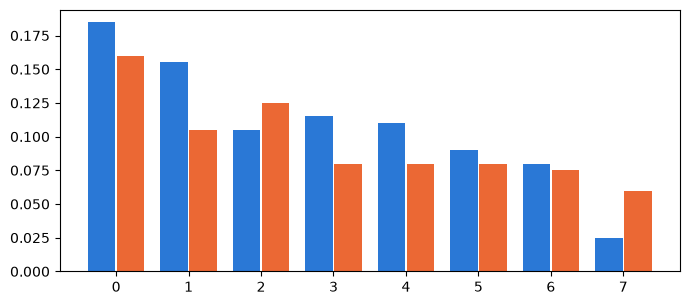

In [ ]:
if RUN_HARDWARE:
    def choice_shares(counts):
        # Share of shots for each on/off choice. int(key, 2) reads Qiskit's bitstring
        # (qubit 0 is the last character) as an index, so bit j = qubit j.
        total = sum(counts.values())
        share = np.zeros(2 ** N)
        for key, c in counts.items():
            share[int(key.replace(" ", ""), 2) & (2 ** N - 1)] += c / total   # low 5 bits = plants
        return share
    
    
    must_on, must_off = locks(plants, list(qaoa_schedule[:HW_HOUR]))
    hw = check_hour(plants, demand[HW_HOUR], reserve[HW_HOUR], qaoa_schedule[HW_HOUR],
                    was_on=qaoa_schedule[HW_HOUR - 1], must_on=must_on, must_off=must_off, verbose=False)
    if hw["best_choice"] is None:
        raise ValueError(f"No valid on/off choice at hour {HW_HOUR}; pick another HW_HOUR")
    best_k = int(np.dot(hw["best_choice"], 2 ** np.arange(N)))
    is_valid = np.array([hour_ok(plants, demand[HW_HOUR], reserve[HW_HOUR], [(k >> i) & 1 for i in range(N)],
                                 must_on, must_off) for k in range(2 ** N)])
    sim_share, ionq_share = choice_shares(sim_counts), choice_shares(counts)
    for name, share in [("simulator (ideal)", sim_share), (device.id, ionq_share)]:
        print(f"{name:<40} valid shots {share[is_valid].sum():5.0%}   best choice {share[best_k]:5.1%}")
    
    top = np.argsort(-(sim_share + ionq_share))[:8]
    x = np.arange(len(top))
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.bar(x - 0.2, sim_share[top], 0.38, color=COLORS["milp"], label="simulator (ideal)")
    ax.bar(x + 0.2, ionq_share[top], 0.38, color=COLORS["qaoa"], label=device.id)
    ax.set_xticks(x, [label(int(k)) + (" (best)" if k == best_k else "") + ("" if is_valid[k] else "\n(not valid)")
                      for k in top], rotation=35, ha="right", fontsize=8)
    ax.set(ylabel="share of shots", title=f"Hour {HW_HOUR}: your qBraid run vs the ideal simulator")
    ax.legend()
    plt.show()
else:
    print("Hardware workflow skipped. Set RUN_HARDWARE=True to enable it.")


## What to have ready for the judges

| Milestone | Be ready to show |
|---|---|
| 1 | Your 6-hour hand schedule and its cost |
| 2 | The MILP's optimal daily cost, and the cheapest-first rule's gap and broken rules |
| 3 | The "Match!" output for at least one hour (one hour, given the hour before), how many of the 24 hours match, and one sentence on how the primer's Max-Cut cost relates to yours |
| 4 | Your QAOA-vs-random table across shots and seeds, your hour-by-hour daily cost, its gap to the MILP, and any rules broken |
| 5 | Your run record (device, job ID, shots, status), the CX count, and the chart, labeled simulator, emulator or QPU |
| 6 | Your five slides (see the main README): who schedules the plants and what they use today, the cost gap and how often answers were valid, total time (including the hardware queue), a sourced value scenario, and what you learned. Rehearse in the time the organizers give you |

Understanding and clarity count more than code. This notebook is a starter: add your own cells, notebooks and tools, and expand as far as you like. If something failed or you couldn't find a solution, say so clearly and explain why.

Due Sunday 9:00 AM: your pitch deck and your code as a ZIP. See "What to submit" in the main README for where.

<a id="other-hybrids"></a>
## Other hybrid methods — optional experiments

The multi-hour improvement and MILP-refinement cells below are different methods from the main reduced-qubit hourly hybrid.


In [ ]:
import time as mh_time
from itertools import combinations as mh_pairs
import numpy as np
from scipy.optimize import minimize as mh_minimize
from qiskit.quantum_info import Statevector as mh_Statevector
from check import check_schedule as mh_check, hour_ok as mh_hour_ok, hour_cost as mh_hour_cost

# ---- Things to try (start here; leave the original notebook unchanged) ----
MH_START = qaoa_schedule.copy()  # Later: multihour_schedule.copy() for another pass.
MH_WINDOW = 4                   # Two plants x four hours = EIGHT qubits.
MH_SHOTS = 64                   # Samples PER WINDOW/PLANT PAIR, not for the day.
MH_SEED = 7
MH_MAX_BLOCKS = 66              # Stop after this many window/pair attempts.
MH_OPT_STEPS = 40               # COBYLA steps, plus a 20-point starting grid.
MH_SAMPLER = "qaoa"             # Also try "random" from the SAME MH_START.
MH_EDIT_PLANTS = ["GAS_CC", "PEAKER_A", "PEAKER_B", "OIL"]


def mh_block_qubo(schedule, start, width, pair):
    """Two free plants; exact dispatch cost per hour + exact startup transitions.

    Bits are absolute on/off states, in time-major order. Minimum up/down times
    are deliberately checked on the FULL DAY after sampling, not encoded here.
    """
    stop, m = start + width, 2 * width
    Q, offset = np.zeros((m, m)), 0.0
    operating, bad = [], []
    for t in range(start, stop):
        costs, invalid = [], []
        for a, b in ((0, 0), (1, 0), (0, 1), (1, 1)):
            on = schedule[t].copy()
            on[list(pair)] = (a, b)
            # was_on=on removes startup costs; add all affected startups below.
            costs.append(mh_hour_cost(plants, demand[t], on, was_on=on))
            invalid.append(not mh_hour_ok(plants, demand[t], reserve[t], on))
        operating.append(np.array(costs))
        bad.append(np.array(invalid, dtype=float))
    # A physically infeasible hour must not win by saving operating/startup costs.
    penalty = 1 + sum(np.ptp(c) for c in operating) + (width + 1) * sum(
        plants[i]["startup_cost"] for i in pair)
    for h, (costs, invalid) in enumerate(zip(operating, bad)):
        e00, e10, e01, e11 = costs + penalty * invalid
        j, k = 2 * h, 2 * h + 1
        offset += e00
        Q[j, j] += e10 - e00
        Q[k, k] += e01 - e00
        Q[j, k] += e11 - e10 - e01 + e00
    for a, i in enumerate(pair):
        startup = plants[i]["startup_cost"]
        for h in range(width):
            j = 2 * h + a
            if h == 0:
                previous = schedule[start - 1, i] if start else int(plants[i]["on_at_start"])
                Q[j, j] += startup * (1 - previous)
            else:
                Q[j, j] += startup
                Q[j - 2, j] -= startup  # startup * x_now * (1 - x_previous)
        if stop < len(schedule):
            # Changing the last free bit can change next hour's startup cost!
            next_on = schedule[stop, i]
            offset += startup * next_on
            Q[m - 2 + a, m - 2 + a] -= startup * next_on
    return Q, offset


def mh_distribution(Q, offset, maxiter):
    """Use the starter's circuit builder with a window-sized energy table.

    The energy table is classical simulator work; it is NOT used to choose a
    winning schedule. Only actually sampled bitstrings can become proposals.
    """
    m = len(Q)
    bits = (np.arange(2 ** m)[:, None] >> np.arange(m)) & 1
    energy = np.einsum("bi,ij,bj->b", bits, Q, bits) + offset
    spread = np.ptp(energy)
    if spread < 1e-9:
        return np.full(2 ** m, 1 / 2 ** m), dict(nfev=0, statevectors=0, rzz=0, energy_states=2 ** m)
    energy = (energy - energy.min()) / spread
    circuit, params = qaoa_circuit(Q, p=1)  # Reuses YOUR existing QAOA cost/mixer code.
    calls = 0
    def probabilities(angles):
        nonlocal calls
        calls += 1
        return mh_Statevector(circuit.assign_parameters(dict(zip(params, angles)))).probabilities()
    def objective(angles):
        return float(probabilities(angles) @ energy)
    grid = [(g, b) for g in np.linspace(.1, 3., 5) for b in np.linspace(.1, 1.5, 4)]
    start_angles = min(grid, key=objective)
    fit = mh_minimize(objective, start_angles, method="COBYLA",
                      options={"maxiter": maxiter, "rhobeg": .2})
    probs = probabilities(fit.x)
    return probs / probs.sum(), dict(nfev=int(fit.nfev), statevectors=calls,
                                    rzz=int(circuit.count_ops().get("rzz", 0)), energy_states=2 ** m)


def improve_day_multihour(initial, window=4, shots=64, seed=7, max_blocks=66,
                          maxiter=40, sampler="qaoa", edit_plants=None, verbose=True):
    """Keep only sampled changes that make the WHOLE valid day cheaper."""
    s = np.asarray(initial)
    T, n = len(demand), len(plants)
    if s.shape != (T, n) or not np.isin(s, [0, 1]).all():
        raise ValueError("initial must be a binary hours-by-plants schedule")
    if len(reserve) != T or not 2 <= window <= min(T, 6):
        raise ValueError("Use matching demand/reserve and a 2–6 hour window (4–12 qubits)")
    if shots < 1 or max_blocks < 1 or maxiter < 1 or sampler not in ("qaoa", "random"):
        raise ValueError("Use positive budgets and sampler='qaoa' or 'random'")
    ids = [p["plant_id"] for p in plants]
    selected = ids if edit_plants is None else list(edit_plants)
    if len(set(selected)) != len(selected) or len(selected) < 2 or any(x not in ids for x in selected):
        raise ValueError("edit_plants must name at least two distinct plants in this fleet")
    pairs = list(mh_pairs([ids.index(x) for x in selected], 2))
    s = s.astype(int).copy()  # Never modify the original daily schedule in place.
    current = mh_check(plants, demand, reserve, s, verbose=False)
    if not current["valid"]:
        raise ValueError("Start from a VALID day; this cell improves schedules rather than repairing invalid starts")
    initial_cost, log = current["total_cost"], []
    rng, began = np.random.default_rng(seed), mh_time.perf_counter()
    starts = list(range(0, T - window + 1, max(1, window // 2)))
    if starts[-1] != T - window:
        starts.append(T - window)
    for start, pair in [(t, pair) for t in starts for pair in pairs][:max_blocks]:
        tick, before = mh_time.perf_counter(), current["total_cost"]
        schedule_before = s.copy()  # Retain context for later analysis or ML window selection.
        Q, offset = mh_block_qubo(s, start, window, pair)
        built = mh_time.perf_counter()
        if sampler == "qaoa":
            probs, work = mh_distribution(Q, offset, maxiter)
        else:
            probs = np.full(2 ** (2 * window), 1 / 2 ** (2 * window))
            work = dict(nfev=0, statevectors=0, rzz=0, energy_states=0)
        tuned = mh_time.perf_counter()
        samples = rng.choice(len(probs), size=shots, p=probs)
        values, multiplicities = np.unique(samples, return_counts=True)
        best, best_result, winner = None, current, None
        valid_draws = improving_draws = valid_unique = improving_unique = 0
        changed_cells = []
        for value, multiplicity in zip(values, multiplicities):
            candidate = s.copy()
            patch = ((int(value) >> np.arange(2 * window)) & 1).reshape(window, 2)
            candidate[start:start + window, list(pair)] = patch
            result = mh_check(plants, demand, reserve, candidate, verbose=False)
            if result["valid"]:
                valid_unique += 1
                valid_draws += int(multiplicity)
                if result["total_cost"] < before - 1e-6:
                    improving_unique += 1
                    improving_draws += int(multiplicity)
                if result["total_cost"] < best_result["total_cost"] - 1e-6:
                    best, best_result, winner = candidate, result, int(value)
        if best is not None:
            changed_cells = [(int(t), ids[i], int(s[t, i]), int(best[t, i]))
                             for t, i in np.argwhere(s != best)]
            s, current = best, best_result
        row = dict(block=len(log), start_hour=start, stop_hour=start + window - 1,
                   plant_ids=[ids[i] for i in pair], qubits=2 * window, shots=shots,
                   unique_samples=len(values), valid_unique=valid_unique,
                   improving_unique=improving_unique, valid_shots=valid_draws,
                   improving_shots=improving_draws, accepted=best is not None,
                   schedule_before=schedule_before,
                   cost_before=before, cost_after=current["total_cost"],
                   saving=before - current["total_cost"], sampled_winner=winner,
                   changed_cells=changed_cells, build_seconds=built-tick,
                   tuning_seconds=tuned-built, seconds=mh_time.perf_counter()-tick, **work)
        log.append(row)
        if verbose and row["accepted"]:
            print(f"Hours {start:02}–{start+window-1:02}, {' + '.join(row['plant_ids'])}: "
                  f"saved ${row['saving']:,.2f}; valid day now ${row['cost_after']:,.2f}", flush=True)
    final = mh_check(plants, demand, reserve, s, verbose=False)
    assert final["valid"] and final["total_cost"] <= initial_cost + 1e-6
    summary = dict(sampler=sampler, seed=seed, initial_cost=initial_cost,
                   final_cost=final["total_cost"], saving=initial_cost-final["total_cost"],
                   improvement_pct=100*(initial_cost-final["total_cost"])/initial_cost,
                   valid=final["valid"], blocks=len(log), accepted=sum(r["accepted"] for r in log),
                   max_qubits=2*window, samples=shots*len(log),
                   classical_full_day_checks=2+sum(r["unique_samples"] for r in log),
                   classical_dispatch_table_calls=4*window*len(log),
                   classical_qubo_states_scored=sum(r["energy_states"] for r in log),
                   statevector_evaluations=sum(r["statevectors"] for r in log),
                   max_logical_rzz=max((r["rzz"] for r in log), default=0),
                   seconds=mh_time.perf_counter()-began)
    if verbose:
        print(f"\n{sampler}: ${initial_cost:,.2f} -> ${summary['final_cost']:,.2f}; "
              f"saved ${summary['saving']:,.2f} ({summary['improvement_pct']:.2f}%), VALID")
        print(f"Accepted {summary['accepted']}/{len(log)} blocks; {2*window} qubits max; "
              f"{summary['seconds']:.1f}s; {summary['samples']} simulated samples")
        print("Classical tuning and checking are counted in multihour_summary. No cloud job was submitted.")
    return s, log, summary


multihour_schedule, multihour_log, multihour_summary = improve_day_multihour(
    MH_START, window=MH_WINDOW, shots=MH_SHOTS, seed=MH_SEED,
    max_blocks=MH_MAX_BLOCKS, maxiter=MH_OPT_STEPS, sampler=MH_SAMPLER,
    edit_plants=MH_EDIT_PLANTS)

# Optional display-only comparison: MILP is never consulted to generate a change.
if "milp_cost" in globals():
    print(f"Gap to your MILP: {100*(multihour_summary['final_cost']/milp_cost-1):.2f}%")
# If your original notebook's plot_schedule helper exists, display the new schedule.
if "plot_schedule" in globals():
    import matplotlib.pyplot as mh_plt
    plot_schedule(multihour_schedule, "After sampled multi-hour improvements")
    mh_plt.show()

### Optional benchmark — QAOA proposals plus MILP refinement

This existing benchmark writes CSV results. It is not needed to run RQ 1–RQ 5.


In [ ]:
from pathlib import Path
import sys

track = PROJECT_ROOT

from hybrid_benchmark import run_hybrid_benchmark, display_hybrid_summary

hybrid_runs, hybrid_summary = run_hybrid_benchmark(
    fleets=(5,),             # Later: (5, 10); 10-plant statevector tuning is much slower.
    horizons=(6, 12, 24),     # Compare scaling with scheduling horizon.
    seeds=(0, 1, 2),          # Initial test; increase to 10+ for more evidence.
    shots=50,                # Sampling shots per hour; optimizer uses exact simulation.
    change_fraction=0.15,    # MILP may flip up to 15% of proposed on/off bits, rounded up.
    time_limit=10,           # Seconds per MILP solve, not an equal total pipeline budget.
    maxiter=30,              # COBYLA evaluations per hourly QAOA fit.
    output_dir=track / "results" / "hybrid_benchmark",
)
display_hybrid_summary(hybrid_summary)
print("Raw runs, summary, schedules, and settings saved in results/hybrid_benchmark/")
print("Gap uses valid solutions only; check reference_proven_optimal in runs.csv.")
print("Local ideal simulation: no QPU or cloud execution costs measured.")


<a id="final-reduced-refinement"></a>
## SUPPORTING COMPARISON — reduced hourly QAOA + sampled multi-hour refinement

**Optional earlier comparison; not part of the current hourly-only seed/shot sweep.** Run the single code cell below using the qBraid-SDK kernel. It is independent of RQ 1–RQ 5 and uses the accompanying `reduced_quantum_method.py`, `rq_classical.py`, and `rq_candidate_checks.py`. Gross demand only: five and ten plants, six seeds each. No solar/wind or cloud/QPU submissions.

1. Construct a day using your reduced hourly QAOA for hours **13–17** and MILP for the other hours. This includes **two construction MILP solves**, the first looking ahead through the full day. The separately scored MILP reference uses the same objective and constraints.
2. Refine two plants over four-hour blocks across the day. Substitute only states forced by the unchanged history before the block. Train a QAOA circuit, sample 64 outcomes, and accept a sampled proposal only if the independent full-day checker finds it feasible and cheaper. **Refinement makes no MILP calls.** It can edit hours previously constructed by MILP.
3. Compare QAOA with uniform random sampling and exhaustive **local block** search from identical starts. Exhaustive blocks examine at most 256 assignments per block; this is not enumeration of every full-day schedule. These controls remain separate from the reported quantum result.

The entire simulated state space is reduced, including stored probabilities. A cap prevents accidental oversized simulations. Fully fixed or constant-energy blocks are marked nonquantum. Every accepted sampled change is logged and replay-checked; failed starting days remain failures rather than being silently repaired.

**Interpretation:** genuine simulated quantum proposals can form a valid hybrid project even when classical proposals also work. A low gap alone does not demonstrate quantum advantage. Exact-statevector angle training is used here; the 64/200 final shots exclude training measurements. Fewer qubits may help future hardware cost, but the current construction already performs full-day MILP work.

Saved output below: all 12 starting days and 36 refined days are valid. The ten-plant mean gap changes from **0.078530%** to **0.010097%** with quantum refinement. Random refinement averages **0.008414%**; exhaustive blocks reach **0%**. Tiny printed negative zeros are floating-point roundoff.



5 plants: MILP reference $327,924.49; quantum hours [13, 14, 15, 16, 17]


seed 7, qaoa  : 0.0000% -> -0.0000%; accepted 0/110; quantum accepted 0; reduced block qubits 4–8; added 11.01s


seed 7, random: 0.0000% -> -0.0000%; accepted 0/110; quantum accepted 0; reduced block qubits 4–8; added 0.18s


seed 7, exact : 0.0000% -> -0.0000%; accepted 0/110; quantum accepted 0; reduced block qubits 4–8; added 0.30s


seed 8, qaoa  : 0.0000% -> -0.0000%; accepted 0/110; quantum accepted 0; reduced block qubits 4–8; added 10.93s


seed 8, random: 0.0000% -> -0.0000%; accepted 0/110; quantum accepted 0; reduced block qubits 4–8; added 0.18s


... (30 outputs left out)

seed 19, random: 0.0649% -> 0.0101%; accepted 1/495; quantum accepted 0; reduced block qubits 1–8; added 1.12s


seed 19, exact : 0.0649% -> 0.0000%; accepted 2/495; quantum accepted 0; reduced block qubits 1–8; added 1.75s



All accepted changes were replayed from recorded sampled outcomes and independently checked.
Saved: /home/jovyan/tn-quantum-hackathon/3-tva-plant-scheduling/results/final_reduced_refinement/20261115T050008381367Z


Plants,Method,Valid / attempted,Mean gap (%),Worst gap (%),Median total (s),Accepted block changes,From quantum samples
5,Reduced hourly only,6/6,0.000000,0.000000,0.78,0,0
5,+ QAOA refinement,6/6,0.000000,0.000000,11.74,0,0
5,+ Random refinement,6/6,0.000000,0.000000,0.97,0,0
5,+ Exhaustive blocks,6/6,0.000000,0.000000,1.07,0,0
10,Reduced hourly only,6/6,0.078530,0.365929,1.76,0,0
10,+ QAOA refinement,6/6,0.010097,0.010097,50.87,2,2
10,+ Random refinement,6/6,0.008414,0.010097,2.90,3,0
10,+ Exhaustive blocks,6/6,0.000000,0.000000,3.56,8,0


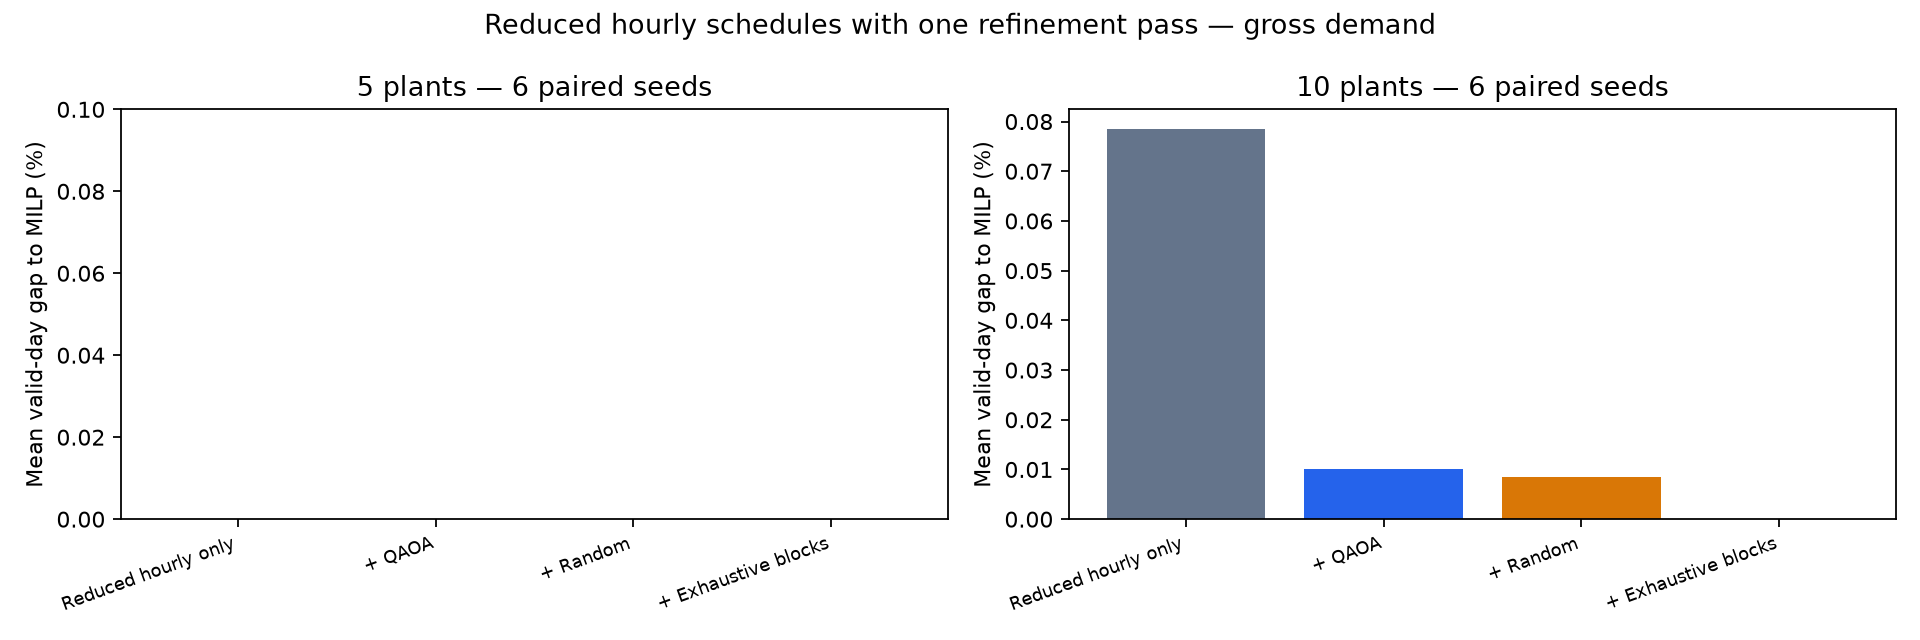

Gap = 100 × (checked daily cost / matching MILP optimum − 1).
Refinement examines two plants over four hours; prefix-forced bits are removed.
QAOA and random use 64 proposals/block; exhaustive checks every reduced block assignment.
The default hourly construction uses TWO MILP solves (including full-day lookahead).
Refinement makes ZERO MILP calls; every accepted proposal is recorded and replay-checked.
Angle tuning uses exact simulated expectations; final finite shots exclude that training work.
Zero-qubit/constant-energy blocks are explicitly marked nonquantum. No full-size probability expansion.
This tests a genuine hybrid quantum algorithm; it does not establish a cost or speed advantage.
Detailed traces, software versions, source hashes, figures and summary: /home/jovyan/tn-quantum-hackathon/3-tva-plant-scheduling/results/final_reduced_refinement/20261115T050008381367Z


In [ ]:
# SUPPORTING COMPARISON — reduced hourly QAOA + sampled multi-hour QAOA refinement
# Run the project-path setup first, then this cell in the qBraid-SDK kernel.
# Local ideal simulation only. Gross demand, no solar/wind, no ramp constraints.
from pathlib import Path
import sys, importlib
from IPython.display import display, HTML, Image
import matplotlib.pyplot as plt
from html import escape

import reduced_quantum_method as final_rq
importlib.reload(final_rq)

FINAL_FLEETS = (5, 10)
FINAL_SEEDS = (7, 8, 9, 17, 18, 19)
FINAL_QUANTUM_HOURS = tuple(range(13, 18))  # 13,14,15,16,17; MILP constructs other hours
FINAL_SHOTS = 200
FINAL_BLOCK_SHOTS = 64
FINAL_CONTROLS = True  # paired random + exhaustive BLOCK search from identical starts
FINAL_MAX_QUBITS = 18  # fail clearly BEFORE an oversized state-space allocation

final_reduced_refinement = final_rq.run_final_study(
    fleets=FINAL_FLEETS, seeds=FINAL_SEEDS, quantum_hours=FINAL_QUANTUM_HOURS,
    shots=FINAL_SHOTS, block_shots=FINAL_BLOCK_SHOTS, max_passes=1,
    controls=FINAL_CONTROLS, max_qubits=FINAL_MAX_QUBITS,
)
final_summary = final_rq.summarize_study(final_reduced_refinement)
labels = {'hourly':'Reduced hourly only', 'qaoa':'+ QAOA refinement',
          'random':'+ Random refinement', 'exact':'+ Exhaustive blocks'}
headers = ['Plants','Method','Valid / attempted','Mean gap (%)','Worst gap (%)',
           'Median total (s)','Accepted block changes','From quantum samples']
body = ''
for r in final_summary:
    # Suppress signed machine-precision zero in presentation only. Raw gaps stay saved.
    shown_mean = 0.0 if abs(r["mean_gap_pct"]) < 1e-10 else r["mean_gap_pct"]
    shown_worst = 0.0 if abs(r["worst_gap_pct"]) < 1e-10 else r["worst_gap_pct"]
    cells = [r['fleet'], labels[r['method']], f"{r['valid']}/{r['attempted']}",
             f"{shown_mean:.6f}", f"{shown_worst:.6f}",
             f"{r['median_total_seconds']:.2f}", r['accepted'], r['quantum_accepted']]
    body += '<tr>' + ''.join('<td>'+escape(str(v))+'</td>' for v in cells) + '</tr>'
display(HTML('<table><thead><tr>'+''.join('<th>'+h+'</th>' for h in headers)+
             '</tr></thead><tbody>'+body+'</tbody></table>'))
fig, axes = plt.subplots(1, len(FINAL_FLEETS), figsize=(12,4), squeeze=False)
for ax, fleet in zip(axes[0], FINAL_FLEETS):
    rows = [r for r in final_summary if r['fleet']==fleet]
    shown_gaps = [0.0 if abs(r['mean_gap_pct']) < 1e-10 else r['mean_gap_pct'] for r in rows]
    ax.bar(range(len(rows)), shown_gaps, color=['#64748b','#2563eb','#d97706','#16a34a'][:len(rows)])
    ax.set_xticks(range(len(rows)), [labels[r['method']].replace(' refinement','') for r in rows], rotation=20, ha='right', fontsize=8)
    if all(gap == 0 for gap in shown_gaps): ax.set_ylim(0, 0.1)
    ax.set(title=f'{fleet} plants — {len(FINAL_SEEDS)} paired seeds', ylabel='Mean valid-day gap to MILP (%)')
fig.suptitle('Reduced hourly schedules with one refinement pass — gross demand')
fig.tight_layout()
final_output = Path(final_reduced_refinement['output_dir'])
fig.savefig(final_output/'comparison.png', dpi=160)
fig.savefig(final_output/'comparison.pdf')
plt.close(fig)
display(Image(filename=str(final_output/'comparison.png')))
print('Gap = 100 × (checked daily cost / matching MILP optimum − 1).')
print('Refinement examines two plants over four hours; prefix-forced bits are removed.')
print('QAOA and random use 64 proposals/block; exhaustive checks every reduced block assignment.')
print('The default hourly construction uses TWO MILP solves (including full-day lookahead).')
print('Refinement makes ZERO MILP calls; every accepted proposal is recorded and replay-checked.')
print('Angle tuning uses exact simulated expectations; final finite shots exclude that training work.')
print('Zero-qubit/constant-energy blocks are explicitly marked nonquantum. No full-size probability expansion.')
print('This tests a genuine hybrid quantum algorithm; it does not establish a cost or speed advantage.')
print('Detailed traces, software versions, source hashes, figures and summary:', final_output)


<a id="milestone-noisy-tuning"></a>
## Milestone 5 — reproducible noise-aware tuning

The completed run is saved in `results/milestone_audit.json`. This code fixes the cost circuit, tests three predeclared mixer-angle offsets on the IonQ `forte-1` noise model, then samples the selected circuit independently. All four jobs were quoted and charged zero credits. It does not claim an exhaustive or globally optimal noisy search.

The cell is disabled by default and refuses to overwrite existing job evidence. It uses the platform Python SDK in qBraid Lab. The main notebook contains offline plots and a separately gated paid-hardware submission. Do not reuse final readout results to choose the training winner.


In [ ]:
RUN_NOISY_TUNING = False
if RUN_NOISY_TUNING:
    import subprocess
    # All code is persisted here; stdin avoids creating another project script.
    noisy_tuning_script = '"""Small, predeclared noisy mixer-angle search; no QPU submission."""\nfrom pathlib import Path\nimport json, re, hashlib, time\nfrom datetime import datetime, timezone\nfrom qbraid.runtime import QbraidProvider\n\nevidence_path = Path(\'results/milestone_audit.json\')\nevidence = json.loads(evidence_path.read_text())\nhardware = evidence[\'hardware\']\nbase_program = hardware[\'program\'][\'data\']\ndevice_id = \'ionq:ionq:sim:simulator\'\nshots = 200\nprovider = QbraidProvider()\ndevice = provider.get_device(device_id)\n\n# Fixed cost angles encode the same Ising objective in every candidate. The\n# positive original gamma makes the weighted phase sum a positive rescaling\n# of that objective (up to an irrelevant constant). Only mixer beta is varied.\nsingles = [(float(a), int(q)) for a, q in re.findall(\n    r\'^rz\\(([-+0-9.eE]+)\\) q\\[(\\d+)\\];$\', base_program, re.M)]\npairs = [(float(a), int(q), int(r)) for a, q, r in re.findall(\n    r\'^rzz\\(([-+0-9.eE]+)\\) q\\[(\\d+)\\], q\\[(\\d+)\\];$\', base_program, re.M)]\nassert len(singles) == 8 and len(pairs) == 28\n\ndef mean_encoded_energy(counts):\n    total = 0.0\n    for bits, count in counts.items():\n        index = int(bits.replace(\' \', \'\'), 2)\n        z = [1-2*((index >> q) & 1) for q in range(8)]\n        value = sum(a*z[q] for a,q in singles) + sum(a*z[q]*z[r] for a,q,r in pairs)\n        total += count * value\n    return total / sum(counts.values())\n\ndef mixer_candidate(delta_beta):\n    return re.sub(r\'^rx\\(([-+0-9.eE]+)\\) q\\[(\\d+)\\];$\',\n                  lambda m: f\'rx({float(m.group(1))+2*delta_beta:.17g}) q[{m.group(2)}];\',\n                  base_program, flags=re.M)\n\ndef save():\n    evidence_path.write_text(json.dumps(evidence, indent=2)+\'\\n\')\n\ndef sample(program, phase):\n    # Recheck pricing immediately before each authorized free simulator job.\n    quote = provider.client.estimate_cost(device_id, shots=shots).model_dump(mode=\'json\')\n    if not quote[\'pricingAvailable\'] or float(quote[\'estimatedCost\']) != 0:\n        raise RuntimeError(\'Simulator is no longer quoted free; stop before submission.\')\n    started = time.perf_counter()\n    job = device.run(program, shots=shots, runtime_options={\'noise_model\':\'forte-1\'})\n    row = dict(phase=phase,job_id=job.id,device=device_id,shots=shots,\n               program=program,program_sha256=hashlib.sha256(program.encode()).hexdigest(),\n               quote=quote)\n    hardware[\'noise_tuning\'][\'jobs\'].append(row)\n    save()  # preserve the ID before waiting; never resubmit a slow job\n    counts = job.result().data.get_counts()\n    row.update(counts=counts,mean_encoded_energy=mean_encoded_energy(counts),\n               wall_seconds=time.perf_counter()-started,\n               metadata=provider.client.get_job(job.id).model_dump(mode=\'json\'))\n    save()\n    print(phase,job.id,\'mean energy\',row[\'mean_encoded_energy\'],flush=True)\n    return row\n\nif hardware.get(\'noise_tuning\',{}).get(\'jobs\'):\n    raise RuntimeError(\'Noisy jobs already recorded; inspect them before any deliberate rerun.\')\nhardware[\'noise_tuning\'] = dict(\n    utc=datetime.now(timezone.utc).isoformat(),beta_offsets=[-0.1,0.0,0.1],\n    selection=\'minimum training mean encoded Ising energy; no holdout-based selection\',\n    training_shots_per_candidate=shots,final_shots=shots,jobs=[])\nsave()\ntraining=[sample(mixer_candidate(delta),f\'training beta shift {delta:+.1f}\')\n          for delta in (-0.1,0.0,0.1)]\nwinner=min(training,key=lambda r:r[\'mean_encoded_energy\'])\nhardware[\'noise_tuning\'][\'selected_training_job\']=winner[\'job_id\']\nhardware[\'noise_tuning\'][\'selected_program\']=winner[\'program\']\nsave()\nholdout=sample(winner[\'program\'],\'independent final noisy readout\')\nhardware[\'noise_tuning\'][\'holdout_job\']=holdout[\'job_id\']\nhardware[\'noise_tuning\'][\'holdout_counts\']=holdout[\'counts\']\nhardware[\'hardware_program\']=winner[\'program\']\nhardware[\'hardware_program_sha256\']=winner[\'program_sha256\']\nsave()\nprint(\'Noise-aware tuning finished. No QPU job submitted.\',flush=True)\n'
    subprocess.run(['/usr/bin/python','-'],input=noisy_tuning_script,text=True,check=True)
else:
    print('Using saved noisy-tuning evidence; no simulator jobs submitted.')


## Earlier IonQ submission workflow

Preserved for reproducibility; submission and refresh remain disabled. The completed hardware comparison is in [Milestone 5](../milestones/05_hardware_results.ipynb).

Local ideal: 200 shots; feasible 55.5%; best hourly commitment 13.0%
IonQ noisy simulator: 200 shots; feasible 49.5%; best hourly commitment 8.0%


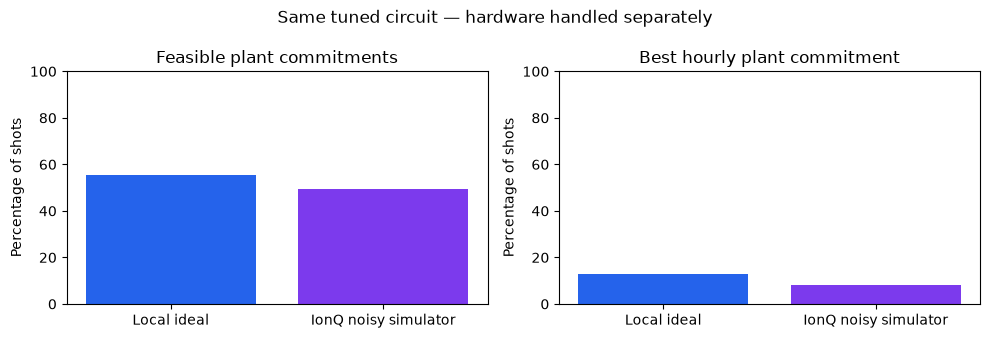

training beta shift -0.1 ionq:ionq:sim:simulator-69e6-qjob-6af97144e538ce0882fae135 cost: 0.0 credits; created-to-ended: 3.54 s
training beta shift +0.0 ionq:ionq:sim:simulator-69e6-qjob-6af97154e538ce0882fae144 cost: 0.0 credits; created-to-ended: 3.574 s
training beta shift +0.1 ionq:ionq:sim:simulator-69e6-qjob-6af97166e538ce0882fae162 cost: 0.0 credits; created-to-ended: 3.414 s
independent final noisy readout ionq:ionq:sim:simulator-69e6-qjob-6af97176e538ce0882fae16f cost: 0.0 credits; created-to-ended: 3.272 s
Hardware status: Managed separately by the user’s other agent; no QPU submitted by this agent.


In [1]:
# Offline plot: loading saved evidence does not submit or poll jobs.
import json
from pathlib import Path
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
from check import load_plants,load_demand,check_hour,hour_ok
audit = json.loads(Path('results/milestone_audit.json').read_text())
hw = audit['hardware']
assert hw['hourly_qubo_verified']
plants = load_plants(); demand,reserve=load_demand()
history=np.asarray(hw['history']);on,off=hw['must_on'],hw['must_off']
hour_check=check_hour(plants,demand[14],reserve[14],history[-1],was_on=history[-1],
                      must_on=on,must_off=off,verbose=False)
best_index=int(np.dot(hour_check['best_choice'],2**np.arange(5)))
valid=np.array([hour_ok(plants,demand[14],reserve[14],[(k>>i)&1 for i in range(5)],on,off)
                for k in range(32)])
series={'Local ideal':hw['tuned_ideal_counts'],
        'IonQ noisy simulator':hw['noise_tuning']['holdout_counts']}
if hw.get('hardware_counts'):series['IonQ QPU']=hw['hardware_counts']
shares={}
for label,counts in series.items():
    share=np.zeros(32)
    for key,count in counts.items():share[int(key.replace(' ',''),2)&31]+=count/sum(counts.values())
    shares[label]=share
    print(f'{label}: {sum(counts.values())} shots; feasible {100*share[valid].sum():.1f}%; '
          f'best hourly commitment {100*share[best_index]:.1f}%')
fig,axes=plt.subplots(1,2,figsize=(10,3.4))
axes[0].bar(list(shares),[100*v[valid].sum() for v in shares.values()],color=['#2563eb','#7c3aed','#16a34a'][:len(shares)])
axes[1].bar(list(shares),[100*v[best_index] for v in shares.values()],color=['#2563eb','#7c3aed','#16a34a'][:len(shares)])
axes[0].set(title='Feasible plant commitments',ylabel='Percentage of shots',ylim=(0,100))
axes[1].set(title='Best hourly plant commitment',ylabel='Percentage of shots',ylim=(0,100))
fig.suptitle('Same tuned circuit — hardware handled separately' if not hw.get('hardware_counts') else 'Same tuned circuit — simulator vs QPU')
fig.tight_layout();plt.show()
for row in hw['noise_tuning']['jobs']:
    stamps=row['metadata']['timeStamps']
    elapsed=(datetime.fromisoformat(stamps['endedAt'].replace('Z','+00:00'))-
             datetime.fromisoformat(stamps['createdAt'].replace('Z','+00:00'))).total_seconds()
    print(row['phase'],row['job_id'],'cost:',row['metadata'].get('cost'),
          'credits; created-to-ended:',round(elapsed,3),'s')
print('Hardware status:',hw['hardware_status'])


In [2]:
# The user’s other agent is handling hardware. Leave this disabled to avoid duplicate jobs.
# OPT-IN REAL HARDWARE ACTION. A normal Run All leaves this disabled.
# Requires explicit approval of the price and the circuit in the audit record.
APPROVE_HARDWARE_SUBMISSION = False
HARDWARE_CREDIT_LIMIT = 0.0

if APPROVE_HARDWARE_SUBMISSION:
    import subprocess,sys
    from pathlib import Path
    # Use qBraid Lab's platform SDK; the notebook SDK can predate cost estimates.
    platform_python = '/usr/bin/python'
    submission_script = r"""
import json,hashlib,sys
from pathlib import Path
from qbraid.runtime import QbraidProvider
path=Path('results/milestone_audit.json');record=json.loads(path.read_text());hw=record['hardware']
if hw.get('hardware_job_id'):raise RuntimeError('Hardware job already recorded; do not submit twice.')
program=hw['hardware_program']
assert hashlib.sha256(program.encode()).hexdigest()==hw['hardware_program_sha256']
provider=QbraidProvider();device_id=hw['hardware_device'];shots=hw['hardware_shots']
quote=provider.client.estimate_cost(device_id,shots=shots).model_dump(mode='json')
if not quote['pricingAvailable'] or float(quote['estimatedCost'])>float(sys.argv[1]):
    raise RuntimeError('Current quote is unavailable or exceeds approved credits.')
device=provider.get_device(device_id)
if 'ONLINE' not in str(device.status()):raise RuntimeError('Hardware is not online; no submission.')
job=device.run(program,shots=shots)
hw.update(hardware_job_id=job.id,hardware_status='submitted',hardware_submission_quote=quote)
path.write_text(json.dumps(record,indent=2)+'\n')
print('Submitted once:',job.id,'estimated credits:',quote['estimatedCost'])
"""
    subprocess.run([platform_python,'-c',submission_script,str(HARDWARE_CREDIT_LIMIT)],check=True)
else:
    print('No hardware submitted here. The user’s other agent is handling milestone 5.')


No hardware submitted here. The user’s other agent is handling milestone 5.


In [5]:
# Optional READ-ONLY refresh after a job ID exists; this never submits a job.
REFRESH_HARDWARE_RESULT = False
if REFRESH_HARDWARE_RESULT:
    import subprocess
    refresh_script = r"""
import json
from pathlib import Path
from qbraid.runtime import QbraidProvider
path=Path('results/milestone_audit.json');record=json.loads(path.read_text());hw=record['hardware']
job_id=hw.get('hardware_job_id')
if not job_id:raise RuntimeError('No hardware job has been submitted.')
p=QbraidProvider();job=p.client.get_job(job_id).model_dump(mode='json')
hw['hardware_metadata']=job;hw['hardware_status']=str(job['status'])
if hw['hardware_status']=='COMPLETED':
    result=p.client.get_job_result(job_id).model_dump(mode='json')
    hw['hardware_result']=result
    hw['hardware_counts']=result['resultData']['measurementCounts']
path.write_text(json.dumps(record,indent=2)+'\n')
print(job_id,hw['hardware_status'])
"""
    subprocess.run(['/usr/bin/python','-c',refresh_script],check=True)
    print('Rerun the offline hardware-report cell to include completed QPU counts.')
